In [1]:
import numpy as np
import matplotlib.pyplot as plt 
from numpy.random import random, randint

### PYFSSA

In [7]:
data = np.load("Potts_q4_binderresolvedsimulation4.2_data.npz")

print(data.files)

T_values = data["T_values"]
L_values = data["L_values"]

results = {}

for L in L_values:

    results[int(L)] = {
        "M": data[f"L{L}_M"],
        "chi": data[f"L{L}_chi"],
        "E": data[f"L{L}_E"],
        "Cv": data[f"L{L}_Cv"],
        "Binder": data[f"L{L}_Binder"]
    }

['T_values', 'L_values', 'L16_M', 'L16_chi', 'L16_E', 'L16_Cv', 'L16_Binder', 'L24_M', 'L24_chi', 'L24_E', 'L24_Cv', 'L24_Binder', 'L32_M', 'L32_chi', 'L32_E', 'L32_Cv', 'L32_Binder', 'L48_M', 'L48_chi', 'L48_E', 'L48_Cv', 'L48_Binder', 'L64_M', 'L64_chi', 'L64_E', 'L64_Cv', 'L64_Binder']


T shape   : (10,)
L shape   : (5,)
chi shape : (5, 10)


C:\Users\Darwin\AppData\Local\Programs\Python\Python310\lib\site-packages\fssa\fssa.py:165: RuntimeWarning: rho_c is out of range
  warnings.warn("rho_c is out of range", RuntimeWarning)



FSSA results
--------------------
Tc       = 0.911614
nu       = 0.690551
gamma    = 1.206150
quality  = 9.950686


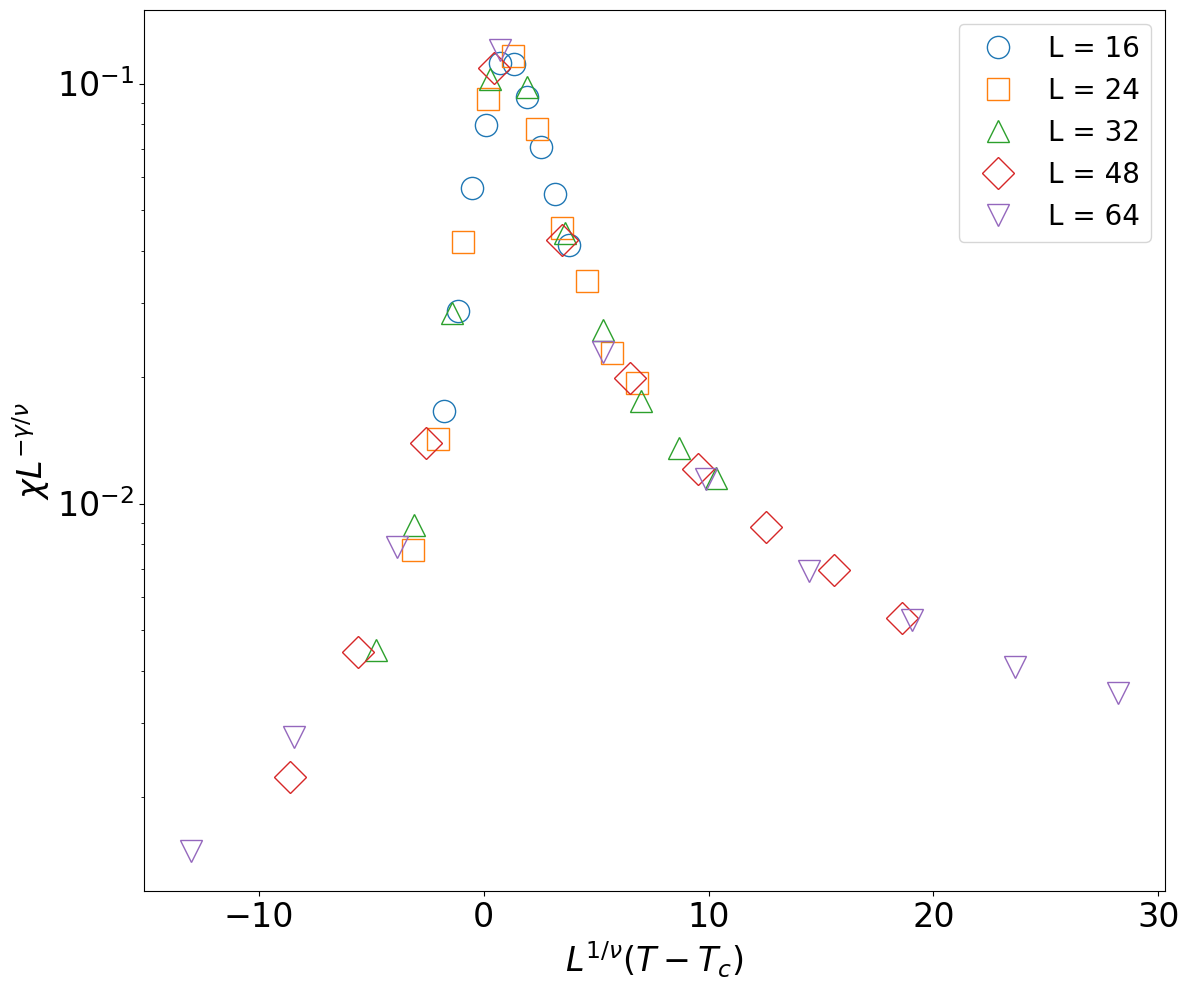

In [13]:
import warnings
import fssa

warnings.filterwarnings(
    "ignore",
    message="`np.int` is a deprecated alias"
)

# --------------------------------------------------
# Load existing simulation data
# --------------------------------------------------

data = np.load("Potts_q4_binderresolvedsimulation4.2_data.npz")

T = np.asarray(data["T_values"], dtype=float)
L = np.asarray(data["L_values"], dtype=float)

chi = np.array([
    data["L16_chi"],
    data["L24_chi"],
    data["L32_chi"],
    data["L48_chi"],
    data["L64_chi"]
], dtype=float)

# Rows = lattice sizes
# Columns = temperatures
print("T shape   :", T.shape)
print("L shape   :", L.shape)
print("chi shape :", chi.shape)

# --------------------------------------------------
# Assumed uncertainty for FSSA
# --------------------------------------------------

relative_error = 0.05
da = relative_error * np.abs(chi)

# --------------------------------------------------
# FSSA
# --------------------------------------------------

result = fssa.autoscale(
    L,
    T,
    chi,
    da,
    rho_c0=0.95,
    nu0=0.67,
    zeta0=1.17
)

print("\nFSSA results")
print("--------------------")
print(f"Tc       = {result.rho:.6f}")
print(f"nu       = {result.nu:.6f}")
print(f"gamma    = {result.zeta:.6f}")
print(f"quality  = {result.fun:.6f}")

# --------------------------------------------------
# Scale data using fitted parameters
# --------------------------------------------------

scaled = fssa.scaledata(
    L,
    T,
    chi,
    da,
    result.rho,
    result.nu,
    result.zeta
)

# --------------------------------------------------
# Plot data collapse
# --------------------------------------------------

plt.figure(figsize=(12, 10))

markers = ['o', 's', '^', 'D', 'v']

for i, Lval in enumerate(L):
    plt.plot(
        scaled.x[i],
        scaled.y[i],
        marker=markers[i],
        ms = 16,
        fillstyle='none',
        linestyle = '',
        label=f"L = {int(Lval)}"
    )
plt.tick_params(axis='both', labelsize=24)
plt.xlabel(r"$L^{1/\nu}(T-T_c)$",fontsize=24)
plt.ylabel(r"$\chi L^{-\gamma/\nu}$",fontsize=24)
#plt.title("FSSA Data Collapse: 4-State Potts Model")
plt.yscale('log')
plt.legend(fontsize=20)
plt.savefig('FSSAq4Potts.pdf')
plt.grid(False)
plt.tight_layout()
plt.show()

In [13]:
from __future__ import division
# configure plotting
%config InlineBackend.rc = {'figure.dpi': 300, 'savefig.dpi': 300, \
                            'figure.figsize': (6, 6 / 1.6), 'font.size': 12, \
                            'figure.facecolor': (1, 1, 1, 0)}
%matplotlib inline

In [17]:
import itertools

from cycler import cycler
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import fssa

C:\Users\Darwin\anaconda3\Lib\site-packages\fssa\fssa.py:241: SyntaxWarning: invalid escape sequence '\l'
  """


ImportError: cannot import name '_status_message' from 'scipy.optimize.optimize' (C:\Users\Darwin\anaconda3\Lib\site-packages\scipy\optimize\optimize.py)

### Binder Cumulant

In [9]:
# Parameters
J = 1.0  # Interaction strength
h = 0  # External field
q =5
sweeps = 10**5# Total Monte Carlo steps
#L = 32
#burn_frac = 2**18
L_values = [16, 24, 32, 48, 64]  # Different lattice sizes to test
# Temperature range
#beta_core = np.linspace(0.4, 1.4, 8)
#delta_beta = beta_core[1] - beta_core[0]
#beta_extra_low = beta_core[0] - delta_beta
#beta_extra_high = beta_core[-1] + delta_beta
#beta_values = np.concatenate([[beta_extra_low], beta_core, [beta_extra_high]])
T_values = np.linspace(0.88, 0.98, 10) 
# Compute corresponding temperature values
beta_values = 1 / T_values

In [5]:
def new_state(L, q):
    return np.random.randint(0, q, size=(L, L))
def E(spins, J=1.0):
    L = spins.shape[0]
    energy_val= 0
    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            # Nearest neighbors with periodic BC
            for dx, dy in [(1,0), (0,1)]:
                nx, ny = (x+dx) % L, (y+dy) % L
                if spins[nx, ny] == s:
                    energy_val -= J
    return energy_val
def magnetization(spins, q=4):
    L = spins.shape[0]
    #N = L*L
    # Represent spin states as unit vectors in complex plane
    angles = 2*np.pi*np.arange(q)/q
    vecs = np.exp(1j * angles)  # q complex unit vectors
    M = np.sum(vecs[spins])     # map spins to complex roots of unity
    return np.abs(M)
def wolff_cluster(spins, T, J=1.0, q=4):
    L = spins.shape[0]
    beta = 1.0/T
    
    # Correct FK bond probability
    p = 1 - np.exp(-beta*J)

    # seed
    i, j = np.random.randint(0, L, size=2)
    seed_state = spins[i, j]

    # build cluster
    cluster = {(i,j)}
    stack = [(i,j)]

    while stack:
        x, y = stack.pop()
        for dx, dy in [(1,0), (-1,0), (0,1), (0,-1)]:
            nx, ny = (x+dx)%L, (y+dy)%L
            if spins[nx, ny] == seed_state and (nx,ny) not in cluster:
                if np.random.rand() < p:
                    cluster.add((nx,ny))
                    stack.append((nx,ny))
    
    # flip to one of q−1 other states
    new_state = np.random.choice([s for s in range(q) if s != seed_state])

    for (x,y) in cluster:
        spins[x,y] = new_state
    
    return spins
def run_simulation(L, T, sweeps=10**6, J=1.0, q=4, burn_frac=0.3, sample_interval = 1):
    spins = new_state(L, q)
    E_arr, M_arr = [], []
    burn_steps = int(burn_frac * sweeps)

    for step in range(sweeps):
        spins = wolff_cluster(spins, T, J)

        if step >= burn_steps and (step - burn_steps) % sample_interval == 0:
            M_arr.append(np.abs(magnetization(spins)))
            E_arr.append(E(spins, J))

    M_arr = np.array(M_arr)
    E_arr = np.array(E_arr)

    # Compute observables
    M_avg = np.mean(M_arr)
    M_avg_per_site = M_avg/L**2
    M_sq_avg = np.mean(M_arr**2)
    chi_M = (M_sq_avg - M_avg**2)/(L**2 * T)

    E_avg = np.mean(E_arr)
    E_avg_per_site = E_avg/L**2
    E_sq_avg = np.mean(E_arr**2)
    C_v = (E_sq_avg - E_avg**2)/(L**2*T**2)

    return M_avg_per_site, chi_M, C_v, E_avg_per_site

In [9]:
import numpy as np
from numpy.random import randint, random

def new_state(L, q=4):
    """Initialize lattice with random spin states 0..q-1."""
    return np.random.randint(0, q, size=(L, L))

def E(spins, J=1.0):
    """Compute Potts energy with nearest-neighbour interactions."""
    L = spins.shape[0]
    energy_val = 0
    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            # Only count right and down to avoid double-counting
            for dx, dy in [(1,0), (0,1)]:
                nx, ny = (x+dx) % L, (y+dy) % L
                if spins[nx, ny] == s:
                    energy_val -= J
    return energy_val

def magnetization(spins, q=4):
    """
    Potts magnetization: scalar order parameter in [0,1].
    """
    L = spins.shape[0]
    #N = L * L
    # count population of each state
    counts = np.bincount(spins.ravel(), minlength=q)
    m_max = np.max(counts)
    M = (q * m_max - 1) / (q - 1)
    return M

def wolff_cluster(spins, T, J=1.0, q=4):
    """
    Perform one Wolff cluster update for q-state Potts model.
    """
    L = spins.shape[0]
    beta = 1.0 / T

    # Pick random seed
    i, j = randint(0, L, size=2)
    seed_state = spins[i, j]

    # Pick a random new spin state (different from seed_state)
    new_state_val = randint(0, q-1)
    if new_state_val >= seed_state:
        new_state_val += 1

    # Bond probability
    p = 1 - np.exp(-beta * J)

    cluster = {(i,j)}
    pocket = {(i,j)}

    while pocket:
        x, y = pocket.pop()
        for dx, dy in [(1,0), (-1,0), (0,1), (0,-1)]:
            nx, ny = (x+dx) % L, (y+dy) % L
            if (nx, ny) not in cluster and spins[nx,ny] == seed_state:
                if random() < p:
                    cluster.add((nx,ny))
                    pocket.add((nx,ny))

    # Flip cluster spins to new state
    for x, y in cluster:
        spins[x, y] = new_state_val

    return spins

def run_simulation(L, T, sweeps=10**5, J=1.0, q=4,
                   burn_frac=0.3, sample_interval=1):
    spins = new_state(L, q)
    E_arr, M_arr = [], []
    burn_steps = int(burn_frac * sweeps)

    for step in range(sweeps):
        spins = wolff_cluster(spins, T, J, q=q)

        if step >= burn_steps and (step - burn_steps) % sample_interval == 0:
            M_arr.append(magnetization(spins, q))
            E_arr.append(E(spins, J))

    M_arr = np.array(M_arr)
    E_arr = np.array(E_arr)

    # Compute observables
    M_avg = np.mean(M_arr)
    M_sq_avg = np.mean(M_arr**2)
    M_avg_per_site = M_avg/L**2
    chi_M = (M_sq_avg - M_avg**2)/(L**2 * T)

    E_avg = np.mean(E_arr)
    E_sq_avg = np.mean(E_arr**2)
    E_avg_per_site = E_avg/L**2
    C_v = (E_sq_avg - E_avg**2)/(L**2*T**2)

    return M_avg_per_site, chi_M, C_v, E_avg_per_site


In [9]:
import numpy as np

# ----------------------------
# Initialize spins
# ----------------------------
def new_state(L, q):
    return np.random.randint(0, q, size=(L, L))


# ----------------------------
# Energy
# ----------------------------
def total_energy(spins, J=1.0):
    L = spins.shape[0]
    E = 0.0

    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            if spins[(x+1) % L, y] == s:
                E -= J
            if spins[x, (y+1) % L] == s:
                E -= J

    return E


# ----------------------------
# Count spins per state
# ----------------------------
def magnetization_counts(spins, q):
    return np.bincount(spins.ravel(), minlength=q)


# ----------------------------
# Wolff cluster update
# ----------------------------
def wolff_cluster_with_size(spins, beta, counts, J, q):

    L = spins.shape[0]
    visited = np.zeros((L, L), dtype=bool)

    # random seed
    x0, y0 = np.random.randint(0, L, size=2)
    old_state = spins[x0, y0]

    # choose new state different from old
    new_state_val = np.random.randint(0, q-1)
    if new_state_val >= old_state:
        new_state_val += 1

    p = 1 - np.exp(-beta * J)

    stack = [(x0, y0)]
    visited[x0, y0] = True
    cluster = []

    while stack:
        x, y = stack.pop()
        cluster.append((x, y))

        for dx, dy in [(1,0), (-1,0), (0,1), (0,-1)]:
            nx, ny = (x + dx) % L, (y + dy) % L

            if not visited[nx, ny] and spins[nx, ny] == old_state:
                if np.random.rand() < p:
                    visited[nx, ny] = True
                    stack.append((nx, ny))

    # flip cluster
    cluster_size = len(cluster)

    for x, y in cluster:
        spins[x, y] = new_state_val

    # update counts
    counts[old_state] -= cluster_size
    counts[new_state_val] += cluster_size

    return spins, counts


# ----------------------------
# Scalar Potts magnetization (FIXED)
# ----------------------------
def magnetization_scalar(counts, N, q):
    m_max = np.max(counts) / N
    return (q * m_max - 1) / (q - 1)


# ----------------------------
# Simulation
# ----------------------------
def run_simulation(L, T, sweeps=10**5, J=1.0, q=4,
                   burn_frac=0.3, sample_interval=1):

    beta = 1.0 / T
    spins = new_state(L, q)
    counts = magnetization_counts(spins, q)

    burn_steps = int(burn_frac * sweeps)

    E_sum = E2_sum = 0.0
    M_sum = M2_sum = M4_sum = 0.0
    n_samples = 0

    N = L * L

    #for step in range(sweeps):

        #spins, counts = wolff_cluster(spins, beta, counts, J, q)
    for sweep in range(sweeps):

        flipped_spins = 0

    # keep flipping clusters until ~N spins updated
        while flipped_spins < N:
            spins, counts, cluster_size = wolff_cluster_with_size(
                spins, beta, counts, J, q
        )
            flipped_spins += cluster_size
        if step >= burn_steps and (step - burn_steps) % sample_interval == 0:

            E = total_energy(spins, J)

            # ✅ FIXED magnetization
            M = magnetization_scalar(counts, N, q)

            E_sum += E
            E2_sum += E * E

            M_sum += M
            M2_sum += M * M
            M4_sum += M**4

            n_samples += 1

    # Averages
    E_avg = E_sum / n_samples
    E2_avg = E2_sum / n_samples

    M_avg = M_sum / n_samples
    M2_avg = M2_sum / n_samples
    M4_avg = M4_sum / n_samples

    # Observables
    M_per_site = M_avg   # already normalized

    chi_M = (M2_avg - M_avg**2) / (T)
    chi_M /= N

    C_v = (E2_avg - E_avg**2) / (T**2)
    C_v /= N

    # Binder cumulant (still usable approximation)
    U = 1 - M4_avg / (3 * M2_avg**2)

    return M_per_site, chi_M, C_v, E_avg / N, U

In [5]:
import numpy as np

# ----------------------------
# Initialize spins
# ----------------------------
def new_state(L, q):
    return np.random.randint(0, q, size=(L, L))


# ----------------------------
# Energy
# ----------------------------
def total_energy(spins, J=1.0):
    L = spins.shape[0]
    E = 0.0

    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            if spins[(x+1) % L, y] == s:
                E -= J
            if spins[x, (y+1) % L] == s:
                E -= J

    return E


# ----------------------------
# Count spins per state
# ----------------------------
def magnetization_counts(spins, q):
    return np.bincount(spins.ravel(), minlength=q)


# ----------------------------
# Wolff cluster update (returns size!)
# ----------------------------
def wolff_cluster_with_size(spins, beta, counts, J, q):

    L = spins.shape[0]
    visited = np.zeros((L, L), dtype=bool)

    x0, y0 = np.random.randint(0, L, size=2)
    old_state = spins[x0, y0]

    new_state_val = np.random.randint(0, q-1)
    if new_state_val >= old_state:
        new_state_val += 1

    p = 1 - np.exp(-beta * J)

    stack = [(x0, y0)]
    visited[x0, y0] = True
    cluster = []

    while stack:
        x, y = stack.pop()
        cluster.append((x, y))

        for dx, dy in [(1,0), (-1,0), (0,1), (0,-1)]:
            nx, ny = (x + dx) % L, (y + dy) % L

            if not visited[nx, ny] and spins[nx, ny] == old_state:
                if np.random.rand() < p:
                    visited[nx, ny] = True
                    stack.append((nx, ny))

    cluster_size = len(cluster)

    for x, y in cluster:
        spins[x, y] = new_state_val

    counts[old_state] -= cluster_size
    counts[new_state_val] += cluster_size

    return spins, counts, cluster_size


# ----------------------------
# Scalar Potts magnetization
# ----------------------------
def magnetization_scalar(counts, N, q):
    m_max = np.max(counts) / N
    return (q * m_max - 1) / (q - 1)


# ----------------------------
# Simulation (FIXED SWEEP LOGIC)
# ----------------------------
def run_simulation(L, T, sweeps=10**5, J=1.0, q=4,
                   burn_frac=0.3, sample_interval=1):

    beta = 1.0 / T
    spins = new_state(L, q)
    counts = magnetization_counts(spins, q)

    burn_steps = int(burn_frac * sweeps)

    E_sum = E2_sum = 0.0
    M_sum = M2_sum = M4_sum = 0.0
    n_samples = 0

    N = L * L

    # 🔴 MAIN FIX: use sweeps, not single cluster updates
    for sweep in range(sweeps):

        flipped_spins = 0

        # grow clusters until ~N spins updated
        while flipped_spins < N:
            spins, counts, cluster_size = wolff_cluster_with_size(
                spins, beta, counts, J, q
            )
            flipped_spins += cluster_size

        # optional: prevent drift in counts
        if sweep % 100 == 0:
            counts = magnetization_counts(spins, q)

        # measurements
        if sweep >= burn_steps and (sweep - burn_steps) % sample_interval == 0:

            E = total_energy(spins, J)
            M = magnetization_scalar(counts, N, q)

            E_sum += E
            E2_sum += E * E

            M_sum += M
            M2_sum += M * M
            M4_sum += M**4

            n_samples += 1

    # Averages
    E_avg = E_sum / n_samples
    E2_avg = E2_sum / n_samples

    M_avg = M_sum / n_samples
    M2_avg = M2_sum / n_samples
    M4_avg = M4_sum / n_samples

    # Observables
    M_per_site = M_avg

    # ✔ Correct scaling for normalized M
    chi_M = (M2_avg - M_avg**2) / T

    C_v = (E2_avg - E_avg**2) / (N * T**2)

    U = 1 - M4_avg / (3 * M2_avg**2)

    return M_per_site, chi_M, C_v, E_avg / N, U

In [29]:
import numpy as np
from numpy.random import randint, random

# ----------------------------
# Initialize
# ----------------------------
def new_state(L, q=4):
    return np.random.randint(0, q, size=(L, L))


def initial_energy(spins, J=1.0):
    L = spins.shape[0]
    E = 0
    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            for dx, dy in [(1,0),(0,1)]:
                nx, ny = (x+dx)%L, (y+dy)%L
                if spins[nx,ny] == s:
                    E -= J
    return E


def initial_counts(spins, q):
    return np.bincount(spins.ravel(), minlength=q)


# ----------------------------
# Fast magnetization (counts-based)
# ----------------------------
def magnetization_from_counts(counts, N, q):
    m_max = np.max(counts) / N
    return (q*m_max - 1)/(q-1)


# ----------------------------
# Wolff with ENERGY UPDATE
# ----------------------------
def wolff_cluster_fast(spins, T, counts, E_current, J=1.0, q=4):

    L = spins.shape[0]
    beta = 1.0 / T

    i, j = randint(0, L, size=2)
    seed_state = spins[i, j]

    new_state_val = randint(0, q-1)
    if new_state_val >= seed_state:
        new_state_val += 1

    p = 1 - np.exp(-beta * J)

    cluster = {(i,j)}
    pocket = {(i,j)}

    while pocket:
        x, y = pocket.pop()
        for dx, dy in [(1,0),(-1,0),(0,1),(0,-1)]:
            nx, ny = (x+dx)%L, (y+dy)%L
            if (nx,ny) not in cluster and spins[nx,ny] == seed_state:
                if random() < p:
                    cluster.add((nx,ny))
                    pocket.add((nx,ny))

    # ----------------------------
    # ENERGY CHANGE (BOUNDARY ONLY)
    # ----------------------------
    dE = 0

    for x, y in cluster:
        for dx, dy in [(1,0),(-1,0),(0,1),(0,-1)]:
            nx, ny = (x+dx)%L, (y+dy)%L

            if (nx,ny) not in cluster:
                # old bond
                if spins[nx,ny] == seed_state:
                    dE += J
                # new bond
                if spins[nx,ny] == new_state_val:
                    dE -= J

    # ----------------------------
    # APPLY FLIP
    # ----------------------------
    cluster_size = len(cluster)

    for x, y in cluster:
        spins[x,y] = new_state_val

    # update counts
    counts[seed_state] -= cluster_size
    counts[new_state_val] += cluster_size

    # update energy
    E_current += dE

    return spins, counts, E_current, cluster_size


# ----------------------------
# Simulation
# ----------------------------
def run_simulation(L, T, sweeps=10**5, J=1.0, q=4,
                   burn_frac=0.3, sample_interval=1):

    spins = new_state(L, q)
    counts = initial_counts(spins, q)
    E_current = initial_energy(spins, J)

    burn_steps = int(burn_frac * sweeps)

    M_sum = M2_sum = M4_sum = 0.0
    E_sum = E2_sum = 0.0

    n_samples = 0
    N = L * L

    for step in range(sweeps):

        flipped = 0

        while flipped < N:
            spins, counts, E_current, cluster_size = wolff_cluster_fast(
    spins, T, counts, E_current, J, q
)
            flipped += cluster_size
        if step >= burn_steps and (step - burn_steps) % sample_interval == 0:

            # FAST magnetization
            #M = magnetization_from_counts(counts, N, q)
            m_max = np.max(counts)          # extensive
            M_ext = (q*m_max - N)/(q-1)     # NOT normalized

            #m = M_ext / N                   # only for plotting

            M_sum += M_ext
            M2_sum += M_ext*M_ext
            M4_sum += M_ext**4
            E = E_current
    
            #M_sum += M
            #M2_sum += M*M
            #M4_sum += M**4

            E_sum += E
            E2_sum += E*E

            n_samples += 1

    # ----------------------------
    # Averages
    # ----------------------------
    M_avg = M_sum / n_samples
    M2_avg = M2_sum / n_samples
    M4_avg = M4_sum / n_samples

    E_avg = E_sum / n_samples
    E2_avg = E2_sum / n_samples

    # ----------------------------
    # Observables
    # ----------------------------
    M_per_site = M_avg / N   # already normalized

    #chi_M = N * (M2_avg - M_avg**2) / T
    chi_M = (M2_avg - M_avg**2) / (N * T)

    C_v = (E2_avg - E_avg**2) / (N * T**2)

    # ✅ Binder cumulant
    U = 1 - (M4_avg / (3 * M2_avg**2))

    return M_per_site, chi_M, C_v, E_avg/N, U

In [15]:
import numpy as np
from numpy.random import randint, random

# ----------------------------
# Initialize
# ----------------------------
def new_state(L, q=4):
    return np.random.randint(0, q, size=(L, L))


def initial_energy(spins, J=1.0):
    L = spins.shape[0]
    E = 0
    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            for dx, dy in [(1,0),(0,1)]:
                nx, ny = (x+dx)%L, (y+dy)%L
                if spins[nx,ny] == s:
                    E -= J
    return E


def initial_counts(spins, q):
    return np.bincount(spins.ravel(), minlength=q)


# ----------------------------
# Fast magnetization (counts-based)
# ----------------------------
#def magnetization_from_counts(counts, N, q):
    #m_max = np.max(counts) / N
    #return (q*m_max - 1)/(q-1)

def magnetization_scalar(counts, N, q):
    #probs = counts / N
    probs = counts.astype(float) / N
    m=np.sum((probs-1.0/q)**2)
    return m* (q / (q -1))
# ----------------------------
# Wolff with ENERGY UPDATE
# ----------------------------
def wolff_cluster_fast(spins, T, counts, E_current, J=1.0, q=4):

    L = spins.shape[0]
    beta = 1.0 / T

    i, j = randint(0, L, size=2)
    seed_state = spins[i, j]

    new_state_val = randint(0, q-1)
    if new_state_val >= seed_state:
        new_state_val += 1

    p = 1 - np.exp(-beta * J)

    cluster = {(i,j)}
    pocket = {(i,j)}

    while pocket:
        x, y = pocket.pop()
        for dx, dy in [(1,0),(-1,0),(0,1),(0,-1)]:
            nx, ny = (x+dx)%L, (y+dy)%L
            if (nx,ny) not in cluster and spins[nx,ny] == seed_state:
                if random() < p:
                    cluster.add((nx,ny))
                    pocket.add((nx,ny))

    # ----------------------------
    # ENERGY CHANGE (BOUNDARY ONLY)
    # ----------------------------
    dE = 0

    for x, y in cluster:
        for dx, dy in [(1,0),(-1,0),(0,1),(0,-1)]:
            nx, ny = (x+dx)%L, (y+dy)%L

            if (nx,ny) not in cluster:
                # old bond
                if spins[nx,ny] == seed_state:
                    dE += J
                # new bond
                if spins[nx,ny] == new_state_val:
                    dE -= J

    # ----------------------------
    # APPLY FLIP
    # ----------------------------
    cluster_size = len(cluster)

    for x, y in cluster:
        spins[x,y] = new_state_val

    # update counts
    counts[seed_state] -= cluster_size
    counts[new_state_val] += cluster_size

    # update energy
    E_current += dE

    return spins, counts, E_current


# ----------------------------
# Simulation
# ----------------------------
def run_simulation(L, T, sweeps=10**5, J=1.0, q=4,
                   burn_frac=0.3, sample_interval=1):

    spins = new_state(L, q)
    counts = initial_counts(spins, q)
    E_current = initial_energy(spins, J)

    burn_steps = int(burn_frac * sweeps)

    M_sum = M2_sum = M4_sum = 0.0
    E_sum = E2_sum = 0.0

    n_samples = 0
    N = L * L

    for step in range(sweeps):

        #flipped = 0

        #while flipped < N:
        spins, counts, E_current = wolff_cluster_fast(
    spins, T, counts, E_current, J, q
)
            #flipped += cluster_size
        if step >= burn_steps and (step - burn_steps) % sample_interval == 0:

            # FAST magnetization
            #M = magnetization_from_counts(counts, N, q)
            #m_max = np.max(counts)          # extensive
            #M_ext = (q*m_max - N)/(q-1)     # NOT normalized
            M = magnetization_scalar(counts, N, q)
            #m = M_ext / N                   # only for plotting

            M_sum += M
            M2_sum += M**2
            M4_sum += M**4
            E = E_current
    
            #M_sum += M
            #M2_sum += M*M
            #M4_sum += M**4

            E_sum += E
            E2_sum += E*E

            n_samples += 1
    
    # ----------------------------
    # Averages
    # ----------------------------
    M_avg = M_sum / n_samples
    M2_avg = M2_sum / n_samples
    M4_avg = M4_sum / n_samples

    E_avg = E_sum / n_samples
    E2_avg = E2_sum / n_samples

    # ----------------------------
    # Observables
    # ----------------------------
    M_per_site = M_avg   # already normalized

    #chi_M = N * (M2_avg - M_avg**2) / T
    chi_M = N * (M2_avg - M_avg**2) /  T

    C_v = (E2_avg - E_avg**2) / (N * T**2)

    # ✅ Binder cumulant
    #U = 1 - (M4_avg / (3 * M2_avg**2))
    if M2_avg > 1e-12:
        U=1- (M4_avg / (3 * M2_avg**2))
    else:
        U=0.0
    return M_per_site, chi_M, C_v, E_avg/N, U

In [56]:
import numpy as np
from numpy.random import randint, random

# ----------------------------
# Initialize
# ----------------------------
def new_state(L, q=4):
    return np.random.randint(0, q, size=(L, L))


def initial_energy(spins, J=1.0):
    L = spins.shape[0]
    E = 0
    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            for dx, dy in [(1,0),(0,1)]:
                nx, ny = (x+dx)%L, (y+dy)%L
                if spins[nx,ny] == s:
                    E -= J
    return E


def initial_counts(spins, q):
    return np.bincount(spins.ravel(), minlength=q)


# ----------------------------
# ✅ Majority Potts order parameter
# ----------------------------
def magnetization_majority(counts, N, q):
    m_max = np.max(counts) / N
    return (q * m_max - 1) / (q - 1)


# ----------------------------
# Wolff cluster update
# ----------------------------
def wolff_cluster_fast(spins, T, counts, E_current, J=1.0, q=4):

    L = spins.shape[0]
    beta = 1.0 / T

    i, j = randint(0, L, size=2)
    seed_state = spins[i, j]

    new_state_val = randint(0, q-1)
    if new_state_val >= seed_state:
        new_state_val += 1

    p = 1 - np.exp(-beta * J)

    cluster = {(i,j)}
    pocket = {(i,j)}

    while pocket:
        x, y = pocket.pop()
        for dx, dy in [(1,0),(-1,0),(0,1),(0,-1)]:
            nx, ny = (x+dx)%L, (y+dy)%L
            if (nx,ny) not in cluster and spins[nx,ny] == seed_state:
                if random() < p:
                    cluster.add((nx,ny))
                    pocket.add((nx,ny))

    # ----------------------------
    # Energy change (boundary only)
    # ----------------------------
    dE = 0

    for x, y in cluster:
        for dx, dy in [(1,0),(-1,0),(0,1),(0,-1)]:
            nx, ny = (x+dx)%L, (y+dy)%L

            if (nx,ny) not in cluster:
                if spins[nx,ny] == seed_state:
                    dE += J
                if spins[nx,ny] == new_state_val:
                    dE -= J

    # ----------------------------
    # Apply flip
    # ----------------------------
    cluster_size = len(cluster)

    for x, y in cluster:
        spins[x,y] = new_state_val

    # update counts
    counts[seed_state] -= cluster_size
    counts[new_state_val] += cluster_size

    # update energy
    E_current += dE

    return spins, counts, E_current


# ----------------------------
# Simulation
# ----------------------------
def run_simulation(L, T, sweeps=10**5, J=1.0, q=4,
                   burn_frac=0.4, sample_interval=1):

    spins = new_state(L, q)
    counts = initial_counts(spins, q)
    E_current = initial_energy(spins, J)

    burn_steps = int(burn_frac * sweeps)

    M_sum = M2_sum = M4_sum = 0.0
    E_sum = E2_sum = 0.0

    n_samples = 0
    N = L * L

    for step in range(sweeps):

        spins, counts, E_current = wolff_cluster_fast(
            spins, T, counts, E_current, J, q
        )

        if step >= burn_steps and (step - burn_steps) % sample_interval == 0:

            # ✅ Majority Potts magnetization
            M = magnetization_majority(counts, N, q)

            M_sum += M
            M2_sum += M*M
            M4_sum += M**4

            E = E_current
            E_sum += E
            E2_sum += E*E

            n_samples += 1

    # ----------------------------
    # Averages
    # ----------------------------
    M_avg = M_sum / n_samples
    M2_avg = M2_sum / n_samples
    M4_avg = M4_sum / n_samples

    E_avg = E_sum / n_samples
    E2_avg = E2_sum / n_samples

    # ----------------------------
    # Observables
    # ----------------------------
    M_per_site = M_avg   # already normalized

    # ✅ Susceptibility (correct)
    chi_M = N * (M2_avg - M_avg**2) / T

    # Specific heat
    C_v = (E2_avg - E_avg**2) / (N * T**2)

    # ✅ Binder cumulant (safe)
    if M2_avg > 1e-12:
        U = 1 - (M4_avg / (3 * M2_avg**2))
    else:
        U = 0.0

    return M_per_site, chi_M, C_v, E_avg/N, U

In [33]:
# Initialize # ----------------------------
def new_state(L, q=4):
    return np.random.randint(0, q, size=(L, L))
def initial_energy(spins, J=1.0): 
    L = spins.shape[0] 
    E = 0 
    for x in range(L): 
        for y in range(L): 
            s = spins[x, y] 
            for dx, dy in [(1,0),(0,1)]: 
                nx, ny = (x+dx)%L, (y+dy)%L 
                if spins[nx,ny] == s: 
                    E -= J 
    return E
def initial_counts(spins, q): 
        return np.bincount(spins.ravel(), minlength=q) 
# ---------------------------- # Fast magnetization (counts-based) # ----------------------------
def magnetization_vector(counts, N, q): 
        probs = counts / N 
# complex representation of Potts states
        angles = 2 * np.pi * np.arange(q) / q 
        mx = np.sum(probs * np.cos(angles)) 
        my = np.sum(probs * np.sin(angles)) 
        return np.sqrt(mx**2 + my**2)
# Wolff with ENERGY UPDATE # ---------------------------- 
def wolff_cluster_fast(spins, T, counts, E_current, J=1.0, q=4): 
    L = spins.shape[0] 
    beta = 1.0 / T 
    i, j = randint(0, L, size=2) 
    seed_state = spins[i, j] 
    new_state_val = randint(0, q-1) 
    if new_state_val >= seed_state: 
        new_state_val += 1 
    p = 1 - np.exp(-beta * J)
    cluster = {(i,j)} 
    pocket = {(i,j)} 
    while pocket: 
        x, y = pocket.pop() 
        for dx, dy in [(1,0),(-1,0),(0,1),(0,-1)]: 
            nx, ny = (x+dx)%L, (y+dy)%L 
            if (nx,ny) not in cluster and spins[nx,ny] == seed_state: 
                if random() < p: 
                    cluster.add((nx,ny)) 
                    pocket.add((nx,ny))
# ENERGY CHANGE (BOUNDARY ONLY) # ---------------------------- 
    dE = 0 
    for x, y in cluster: 
        for dx, dy in [(1,0),(-1,0),(0,1),(0,-1)]: 
            nx, ny = (x+dx)%L, (y+dy)%L 
            if (nx,ny) not in cluster: 
                # old bond 
                if spins[nx,ny] == seed_state: 
                    dE += J 
                # new bond 
                if spins[nx,ny] == new_state_val: 
                    dE -= J 
# ---------------------------- # APPLY FLIP # ---------------------------- 
        cluster_size = len(cluster)
        for x, y in cluster: 
            spins[x,y] = new_state_val 
# update counts 
        counts[seed_state] -= cluster_size 
        counts[new_state_val] += cluster_size 
# update energy 
        E_current += dE 
        return spins, counts, E_current 
# ---------------------------- # Simulation # ---------------------------- 
def run_simulation(L, T, sweeps=10**5, J=1.0, q=4, burn_frac=0.3, sample_interval=1): 
    spins = new_state(L, q) 
    counts = initial_counts(spins, q) 
    E_current = initial_energy(spins, J)
    burn_steps = int(burn_frac * sweeps) 
    M_sum = M2_sum = M4_sum = 0.0 
    E_sum = E2_sum = 0.0 
    n_samples = 0 
    N = L * L 
    for step in range(sweeps): 
        spins, counts, E_current = wolff_cluster_fast( spins, T, counts, E_current, J, q ) 
#flipped += cluster_size 
        if step >= burn_steps and (step - burn_steps) % sample_interval == 0: 
        # FAST magnetization #M = magnetization_from_counts(counts, N, q) #m_max = np.max(counts) # extensive #M_ext = (q*m_max - N)/(q-1) # NOT normalized 
            M = magnetization_vector(counts, N, q) #m = M_ext / N # only for plotting 
            M_sum += M 
            M2_sum += M**2 
            M4_sum += M**4 
            E = E_current #M_sum += M #M2_sum += M*M #M4_sum += M**4 
            E_sum += E 
            E2_sum += E*E 
            n_samples += 1
# ---------------------------- # Averages # ---------------------------- 
    M_avg = M_sum / n_samples 
    M2_avg = M2_sum / n_samples 
    M4_avg = M4_sum / n_samples 
    E_avg = E_sum / n_samples 
    E2_avg = E2_sum / n_samples 
# ---------------------------- # Observables # ---------------------------- 
    M_per_site = M_avg # already normalized #chi_M = N * (M2_avg - M_avg**2) / T 
    chi_M = N * (M2_avg - M_avg**2) / T 
    C_v = (E2_avg - E_avg**2) / (N * T**2) 
# ✅ Binder cumulant 
    U = 1 - (M4_avg / (3 * M2_avg**2)) 
    return M_per_site, chi_M, C_v, E_avg/N, U

In [5]:
import numpy as np
from numpy.random import randint, random

# ----------------------------
# Initialize
# ----------------------------
def new_state(L, q=5):
    return np.random.randint(0, q, size=(L, L))


def initial_energy(spins, J=1.0):
    L = spins.shape[0]
    E = 0
    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            for dx, dy in [(1,0),(0,1)]:
                nx, ny = (x+dx)%L, (y+dy)%L
                if spins[nx,ny] == s:
                    E -= J
    return E

# Count the spins for each state
def initial_counts(spins, q):
    return np.bincount(spins.ravel(), minlength=q)


# ----------------------------
# Vector magnetization-mapping Potts states to angles
# ----------------------------
def magnetization_vector(counts, N, q):
    probs = counts / N
    angles = 2 * np.pi * np.arange(q) / q
    mx = np.sum(probs * np.cos(angles))
    my = np.sum(probs * np.sin(angles))
    return np.sqrt(mx**2 + my**2) # One state dominates at low temp, it points to 1 or if the states are equally populated then 0


# ----------------------------
# ✅ FIXED Wolff (correct energy)
# ----------------------------
def wolff_cluster_fast(spins, T, counts, E_current, J=1.0, q=4):

    L = spins.shape[0]
    beta = 1.0 / T

    i, j = randint(0, L, size=2)
    seed_state = spins[i, j]

    new_state_val = randint(0, q-1)
    if new_state_val >= seed_state:
        new_state_val += 1

    p = 1 - np.exp(-beta * J)

    cluster = {(i,j)}
    pocket = {(i,j)}

    while pocket:
        x, y = pocket.pop()
        for dx, dy in [(1,0),(-1,0),(0,1),(0,-1)]:
            nx, ny = (x+dx)%L, (y+dy)%L
            if (nx,ny) not in cluster and spins[nx,ny] == seed_state:
                if random() < p:
                    cluster.add((nx,ny))
                    pocket.add((nx,ny))

    # ----------------------------
    # ✅ CORRECT energy change
    # ----------------------------
    dE = 0

    for x, y in cluster:
        for dx, dy in [(1,0),(-1,0),(0,1),(0,-1)]:
            nx, ny = (x+dx)%L, (y+dy)%L

            if (nx,ny) not in cluster:
                if spins[nx,ny] == seed_state:
                    dE += J      # bond broken (−J → 0)

                if spins[nx,ny] == new_state_val:
                    dE -= J      # bond formed (0 → −J)

    # ----------------------------
    # Apply flip
    # ----------------------------
    cluster_size = len(cluster)

    for x, y in cluster:
        spins[x,y] = new_state_val

    counts[seed_state] -= cluster_size
    counts[new_state_val] += cluster_size

    E_current += dE

    return spins, counts, E_current


# ----------------------------
# Simulation
# ----------------------------
def run_simulation(L, T, sweeps=10**5, J=1.0, q=5,
                   burn_frac=0.3, sample_interval=1):

    spins = new_state(L, q)
    counts = initial_counts(spins, q)
    E_current = initial_energy(spins, J)

    burn_steps = int(burn_frac * sweeps)

    M_sum = M2_sum = M4_sum = 0.0
    E_sum = E2_sum = 0.0

    n_samples = 0
    N = L * L

    for step in range(sweeps):

        spins, counts, E_current = wolff_cluster_fast(
            spins, T, counts, E_current, J, q
        )

        if step >= burn_steps and (step - burn_steps) % sample_interval == 0:

            M = magnetization_vector(counts, N, q)

            M_sum += M
            M2_sum += M**2
            M4_sum += M**4

            E = E_current
            E_sum += E
            E2_sum += E*E

            n_samples += 1

    # ----------------------------
    # Averages
    # ----------------------------
    M_avg = M_sum / n_samples
    M2_avg = M2_sum / n_samples
    M4_avg = M4_sum / n_samples

    E_avg = E_sum / n_samples
    E2_avg = E2_sum / n_samples

    # ----------------------------
    # Observables
    # ----------------------------
    M_per_site = M_avg

    chi_M = N * (M2_avg - M_avg**2) / T
    C_v = (E2_avg - E_avg**2) / (N * T**2)

    U = 1 - (M4_avg / (3 * M2_avg**2))

    return M_per_site, chi_M, C_v, E_avg/N, U

In [5]:
import numpy as np
from numpy.random import randint, random

# ----------------------------
# Initialize
# ----------------------------
def new_state(L, q=5):
    return np.random.randint(0, q, size=(L, L))


def initial_energy(spins, J=1.0):
    L = spins.shape[0]
    E = 0
    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            for dx, dy in [(1,0),(0,1)]:  # avoid double counting
                nx, ny = (x+dx)%L, (y+dy)%L
                if spins[nx, ny] == s:
                    E -= J
    return E


def initial_counts(spins, q):
    return np.bincount(spins.ravel(), minlength=q)


# ----------------------------
# Vector magnetization
# ----------------------------
def magnetization_vector(counts, N, q):
    probs = counts / N
    angles = 2 * np.pi * np.arange(q) / q
    mx = np.sum(probs * np.cos(angles))
    my = np.sum(probs * np.sin(angles))
    return np.sqrt(mx**2 + my**2)


# ----------------------------
# Wolff cluster update
# ----------------------------
def wolff_cluster_fast(spins, T, counts, E_current, J=1.0, q=5):

    L = spins.shape[0]
    beta = 1.0 / T

    # random seed
    i, j = randint(0, L, size=2)
    seed_state = spins[i, j]

    # choose different state
    new_state_val = randint(0, q-1)
    if new_state_val >= seed_state:
        new_state_val += 1

    p = 1 - np.exp(-beta * J)

    cluster = {(i, j)}
    pocket = {(i, j)}

    # grow cluster
    while pocket:
        x, y = pocket.pop()
        for dx, dy in [(1,0),(-1,0),(0,1),(0,-1)]:
            nx, ny = (x+dx)%L, (y+dy)%L

            if (nx, ny) not in cluster and spins[nx, ny] == seed_state:
                if random() < p:
                    cluster.add((nx, ny))
                    pocket.add((nx, ny))

    # ----------------------------
    # Energy change (boundary only)
    # ----------------------------
    dE = 0

    for x, y in cluster:
        for dx, dy in [(1,0),(-1,0),(0,1),(0,-1)]:
            nx, ny = (x+dx)%L, (y+dy)%L

            if (nx, ny) not in cluster:
                if spins[nx, ny] == seed_state:
                    dE += J
                if spins[nx, ny] == new_state_val:
                    dE -= J

    # apply flip
    cluster_size = len(cluster)

    for x, y in cluster:
        spins[x, y] = new_state_val

    counts[seed_state] -= cluster_size
    counts[new_state_val] += cluster_size

    E_current += dE

    return spins, counts, E_current


# ----------------------------
# Simulation
# ----------------------------
def run_simulation(L, T, sweeps=100000, J=1.0, q=5,
                   burn_frac=0.3, sample_interval=1,
                   collect_histogram=False):

    spins = new_state(L, q)
    counts = initial_counts(spins, q)
    E_current = initial_energy(spins, J)

    burn_steps = int(burn_frac * sweeps)

    M_sum = M2_sum = M4_sum = 0.0
    E_sum = E2_sum = 0.0

    energy_samples = []  # 🔥 important for q=5

    n_samples = 0
    N = L * L

    for step in range(sweeps):

        spins, counts, E_current = wolff_cluster_fast(
            spins, T, counts, E_current, J, q
        )

        if step >= burn_steps and (step - burn_steps) % sample_interval == 0:

            M = magnetization_vector(counts, N, q)

            M_sum += M
            M2_sum += M*M
            M4_sum += M**4

            E = E_current
            E_sum += E
            E2_sum += E*E

            if collect_histogram:
                energy_samples.append(E / N)

            n_samples += 1

    # ----------------------------
    # Averages
    # ----------------------------
    M_avg = M_sum / n_samples
    M2_avg = M2_sum / n_samples
    M4_avg = M4_sum / n_samples

    E_avg = E_sum / n_samples
    E2_avg = E2_sum / n_samples

    # ----------------------------
    # Observables
    # ----------------------------
    M_per_site = M_avg

    chi_M = N * (M2_avg - M_avg**2) / T
    C_v = (E2_avg - E_avg**2) / (N * T**2)

    # safe Binder
    if M2_avg > 1e-14:
        U = 1 - (M4_avg / (3 * M2_avg**2))
    else:
        U = 0.0

    if collect_histogram:
        return M_per_site, chi_M, C_v, E_avg/N, U, np.array(energy_samples)

    return M_per_site, chi_M, C_v, E_avg/N, U

In [15]:
# Storage
results = {"M_x": [], "chi_M": [], "C_v": [], "E_avg": []}

for T in T_values:
    print(f"Running simulations for T={T:.2f} (Beta={1/T:.2f})...")
    M_avg_per_site, chi_M, C_v, E_avg_per_site = run_simulation(L, T, sweeps, J, burn_frac=0.3)
    results["M_x"].append(M_avg_per_site)
    results["chi_M"].append(chi_M)
    results["C_v"].append(C_v)
    results["E_avg"].append(E_avg_per_site)

Running simulations for T=1.05 (Beta=0.95)...
Running simulations for T=0.98 (Beta=1.02)...
Running simulations for T=0.91 (Beta=1.09)...
Running simulations for T=0.86 (Beta=1.17)...
Running simulations for T=0.81 (Beta=1.24)...
Running simulations for T=0.76 (Beta=1.31)...
Running simulations for T=0.72 (Beta=1.38)...
Running simulations for T=0.69 (Beta=1.46)...
Running simulations for T=0.65 (Beta=1.53)...
Running simulations for T=0.62 (Beta=1.60)...


In [7]:
import time
# --- Storage ---
results = {
    L: {
        "M": [],
        "chi": [],
        "E": [],
        "Cv": [],
        "Binder": []
    }
    for L in L_values
}

# --- Loop over sizes and temperatures ---
for L in L_values:
    print(f"\nRunning simulations for L = {L}")

    for T in T_values:
        start_time = time.time()

        M, chi, E, Cv, U = run_simulation(
            L, T,
            sweeps=sweeps,
            J=J,
            burn_frac=0.3, q=4, sample_interval=1
        )

        results[L]["M"].append(M)
        results[L]["chi"].append(chi)
        results[L]["E"].append(E)
        results[L]["Cv"].append(Cv)
        results[L]["Binder"].append(U)

        elapsed = time.time() - start_time

        print(f"T = {T:.3f} | U = {U:.4f} | time = {elapsed/60:.2f} min")


for L in L_values:
    for key in results[L]:
        results[L][key] = np.array(results[L][key])
        
save_dict = {
    "T_values": np.array(T_values),
    "L_values": np.array( L_values)
}

for L in L_values:
    for key in results[L]:
        save_dict[f"L{L}_{key}"] = results[L][key]

np.savez_compressed("Potts_q5_binder_data1.npz", **save_dict)
print("\nData saved successfully.")


Running simulations for L = 16
T = 0.880 | U = 0.6562 | time = 1.91 min
T = 0.891 | U = 0.6497 | time = 1.82 min
T = 0.902 | U = 0.6328 | time = 1.67 min
T = 0.913 | U = 0.6077 | time = 1.47 min
T = 0.924 | U = 0.5465 | time = 1.13 min
T = 0.936 | U = 0.4586 | time = 0.80 min
T = 0.947 | U = 0.3789 | time = 0.60 min
T = 0.958 | U = 0.3288 | time = 0.50 min
T = 0.969 | U = 0.2848 | time = 0.37 min
T = 0.980 | U = 0.2984 | time = 0.32 min

Running simulations for L = 24
T = 0.880 | U = 0.6617 | time = 4.15 min
T = 0.891 | U = 0.6574 | time = 4.17 min
T = 0.902 | U = 0.6425 | time = 3.59 min
T = 0.913 | U = 0.5880 | time = 3.20 min
T = 0.924 | U = 0.4621 | time = 1.73 min
T = 0.936 | U = 0.2993 | time = 0.91 min
T = 0.947 | U = 0.2718 | time = 0.59 min
T = 0.958 | U = 0.2418 | time = 0.44 min
T = 0.969 | U = 0.2883 | time = 0.33 min
T = 0.980 | U = 0.3130 | time = 0.29 min

Running simulations for L = 32
T = 0.880 | U = 0.6636 | time = 7.93 min
T = 0.891 | U = 0.6606 | time = 7.70 min
T 

In [3]:
data = np.load("Potts_q5_binder_data1.npz")
print(data.files)
L_values = [16, 24, 32, 48, 64]   # set your lattice sizes

results = {}

for L in L_values:

    results[L] = {
        #"T": data[f"L{L}_T"],
        "M": data[f"L{L}_M"],
        "chi": data[f"L{L}_chi"],
        "E": data[f"L{L}_E"],
        "Cv": data[f"L{L}_Cv"],
        "Binder": data[f"L{L}_Binder"]
    }

['T_values', 'L_values', 'L16_M', 'L16_chi', 'L16_E', 'L16_Cv', 'L16_Binder', 'L24_M', 'L24_chi', 'L24_E', 'L24_Cv', 'L24_Binder', 'L32_M', 'L32_chi', 'L32_E', 'L32_Cv', 'L32_Binder', 'L48_M', 'L48_chi', 'L48_E', 'L48_Cv', 'L48_Binder', 'L64_M', 'L64_chi', 'L64_E', 'L64_Cv', 'L64_Binder']


In [5]:
data = np.load("Potts_q4_binderresolvedsimulation4.2_data.npz")
print(data.files)
L_values = [16, 24, 32, 48, 64]   # set your lattice sizes

results = {}

for L in L_values:

    results[L] = {
        #"T": data[f"L{L}_T"],
        "M": data[f"L{L}_M"],
        "chi": data[f"L{L}_chi"],
        "E": data[f"L{L}_E"],
        "Cv": data[f"L{L}_Cv"],
        "Binder": data[f"L{L}_Binder"]
    }

['T_values', 'L_values', 'L16_M', 'L16_chi', 'L16_E', 'L16_Cv', 'L16_Binder', 'L24_M', 'L24_chi', 'L24_E', 'L24_Cv', 'L24_Binder', 'L32_M', 'L32_chi', 'L32_E', 'L32_Cv', 'L32_Binder', 'L48_M', 'L48_chi', 'L48_E', 'L48_Cv', 'L48_Binder', 'L64_M', 'L64_chi', 'L64_E', 'L64_Cv', 'L64_Binder']


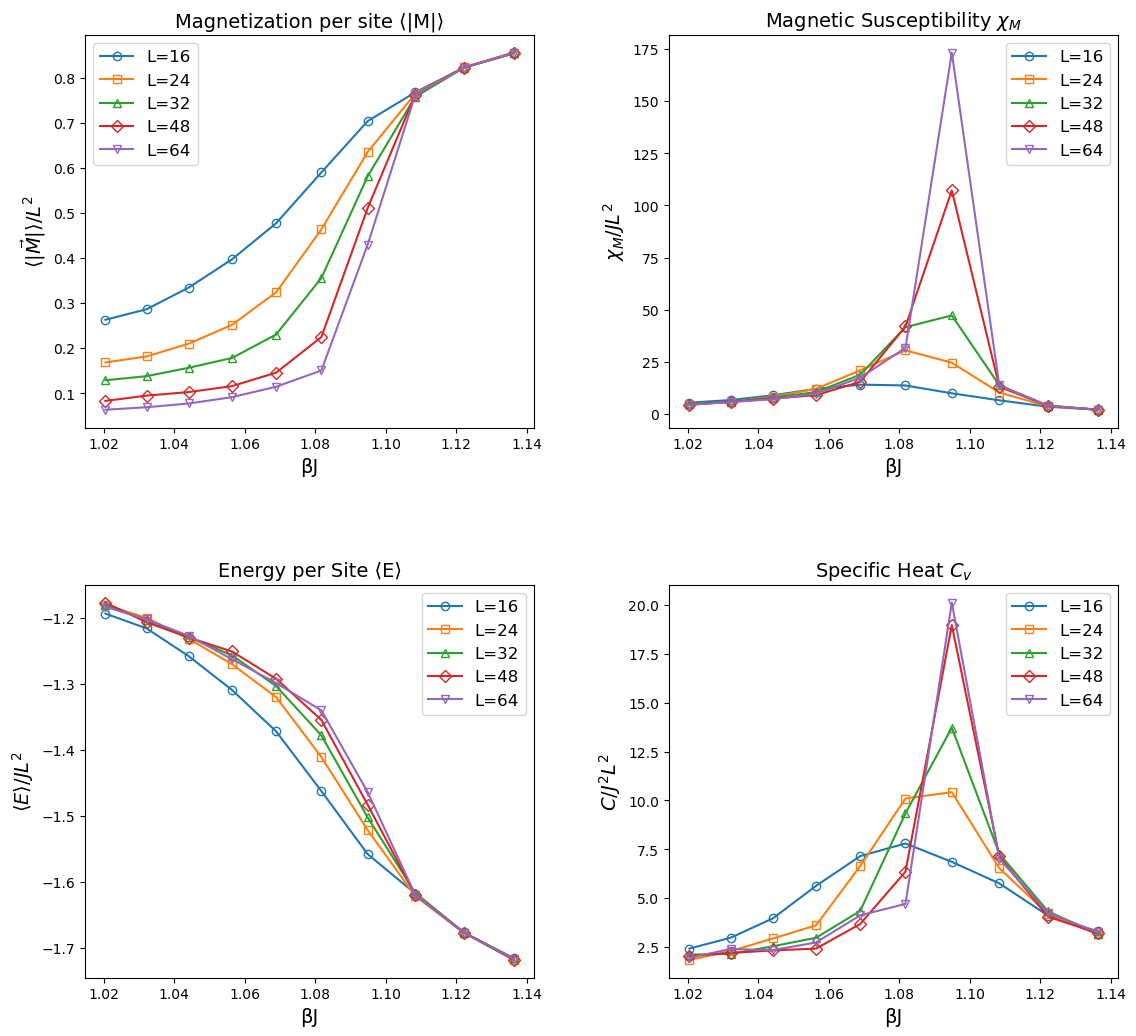

In [11]:
beta_values = 1/T_values
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility $χ_M$",
          "Energy per Site ⟨E⟩", "Specific Heat $C_v$"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "Cv", "E"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)], mfc = 'none',
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(False)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncPottsBinder5.1-state-16-64.pdf")
plt.show()

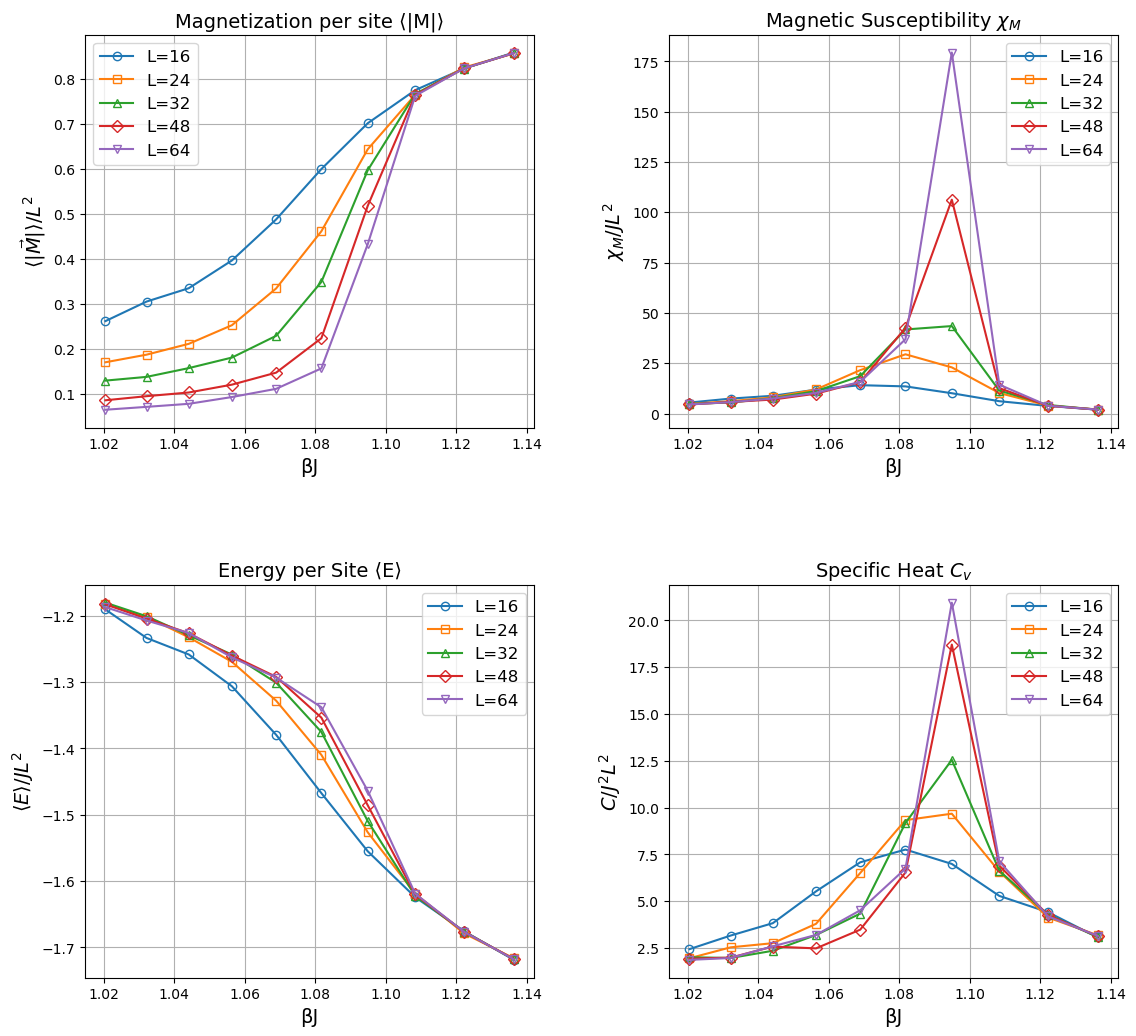

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility $χ_M$",
          "Energy per Site ⟨E⟩", "Specific Heat $C_v$"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "Cv", "E"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)], mfc = 'none',
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncPottsBinder5-state-16-64.pdf")
plt.show()

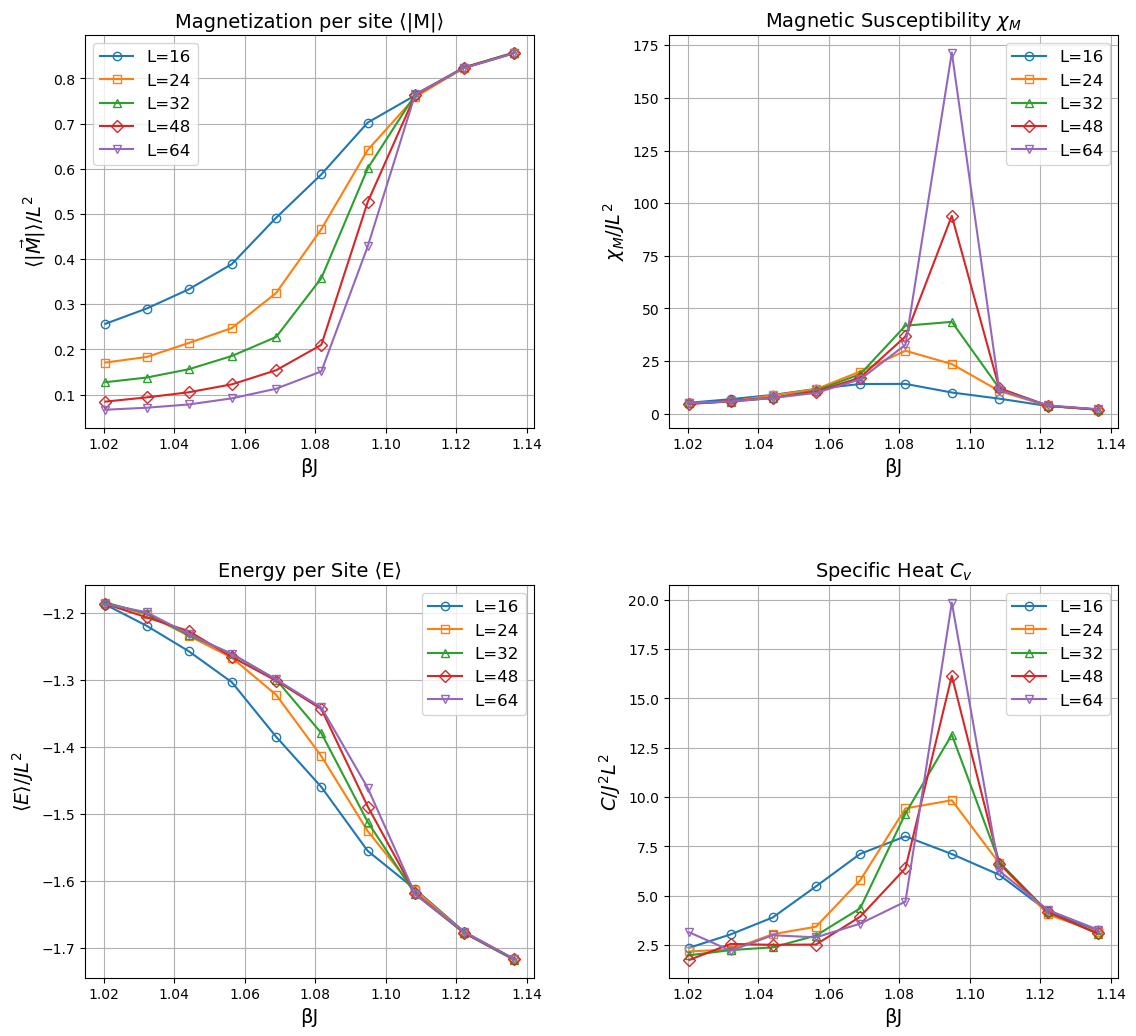

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility $χ_M$",
          "Energy per Site ⟨E⟩", "Specific Heat $C_v$"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "Cv", "E"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)], mfc = 'none',
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
#plt.savefig("ResponseFuncPottsBinderResolved4.2-state-16-64.pdf")
plt.show()

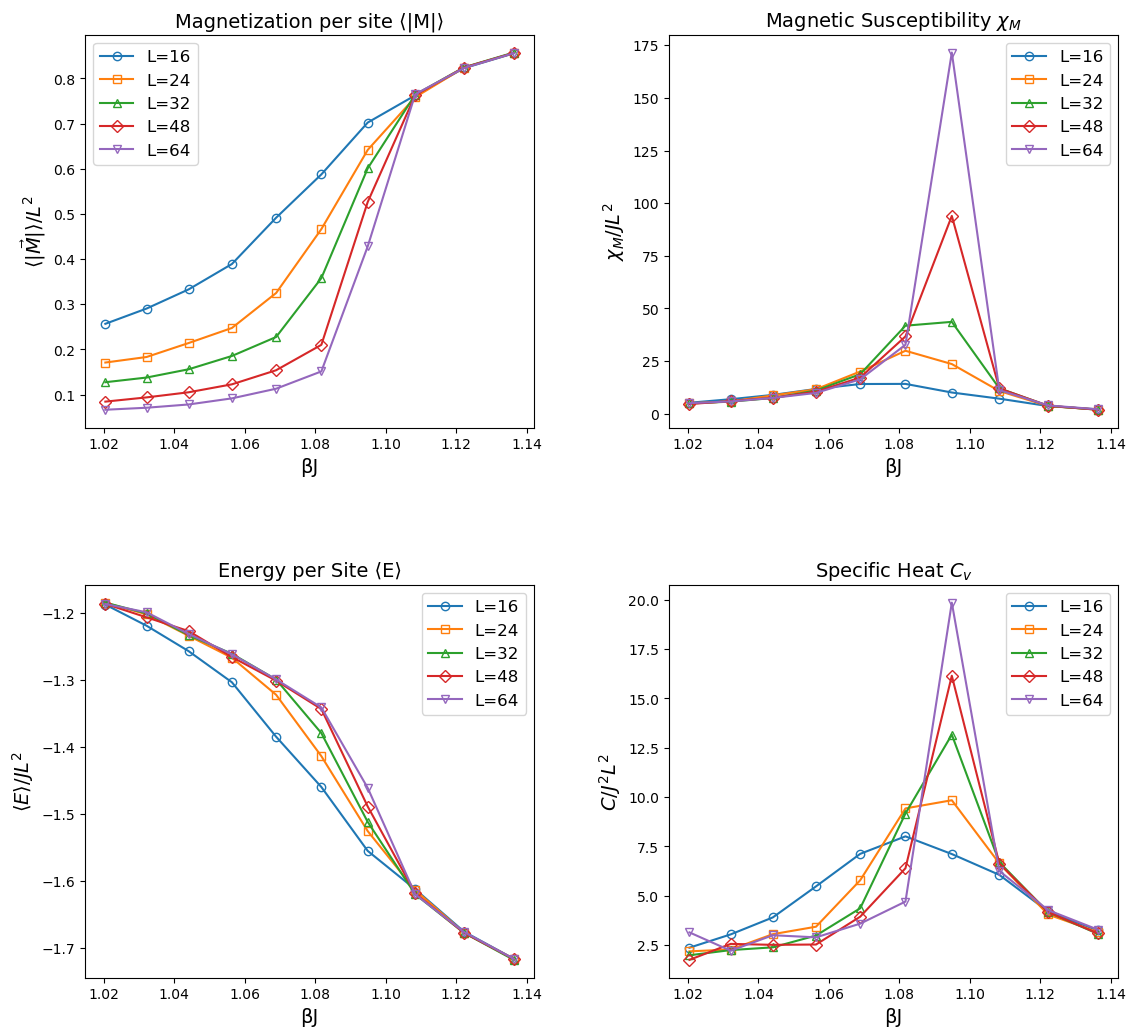

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility $χ_M$",
          "Energy per Site ⟨E⟩", "Specific Heat $C_v$"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "Cv", "E"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)], mfc = 'none',
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(False)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncPottsBinderResolved4.2-state-16-64.pdf")
plt.show()

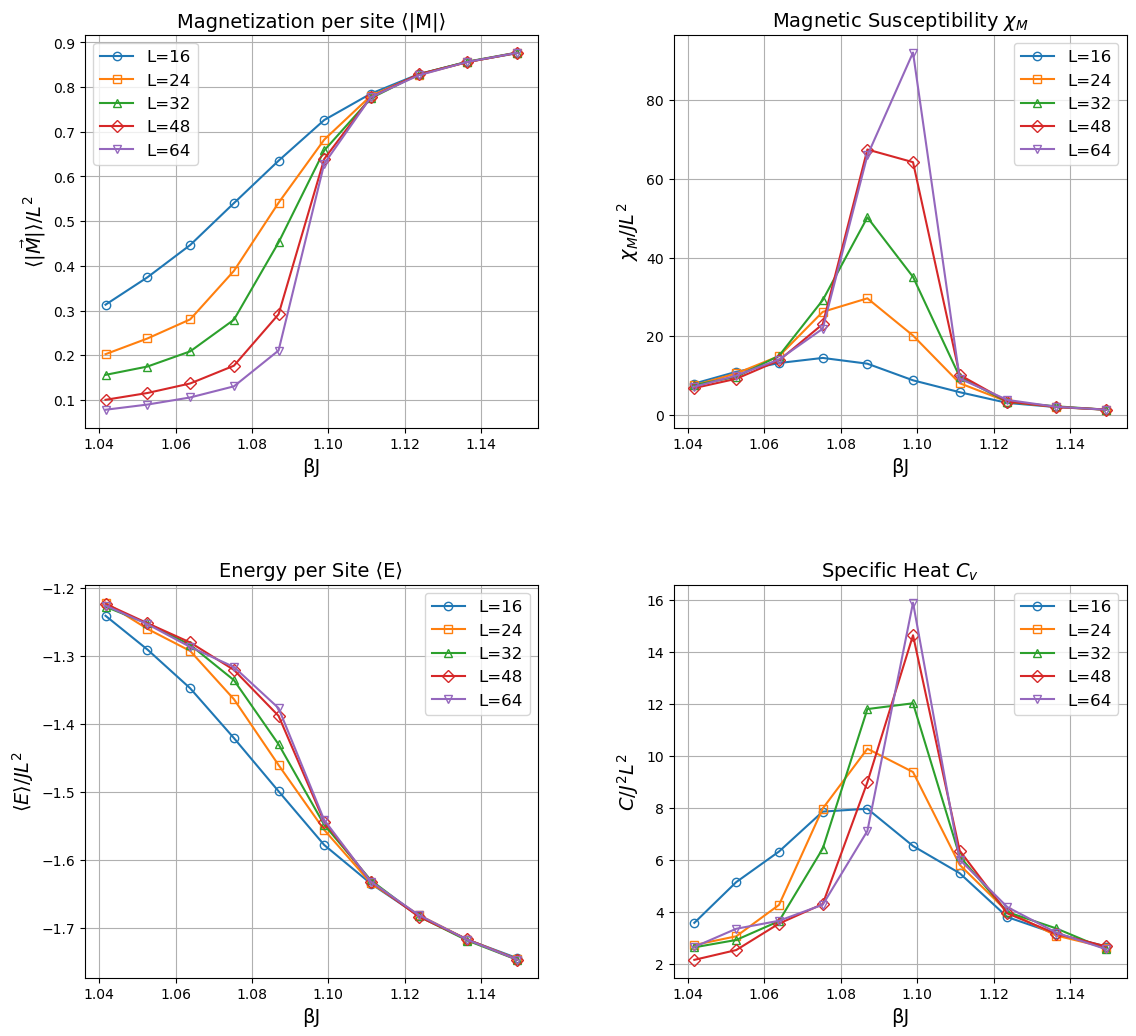

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility $χ_M$",
          "Energy per Site ⟨E⟩", "Specific Heat $C_v$"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "Cv", "E"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)], mfc = 'none',
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncPottsBinderResolved4.1-state-16-64.pdf")
plt.show()

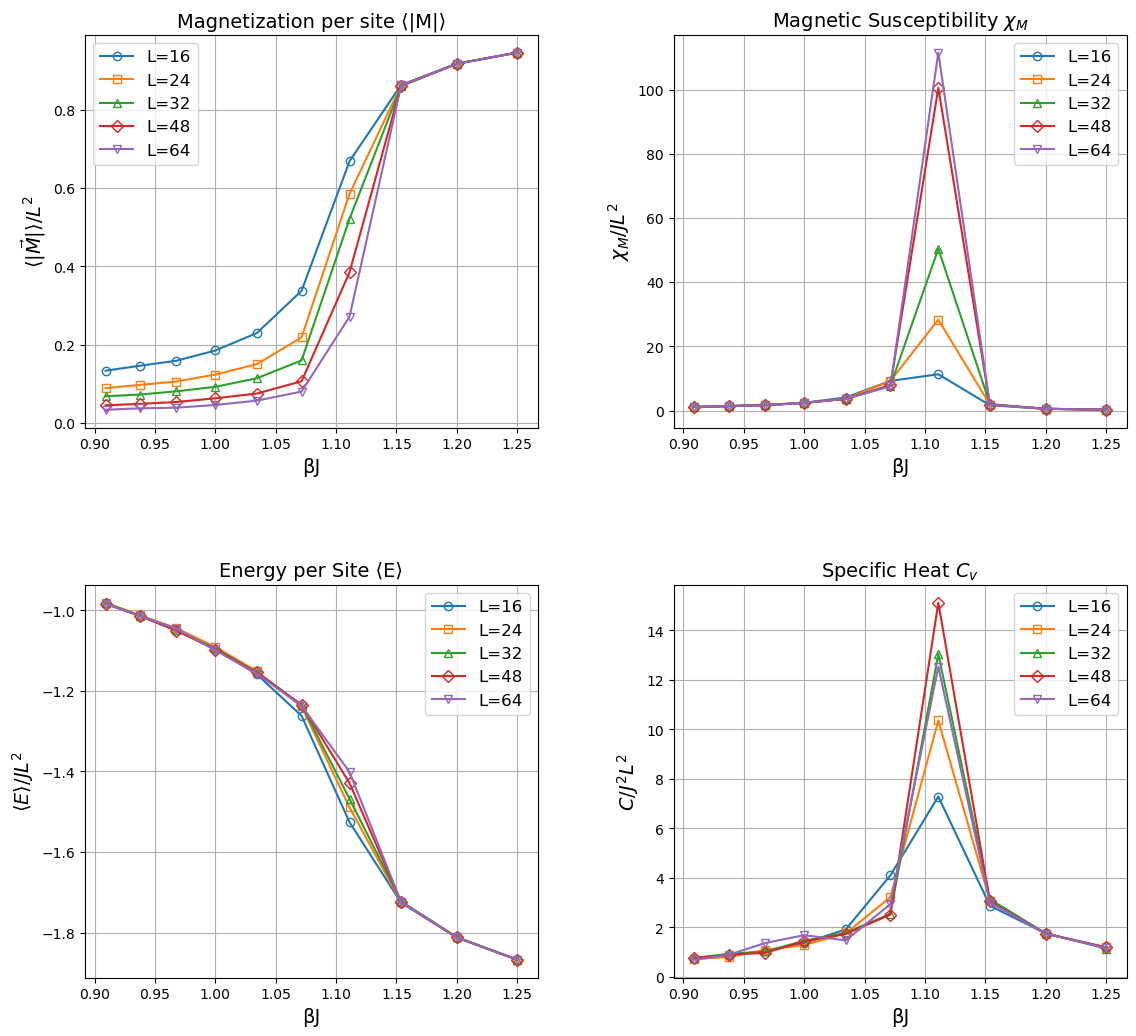

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility $χ_M$",
          "Energy per Site ⟨E⟩", "Specific Heat $C_v$"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "Cv", "E"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)], mfc = 'none',
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncPottsBinderResolved4-state-16-64.pdf")
plt.show()

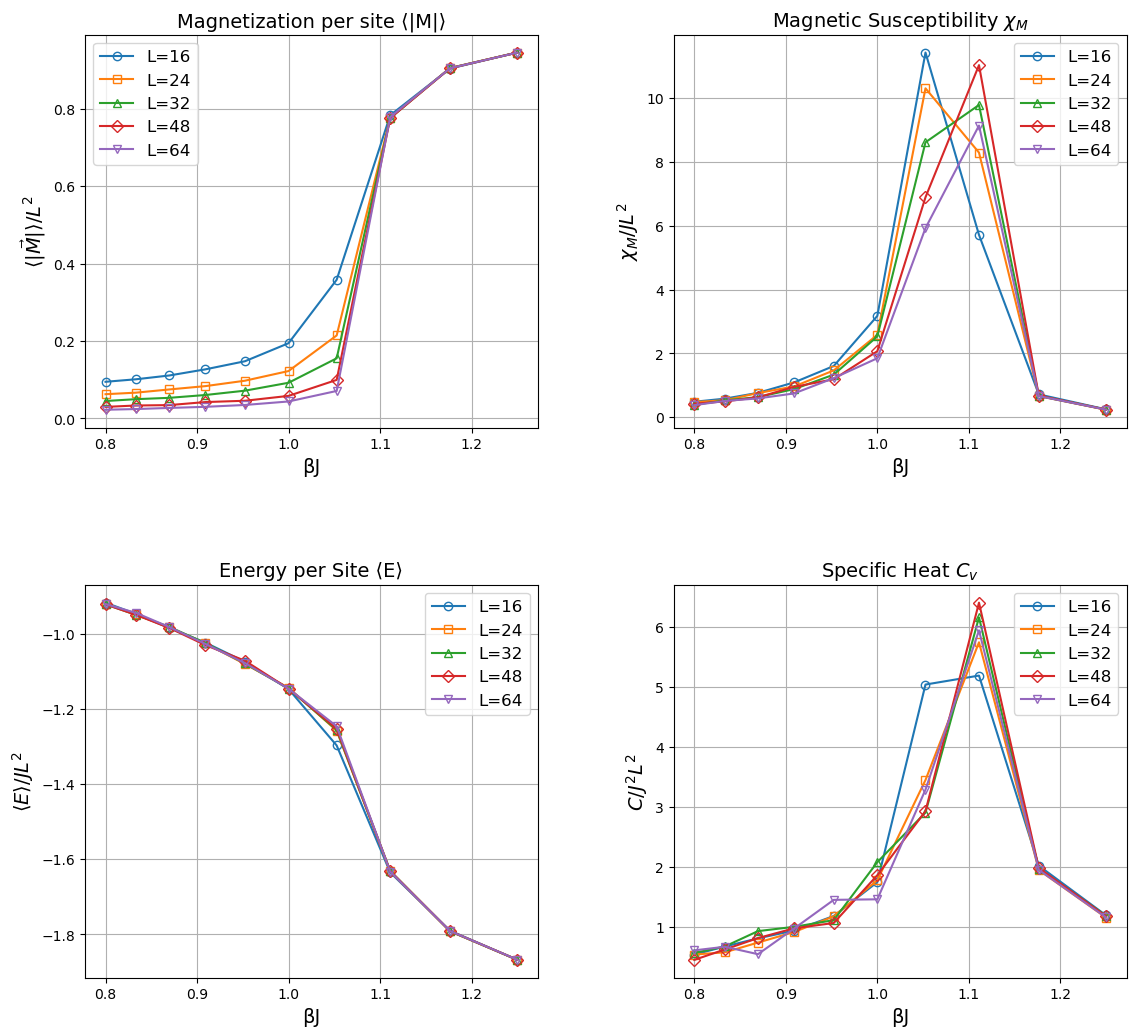

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility $χ_M$",
          "Energy per Site ⟨E⟩", "Specific Heat $C_v$"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "Cv", "E"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)], mfc = 'none',
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncPottsBinderResolved4-stateLog2-16-64.pdf")
plt.show()

Slope = -0.3399
Estimated β/ν = 0.3399
Intercept = 0.6233
R² = 0.9553


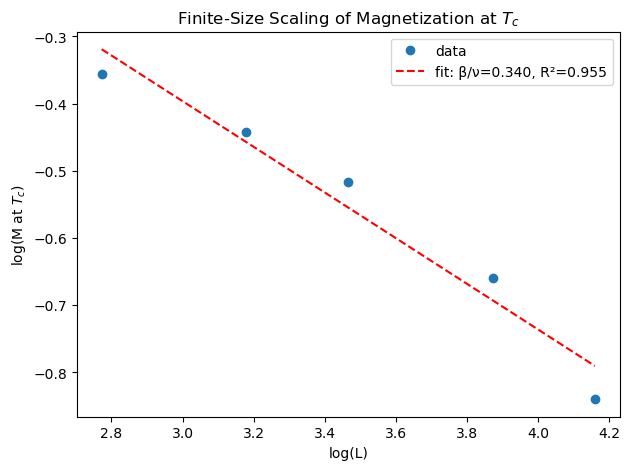

In [13]:
from scipy.stats import linregress
Tc = 0.913  # your estimated critical temperature

# --- Collect M(Tc) for each L ---
M_Tc_values = []

for L in L_values:

    T_arr = np.array(T_values)
    M_arr = np.array(results[L]["M"])

    # Find index closest to Tc
    idx = np.argmin(np.abs(T_arr - Tc))

    M_Tc = M_arr[idx]
    M_Tc_values.append(M_Tc)

M_Tc_values = np.array(M_Tc_values)
L_array = np.array(L_values)

# --- Log-log fit: M ~ L^(-β/ν) ---
logL = np.log(L_array)
logM = np.log(M_Tc_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logM)

beta_over_nu = -slope  # IMPORTANT: negative slope

# --- Print results ---
print(f"Slope = {slope:.4f}")
print(f"Estimated β/ν = {beta_over_nu:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot ---
plt.figure(figsize=(7,5))

plt.plot(logL, logM, 'o', label="data")
plt.plot(
    logL,
    intercept + slope * logL,
    'r--',
    label=f"fit: β/ν={beta_over_nu:.3f}, R²={r_value**2:.3f}"
)

plt.xlabel("log(L)")
plt.ylabel("log(M at $T_c$)")
plt.title("Finite-Size Scaling of Magnetization at $T_c$")
plt.legend()
#plt.grid(True)

plt.savefig("FSS_beta_over_nu_q5_potts.pdf")
plt.show()

Slope = -0.6356
Estimated β/ν = 0.6356
Intercept = 1.4481
R² = 0.9335


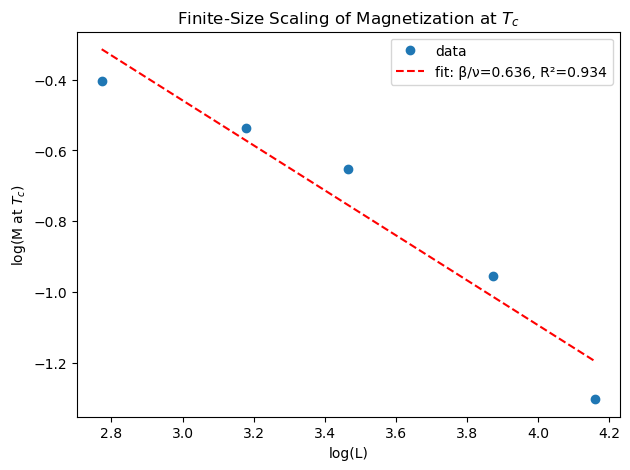

In [15]:
from scipy.stats import linregress
Tc = 0.91  # your estimated critical temperature

# --- Collect M(Tc) for each L ---
M_Tc_values = []

for L in L_values:

    T_arr = np.array(T_values)
    M_arr = np.array(results[L]["M"])

    # Find index closest to Tc
    idx = np.argmin(np.abs(T_arr - Tc))

    M_Tc = M_arr[idx]
    M_Tc_values.append(M_Tc)

M_Tc_values = np.array(M_Tc_values)
L_array = np.array(L_values)

# --- Log-log fit: M ~ L^(-β/ν) ---
logL = np.log(L_array)
logM = np.log(M_Tc_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logM)

beta_over_nu = -slope  # IMPORTANT: negative slope

# --- Print results ---
print(f"Slope = {slope:.4f}")
print(f"Estimated β/ν = {beta_over_nu:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot ---
plt.figure(figsize=(7,5))

plt.plot(logL, logM, 'o', label="data")
plt.plot(
    logL,
    intercept + slope * logL,
    'r--',
    label=f"fit: β/ν={beta_over_nu:.3f}, R²={r_value**2:.3f}"
)

plt.xlabel("log(L)")
plt.ylabel("log(M at $T_c$)")
plt.title("Finite-Size Scaling of Magnetization at $T_c$")
plt.legend()
#plt.grid(True)

plt.savefig("FSS_beta_over_nu_q4_potts.pdf")
plt.show()

Slope (γ/ν) = 1.8397
Intercept = -2.4876
R² = 0.9959


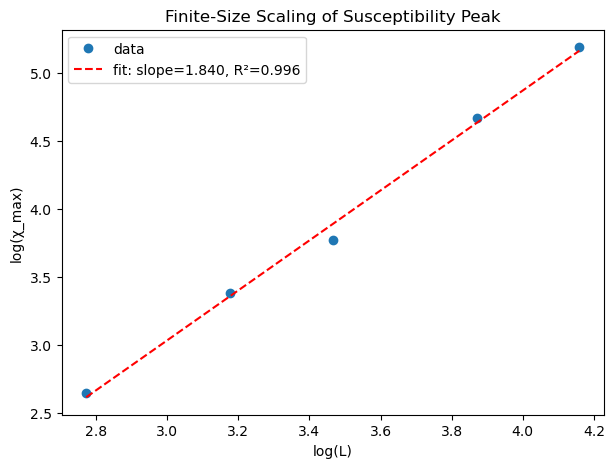

In [11]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(7,5))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.3f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
#plt.grid(True)
plt.savefig("FSSq5BinderResolvedLo-16-64.pdf")
plt.show()

Slope (γ/ν) = 1.7692
Intercept = -2.2703
R² = 0.9962


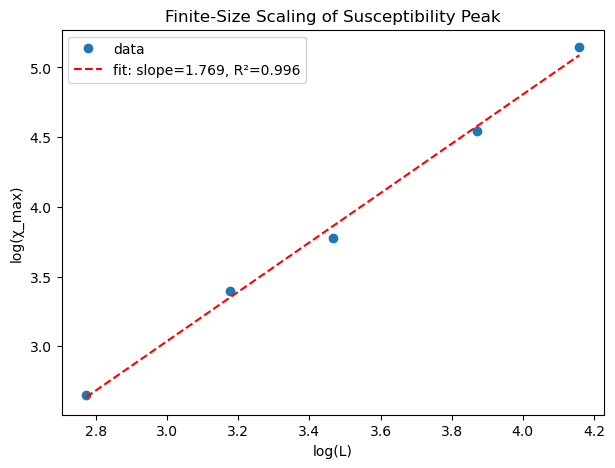

In [87]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(7,5))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.3f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
#plt.grid(True)
plt.savefig("FSSq4BinderResolvedLog2-16-64.pdf")
plt.show()

Slope (γ/ν) = 1.7692
Intercept = -2.2703
R² = 0.9962


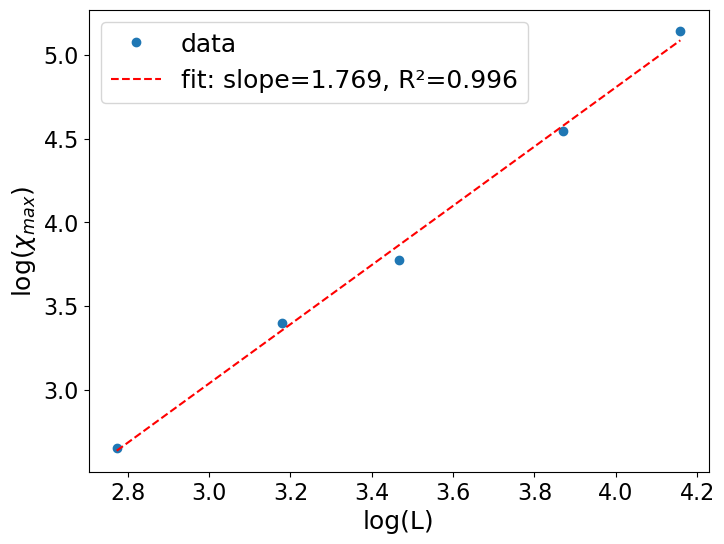

In [7]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(8,6))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.3f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)", fontsize = 18)
plt.ylabel("log($χ_{max}$)", fontsize = 18)
plt.xticks(fontsize = 16)
plt.yticks(fontsize = 16)
#plt.title("Finite-Size Scaling of Susceptibility Peak", fontsize = 14)
plt.legend(fontsize = 18)
#plt.grid(True)
plt.savefig("FSSq4BinderResolvedLogFont2-16-64.pdf")
plt.show()

Slope (γ/ν) = 1.3065
Intercept = -0.8166
R² = 0.9661


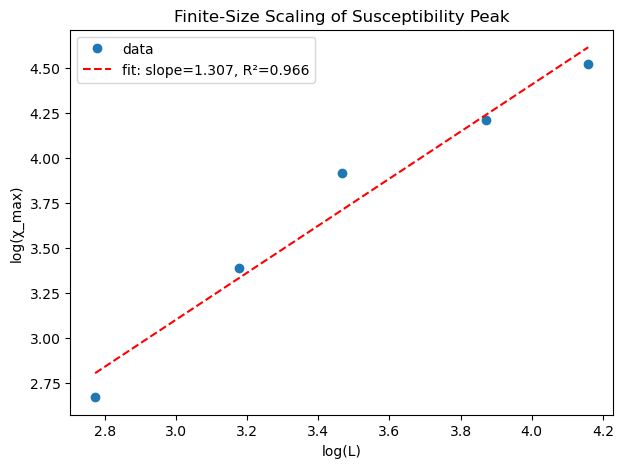

In [45]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(7,5))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.3f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
#plt.grid(True)
plt.savefig("FSSq4BinderResolvedLog1-16-64.pdf")
plt.show()

Slope (γ/ν) = 1.6980
Intercept = -2.1219
R² = 0.9635


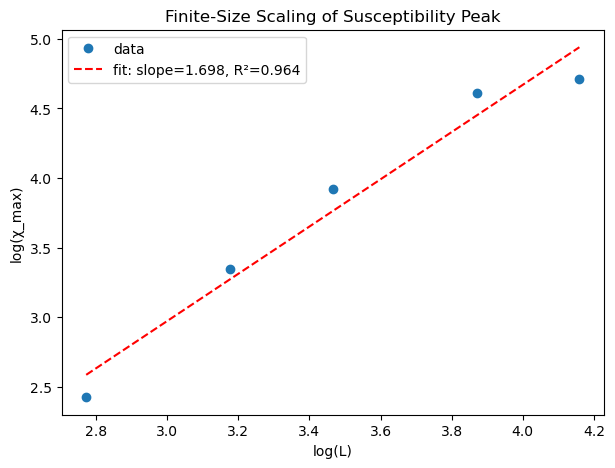

In [45]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(7,5))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.3f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
#plt.grid(True)
plt.savefig("FSSq4BinderResolvedLog-16-64.pdf")
plt.show()

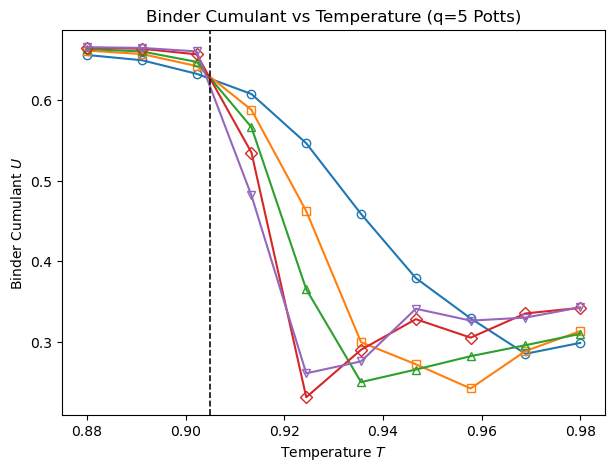

In [21]:
plt.figure(figsize=(7,5))
Tc= 0.905
markers = ['o', 's', '^', 'D', 'v']
for i,L in enumerate(L_values):
    plt.plot(T_values, results[L]["Binder"], marker=markers[i % len(markers)], mfc = 'none',
        linestyle='-', label=f"L={L}")

plt.xlabel("Temperature $T$")
plt.ylabel("Binder Cumulant $U$")
plt.title("Binder Cumulant vs Temperature (q=5 Potts)")
plt.axvline(Tc, linestyle='--', linewidth = 1.15, color='black')
#plt.xlim(0.90,0.92)
plt.savefig("BinderCumulantq5.1Log.pdf")
plt.legend#()
plt.grid(False)
plt.show()

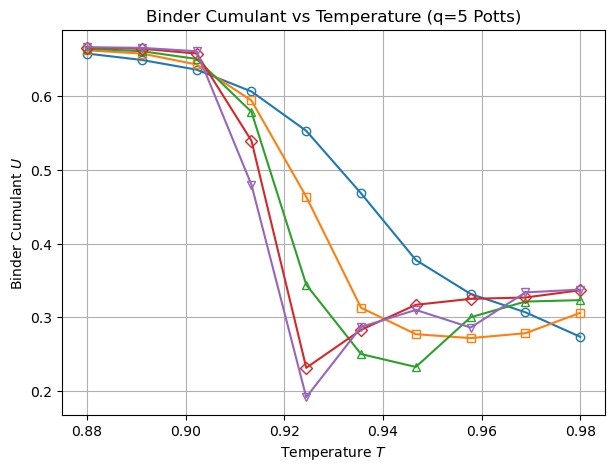

In [15]:
plt.figure(figsize=(7,5))
markers = ['o', 's', '^', 'D', 'v']
for i,L in enumerate(L_values):
    plt.plot(T_values, results[L]["Binder"], marker=markers[i % len(markers)], mfc = 'none',
        linestyle='-', label=f"L={L}")

plt.xlabel("Temperature $T$")
plt.ylabel("Binder Cumulant $U$")
plt.title("Binder Cumulant vs Temperature (q=5 Potts)")
#plt.xlim(0.90,0.92)
plt.savefig("BinderCumulantq5Log.pdf")
plt.legend#()
plt.grid(True)
plt.show()

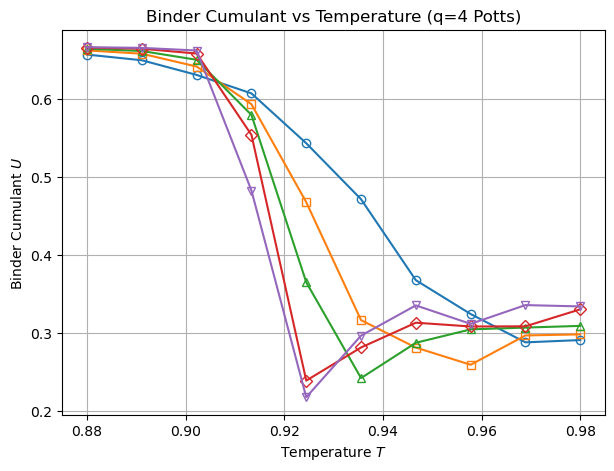

In [95]:
plt.figure(figsize=(7,5))
markers = ['o', 's', '^', 'D', 'v']
for i,L in enumerate(L_values):
    plt.plot(T_values, results[L]["Binder"], marker=markers[i % len(markers)], mfc = 'none',
        linestyle='-', label=f"L={L}")

plt.xlabel("Temperature $T$")
plt.ylabel("Binder Cumulant $U$")
plt.title("Binder Cumulant vs Temperature (q=4 Potts)")
#plt.xlim(0.90,0.92)
plt.savefig("BinderCumulantq4Log2.pdf")
plt.legend#()
plt.grid(True)
plt.show()

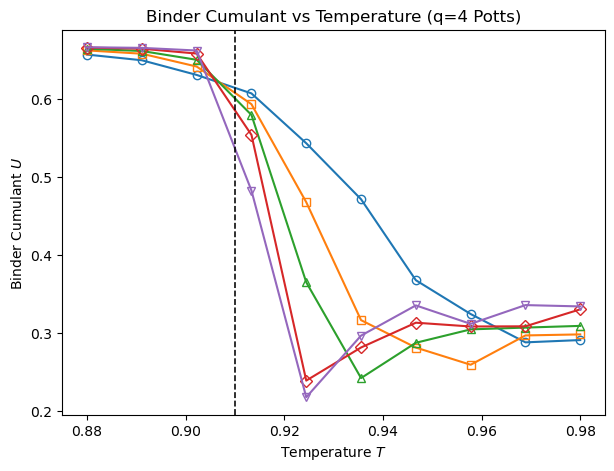

In [27]:
plt.figure(figsize=(7,5))
Tc = 0.91
markers = ['o', 's', '^', 'D', 'v']
for i,L in enumerate(L_values):
    plt.plot(T_values, results[L]["Binder"], marker=markers[i % len(markers)], mfc = 'none',
        linestyle='-', label=f"L={L}")

plt.xlabel("Temperature $T$")
plt.ylabel("Binder Cumulant $U$")
plt.title("Binder Cumulant vs Temperature (q=4 Potts)")
#plt.xlim(0.90,0.92)
plt.axvline(Tc, linestyle='--', linewidth = 1.15, color='black')
plt.savefig("BinderCumulantq4Potts.pdf")
plt.legend#()
plt.grid(False)
plt.show()

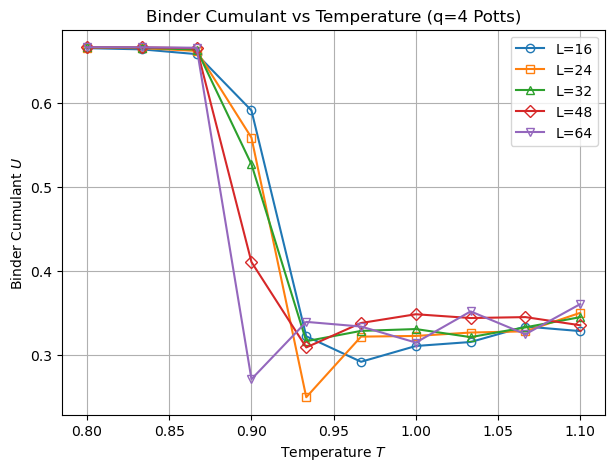

In [13]:
plt.figure(figsize=(7,5))
markers = ['o', 's', '^', 'D', 'v']
for i,L in enumerate(L_values):
    plt.plot(T_values, results[L]["Binder"], marker=markers[i % len(markers)], mfc = 'none',
        linestyle='-', label=f"L={L}")

plt.xlabel("Temperature $T$")
plt.ylabel("Binder Cumulant $U$")
plt.title("Binder Cumulant vs Temperature (q=4 Potts)")
#plt.xlim(0.875,0.880)
plt.savefig("BinderCumulantq4Log.pdf")
plt.legend()
plt.grid(True)
plt.show()

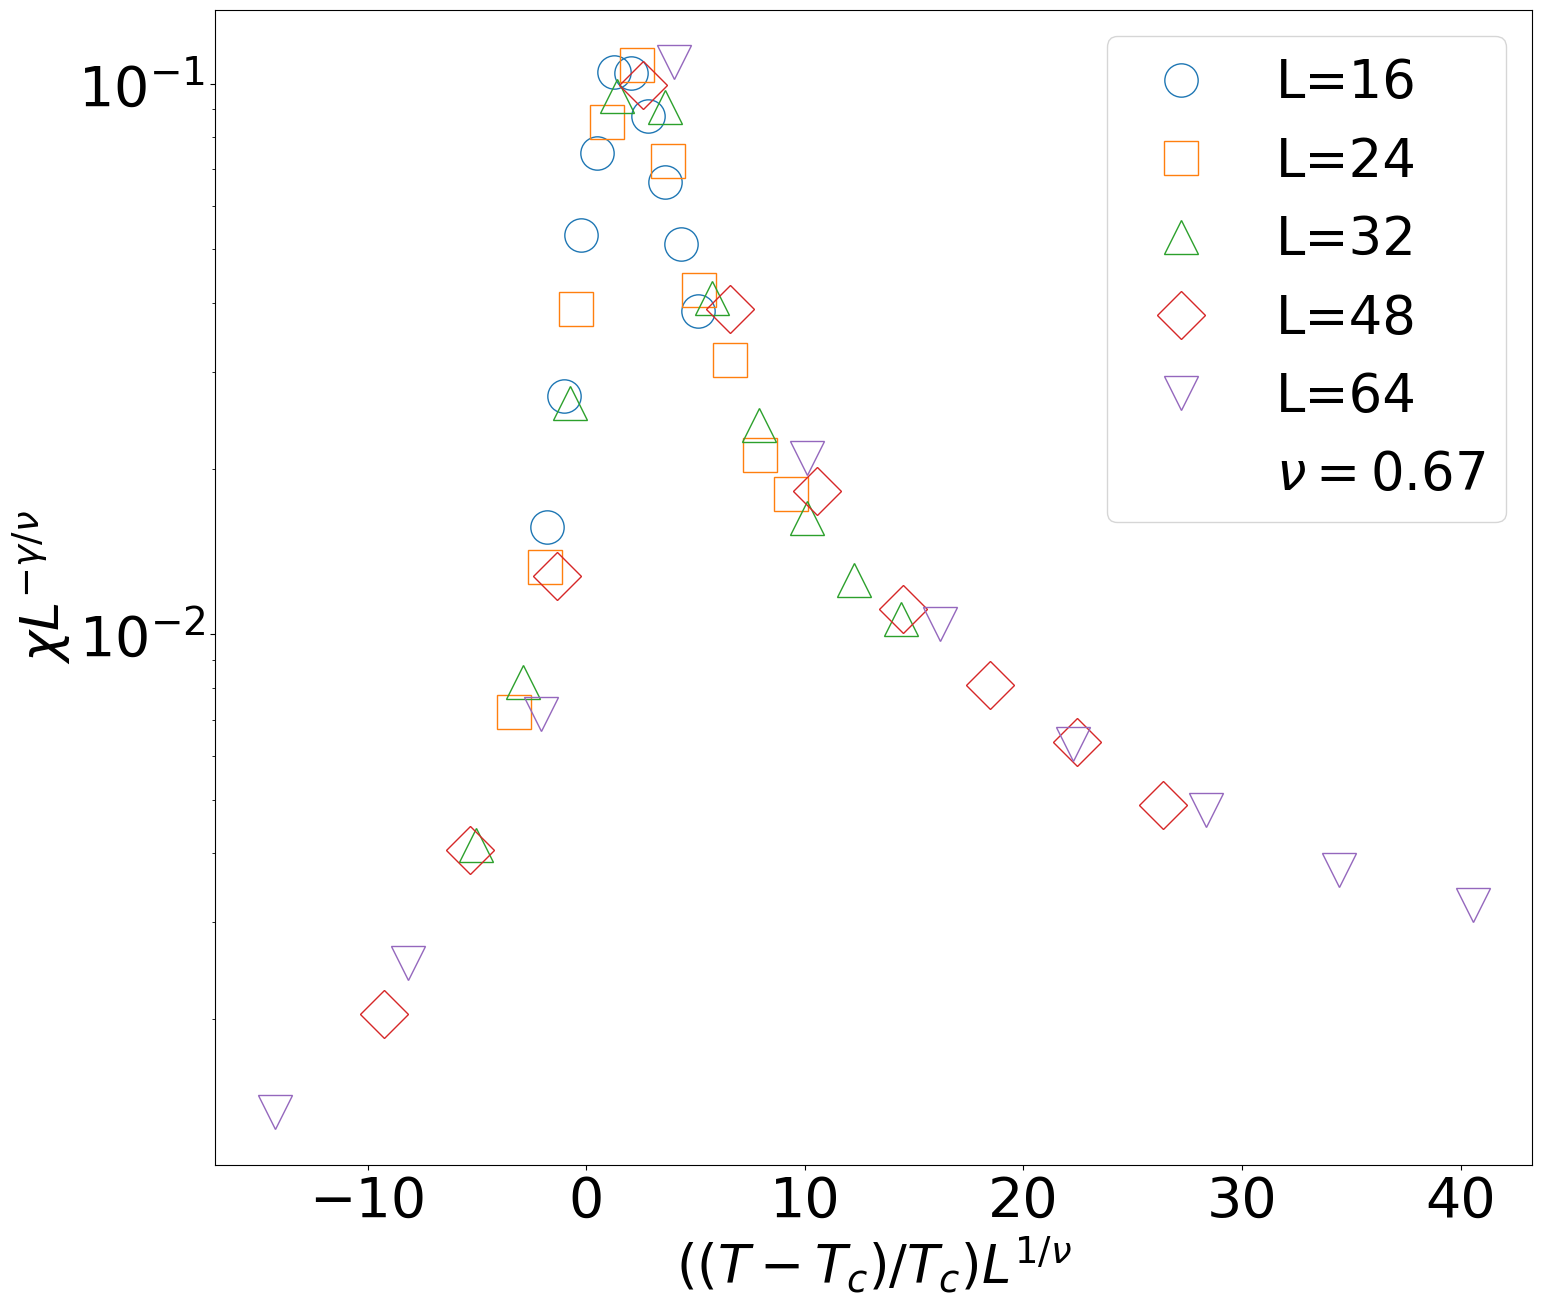

In [29]:
Tc = 0.906    # example from Binder crossing
nu = 0.67       # your estimate
gamma_over_nu = slope  # from your log fit
plt.figure(figsize=(17,15))

for i,L in enumerate(L_values):
    T_arr = T_values
    chi_arr = results[L]["chi"]

    x = ((T_arr - Tc)/Tc) * L**(1/nu)
    y = chi_arr / (L**gamma_over_nu)

    plt.plot(x, y, marker=markers[i % len(markers)], ms=24, mfc='none', label=f"L={L}", linestyle = '')
plt.plot([], [], ' ', label=rf"$\nu = {nu}$")
plt.xlabel(r"$((T - T_c)/T_c)L^{1/\nu}$", fontsize = 38)
plt.ylabel(r"$\chi L^{-\gamma/\nu}$", fontsize = 38)
plt.yscale('log')
plt.xticks(fontsize = 40)
plt.yticks(fontsize = 40)
#plt.title("Finite-Size Scaling Collapse: Susceptibility (q=4 Potts)")
plt.legend(fontsize = 38)
plt.savefig("FSSCollapseq4BinderResolvedAroundTheoGridSize2.1Font.pdf")
#plt.grid(True)
plt.show()

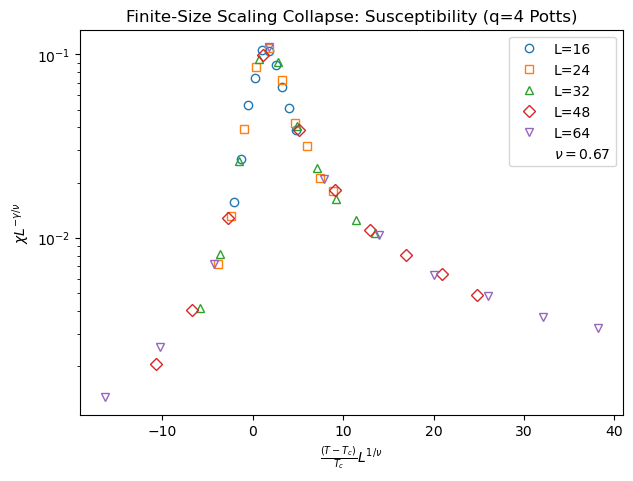

In [115]:
Tc = 0.91    # example from Binder crossing
nu = 0.67       # your estimate
gamma_over_nu = slope  # from your log fit
plt.figure(figsize=(7,5))

for i,L in enumerate(L_values):
    T_arr = T_values
    chi_arr = results[L]["chi"]

    x = ((T_arr - Tc)/Tc) * L**(1/nu)
    y = chi_arr / (L**gamma_over_nu)

    plt.plot(x, y, marker=markers[i % len(markers)], mfc='none', label=f"L={L}", linestyle = '')
plt.plot([], [], ' ', label=rf"$\nu = {nu}$")
plt.xlabel(r"$\frac{(T - T_c)}{T_c}L^{1/\nu}$")
plt.ylabel(r"$\chi L^{-\gamma/\nu}$")
plt.yscale('log')
plt.title("Finite-Size Scaling Collapse: Susceptibility (q=4 Potts)")
plt.legend()
plt.savefig("FSSCollapseq4BinderResolvedAroundTheoGridSize2.1.pdf")
#plt.grid(True)
plt.show()

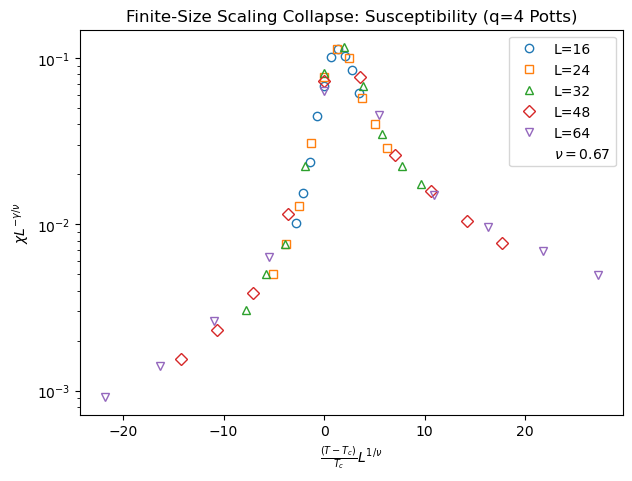

In [75]:
Tc = 0.91    # example from Binder crossing
nu = 0.67       # your estimate
gamma_over_nu = 1.75  # from your log fit
plt.figure(figsize=(7,5))

for i,L in enumerate(L_values):
    T_arr = T_values
    chi_arr = results[L]["chi"]

    x = ((T_arr - Tc)/Tc) * L**(1/nu)
    y = chi_arr / (L**gamma_over_nu)

    plt.plot(x, y, marker=markers[i % len(markers)], mfc='none', label=f"L={L}", linestyle = '')
plt.plot([], [], ' ', label=rf"$\nu = {nu}$")
plt.xlabel(r"$\frac{(T - T_c)}{T_c}L^{1/\nu}$")
plt.ylabel(r"$\chi L^{-\gamma/\nu}$")
plt.yscale('log')
plt.title("Finite-Size Scaling Collapse: Susceptibility (q=4 Potts)")
plt.legend()
plt.savefig("FSSCollapseq4BinderResolvedAroundTheoGridSize2.pdf")
#plt.grid(True)
plt.show()

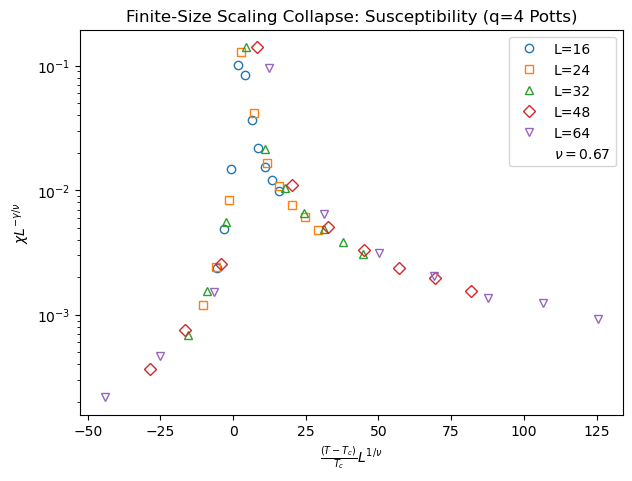

In [17]:
Tc = 0.878    # example from Binder crossing
nu = 0.67       # your estimate
gamma_over_nu = slope  # from your log fit
plt.figure(figsize=(7,5))

for i,L in enumerate(L_values):
    T_arr = T_values
    chi_arr = results[L]["chi"]

    x = ((T_arr - Tc)/Tc) * L**(1/nu)
    y = chi_arr / (L**gamma_over_nu)

    plt.plot(x, y, marker=markers[i % len(markers)], mfc='none', label=f"L={L}", linestyle = '')
plt.plot([], [], ' ', label=rf"$\nu = {nu}$")
plt.xlabel(r"$\frac{(T - T_c)}{T_c}L^{1/\nu}$")
plt.ylabel(r"$\chi L^{-\gamma/\nu}$")
plt.yscale('log')
plt.title("Finite-Size Scaling Collapse: Susceptibility (q=4 Potts)")
plt.legend()
plt.savefig("FSSCollapseq4BinderResolvedAroundTheoGridSize1.pdf")
#plt.grid(True)
plt.show()

In [9]:
import time 
# Storage
results = {L: {"M_x": [], "chi_M": [], "C_v": [], "E_avg": [], "time": []} for L in L_values}

for T in T_values:
    print(f"\nRunning simulations for T = {T:.3f} (β = {1/T:.3f})...")
    for L in L_values:
        start_time = time.time()  # ⏱ start timer

        M_avg_per_site, chi_M, C_v, E_avg_per_site = run_simulation(
            L, T, sweeps=sweeps, J=J, q=4, burn_frac=0.3
        )

        end_time = time.time()
        elapsed = end_time - start_time

        results[L]["M_x"].append(M_avg_per_site)
        results[L]["chi_M"].append(chi_M)
        results[L]["C_v"].append(C_v)
        results[L]["E_avg"].append(E_avg_per_site)
        results[L]["time"].append(elapsed)

        print(f"  L={L:2d} → done in {elapsed/60:.2f} min | M={M_avg_per_site:.4f}, χ={chi_M:.4e}")



Running simulations for T = 17.500 (β = 0.057)...
  L= 4 → done in 3.04 min | M=0.2284, χ=1.2864e-02
  L= 6 → done in 3.71 min | M=0.1531, χ=1.3036e-02
  L= 8 → done in 4.46 min | M=0.1142, χ=1.2932e-02
  L=10 → done in 5.38 min | M=0.0905, χ=1.2604e-02
  L=12 → done in 6.57 min | M=0.0764, χ=1.2927e-02

Running simulations for T = 5.000 (β = 0.200)...
  L= 4 → done in 3.10 min | M=0.2480, χ=5.2894e-02
  L= 6 → done in 3.73 min | M=0.1655, χ=5.2909e-02
  L= 8 → done in 2.11 min | M=0.1236, χ=5.3013e-02
  L=10 → done in 1.93 min | M=0.0991, χ=5.3338e-02
  L=12 → done in 2.50 min | M=0.0828, χ=5.3711e-02

Running simulations for T = 2.917 (β = 0.343)...
  L= 4 → done in 1.20 min | M=0.2735, χ=1.0892e-01
  L= 6 → done in 1.33 min | M=0.1821, χ=1.0959e-01
  L= 8 → done in 1.73 min | M=0.1363, χ=1.1033e-01
  L=10 → done in 1.70 min | M=0.1089, χ=1.0983e-01
  L=12 → done in 3.69 min | M=0.0912, χ=1.1194e-01

Running simulations for T = 2.059 (β = 0.486)...
  L= 4 → done in 1.15 min | M=0.30

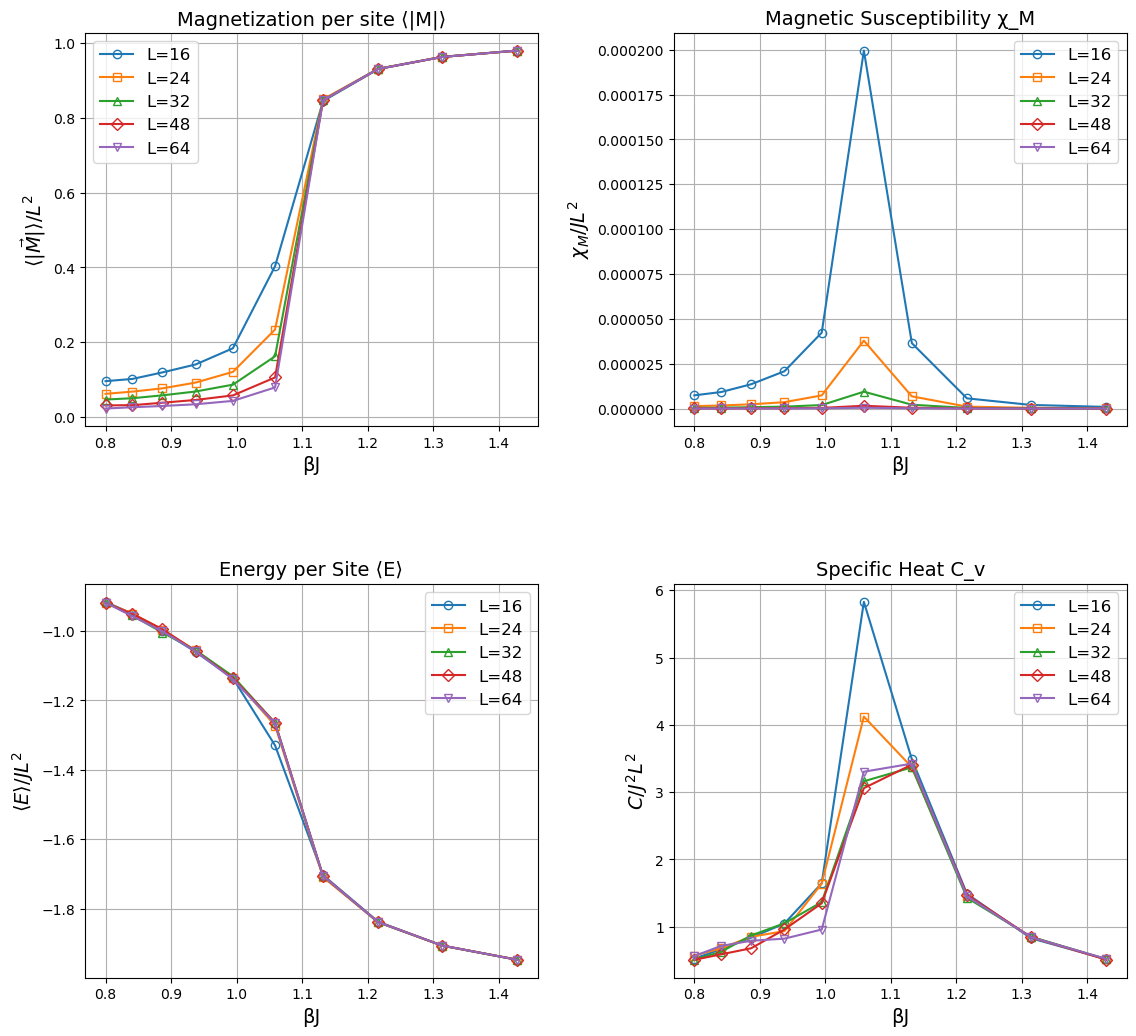

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "Cv", "E"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)], mfc = 'none',
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncPottsBinderResolved4-state-16-64.pdf")
plt.show()


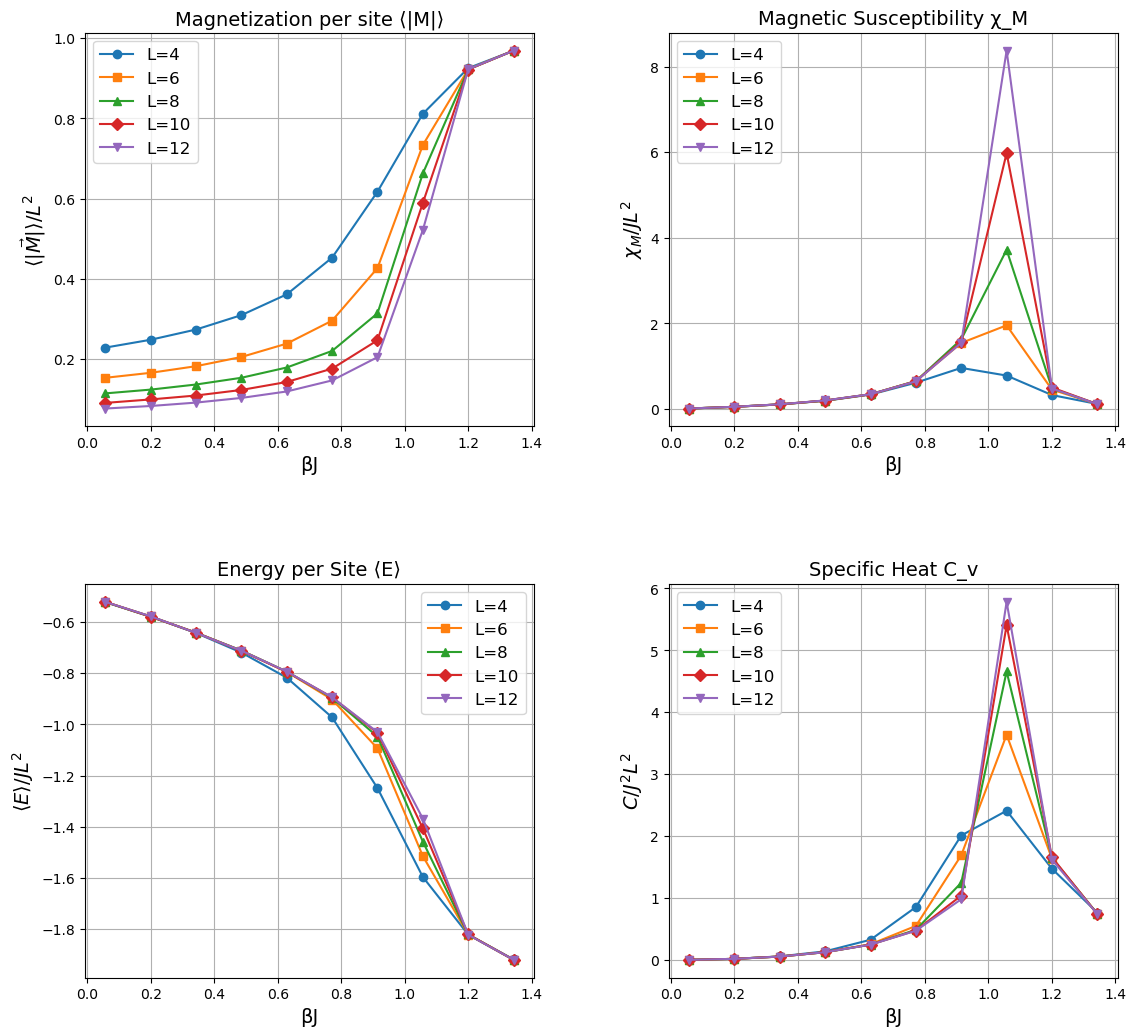

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.show()


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


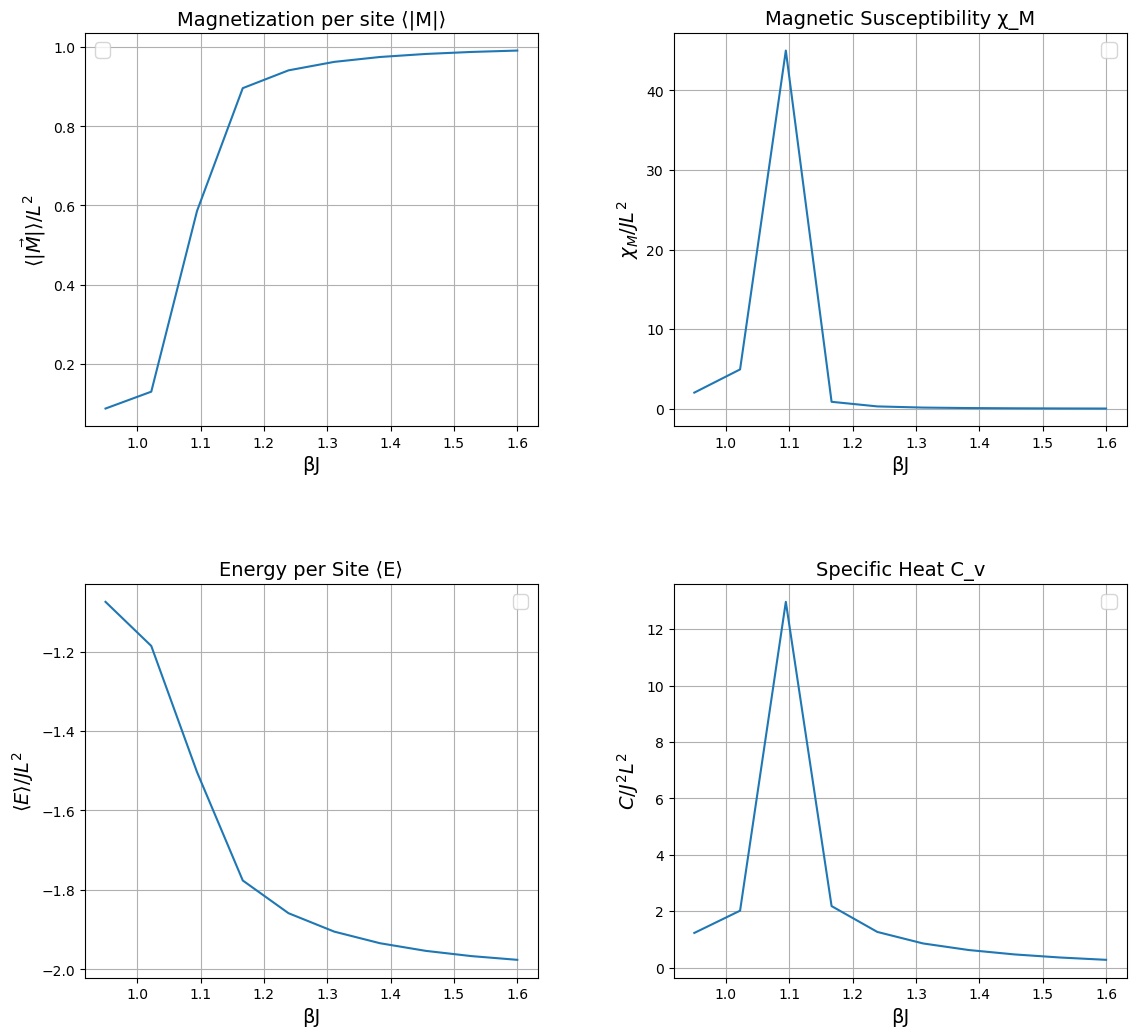

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
# List of markers to cycle through
markers = ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'h']

for i, key in enumerate(keys):
    ax = axes[i]
    ax.plot(beta_values, results[key])
    ax.set_title(titles[i], fontsize= 14)
    ax.set_xlabel("βJ", fontsize= 14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize = 14)
    ax.grid(True)
#plt.savefig('ResFuncfor5.pdf', bbox_inches = 'tight')
plt.tight_layout(pad=3.0)  # More padding around subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)  # Extra space between rows/columns
plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


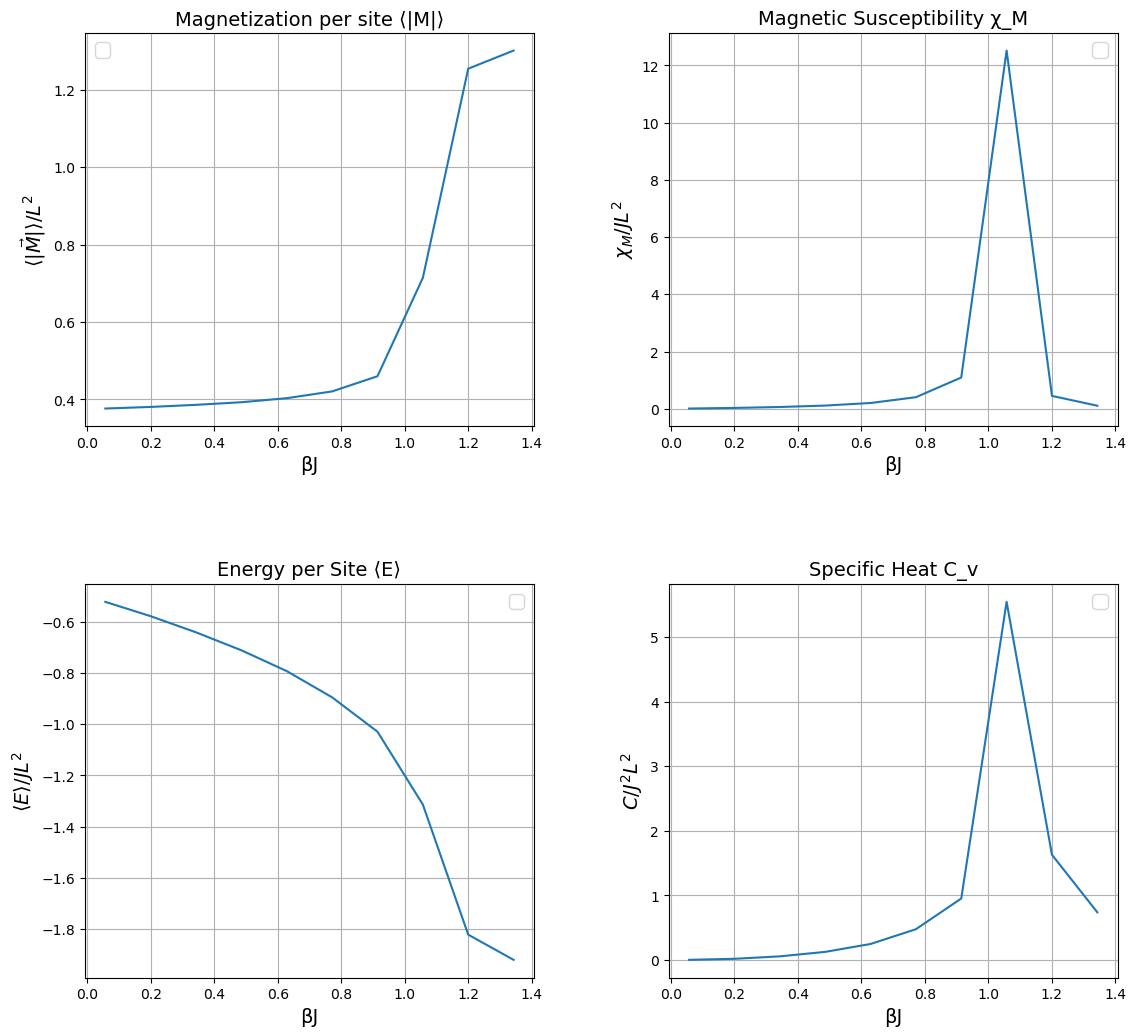

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
# List of markers to cycle through
markers = ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'h']

for i, key in enumerate(keys):
    ax = axes[i]
    ax.plot(beta_values, results[key])
    ax.set_title(titles[i], fontsize= 14)
    ax.set_xlabel("βJ", fontsize= 14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize = 14)
    ax.grid(True)
#plt.savefig('ResFuncfor5.pdf', bbox_inches = 'tight')
plt.tight_layout(pad=3.0)  # More padding around subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)  # Extra space between rows/columns
plt.show()

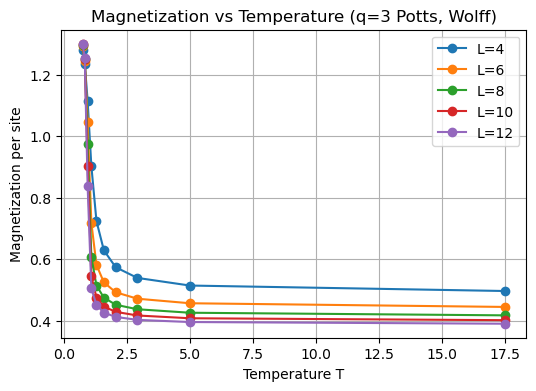

C:\Users\Darwin\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8 ) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


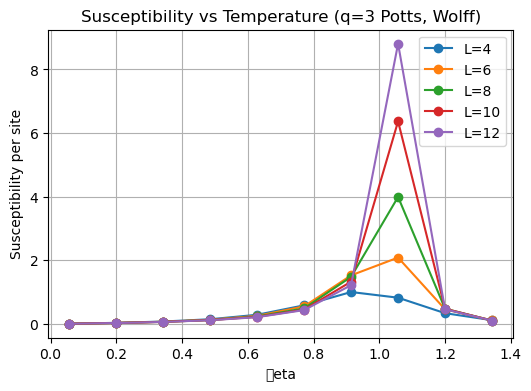

In [39]:
import matplotlib.pyplot as plt

# --- Plot magnetization ---
plt.figure(figsize=(6,4))
for L in L_values:
    plt.plot(beta_values, results[L]["M_x"], 'o-', label=f"L={L}")
plt.xlabel("Temperature T")
plt.ylabel("Magnetization per site")
plt.title("Magnetization vs Temperature (q=3 Potts, Wolff)")
plt.legend()
plt.grid(True)
plt.show()

# --- Plot susceptibility ---
plt.figure(figsize=(6,4))
for L in L_values:
    plt.plot(beta_values, results[L]["chi_M"], 'o-', label=f"L={L}")
plt.xlabel("\beta")
plt.ylabel("Susceptibility per site")
plt.title("Susceptibility vs Temperature (q=3 Potts, Wolff)")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
import time 
# Storage
results = {L: {"M_x": [], "chi_M": [], "C_v": [], "E_avg": [], "time": []} for L in L_values}

for T in T_values:
    print(f"\nRunning simulations for T = {T:.3f} (β = {1/T:.3f})...")
    for L in L_values:
        start_time = time.time()  # ⏱ start timer

        M_avg_per_site, chi_M, C_v, E_avg_per_site = run_simulation(
            L, T, sweeps=sweeps, J=J, q=4, burn_frac=0.3
        )

        end_time = time.time()
        elapsed = end_time - start_time

        results[L]["M_x"].append(M_avg_per_site)
        results[L]["chi_M"].append(chi_M)
        results[L]["C_v"].append(C_v)
        results[L]["E_avg"].append(E_avg_per_site)
        results[L]["time"].append(elapsed)

        print(f"  L={L:2d} → done in {elapsed/60:.2f} min | M={M_avg_per_site:.4f}, χ={chi_M:.4e}")



Running simulations for T = 1.053 (β = 0.950)...
  L=12 → done in 11.53 min | M=0.2330, χ=2.1410e+00
  L=14 → done in 10.40 min | M=0.1993, χ=2.0846e+00
  L=16 → done in 12.23 min | M=0.1737, χ=2.0742e+00
  L=18 → done in 13.37 min | M=0.1551, χ=2.0427e+00
  L=20 → done in 17.09 min | M=0.1385, χ=2.0417e+00

Running simulations for T = 0.978 (β = 1.022)...
  L=12 → done in 11.74 min | M=0.3657, χ=5.7186e+00
  L=14 → done in 5.00 min | M=0.3069, χ=5.7408e+00
  L=16 → done in 5.27 min | M=0.2638, χ=5.5692e+00
  L=18 → done in 5.93 min | M=0.2317, χ=5.3830e+00
  L=20 → done in 6.65 min | M=0.2087, χ=5.2857e+00

Running simulations for T = 0.914 (β = 1.094)...
  L=12 → done in 8.58 min | M=0.7273, χ=6.0010e+00
  L=14 → done in 10.95 min | M=0.7110, χ=8.0221e+00
  L=16 → done in 13.65 min | M=0.6916, χ=1.0755e+01
  L=18 → done in 16.55 min | M=0.6762, χ=1.3678e+01
  L=20 → done in 21.59 min | M=0.6614, χ=1.7049e+01

Running simulations for T = 0.857 (β = 1.167)...
  L=12 → done in 12.04 mi

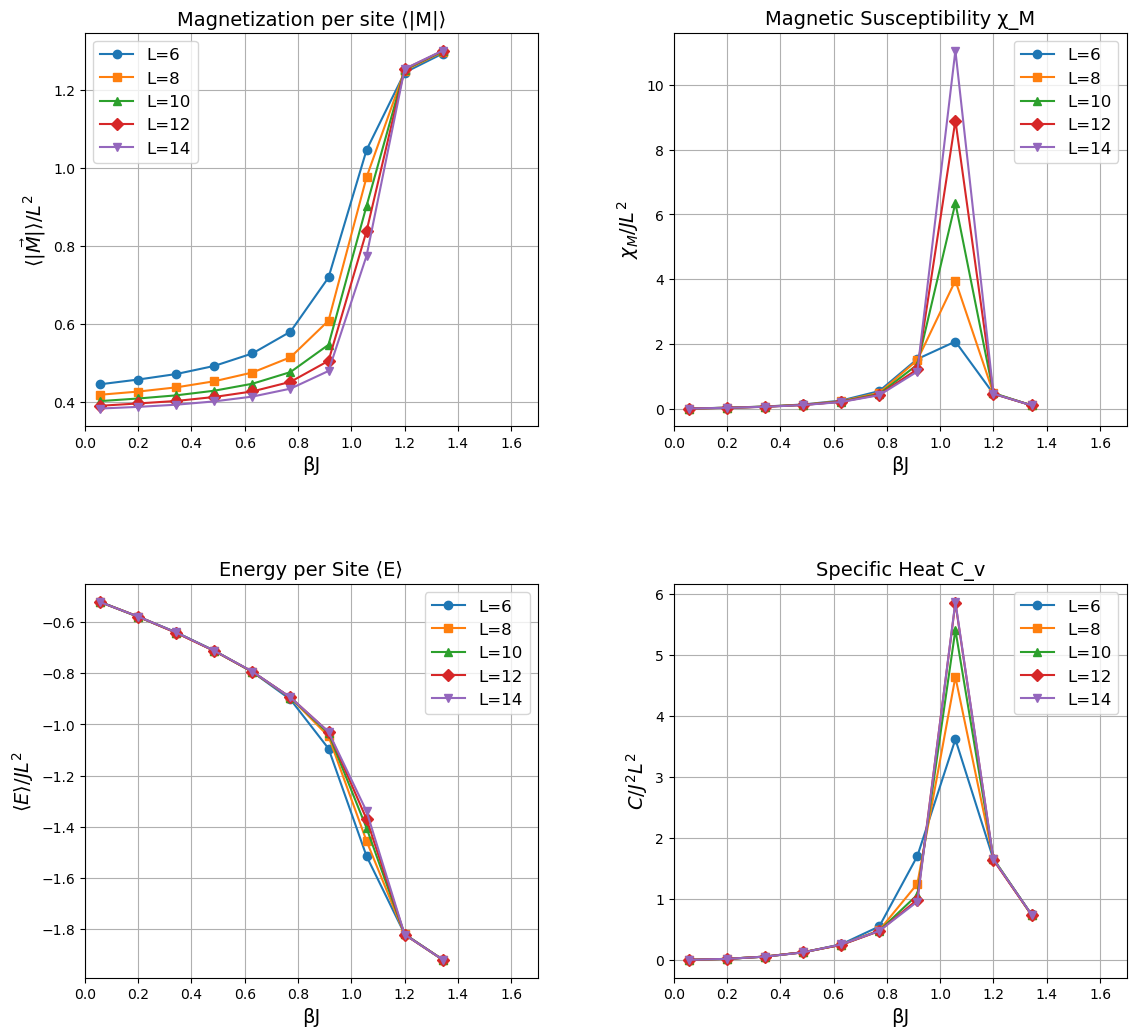

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.show()


In [7]:
import time 
# Storage
results = {L: {"M_x": [], "chi_M": [], "C_v": [], "E_avg": [], "time": []} for L in L_values}

for T in T_values:
    print(f"\nRunning simulations for T = {T:.3f} (β = {1/T:.3f})...")
    for L in L_values:
        start_time = time.time()  # ⏱ start timer

        M_avg_per_site, chi_M, C_v, E_avg_per_site = run_simulation(
            L, T, sweeps=sweeps, J=J, q=4, burn_frac=0.3
        )

        end_time = time.time()
        elapsed = end_time - start_time

        results[L]["M_x"].append(M_avg_per_site)
        results[L]["chi_M"].append(chi_M)
        results[L]["C_v"].append(C_v)
        results[L]["E_avg"].append(E_avg_per_site)
        results[L]["time"].append(elapsed)

        print(f"  L={L:2d} → done in {elapsed/60:.2f} min | M={M_avg_per_site:.4f}, χ={chi_M:.4e}")



Running simulations for T = 17.500 (β = 0.057)...
  L= 8 → done in 5.05 min | M=0.1138, χ=1.2765e-02
  L=10 → done in 5.48 min | M=0.0907, χ=1.2940e-02
  L=12 → done in 6.51 min | M=0.0758, χ=1.2898e-02
  L=14 → done in 8.18 min | M=0.0656, χ=1.3222e-02
  L=16 → done in 9.86 min | M=0.0578, χ=1.3369e-02

Running simulations for T = 5.000 (β = 0.200)...
  L= 8 → done in 4.41 min | M=0.1237, χ=5.3560e-02
  L=10 → done in 5.61 min | M=0.0995, χ=5.3377e-02
  L=12 → done in 6.81 min | M=0.0818, χ=5.2833e-02
  L=14 → done in 8.40 min | M=0.0703, χ=5.3087e-02
  L=16 → done in 9.91 min | M=0.0619, χ=5.3218e-02

Running simulations for T = 2.917 (β = 0.343)...
  L= 8 → done in 4.63 min | M=0.1367, χ=1.1046e-01
  L=10 → done in 3.27 min | M=0.1094, χ=1.1066e-01
  L=12 → done in 2.30 min | M=0.0909, χ=1.1059e-01
  L=14 → done in 2.85 min | M=0.0775, χ=1.1025e-01
  L=16 → done in 3.54 min | M=0.0691, χ=1.1300e-01

Running simulations for T = 2.059 (β = 0.486)...
  L= 8 → done in 1.62 min | M=0.15

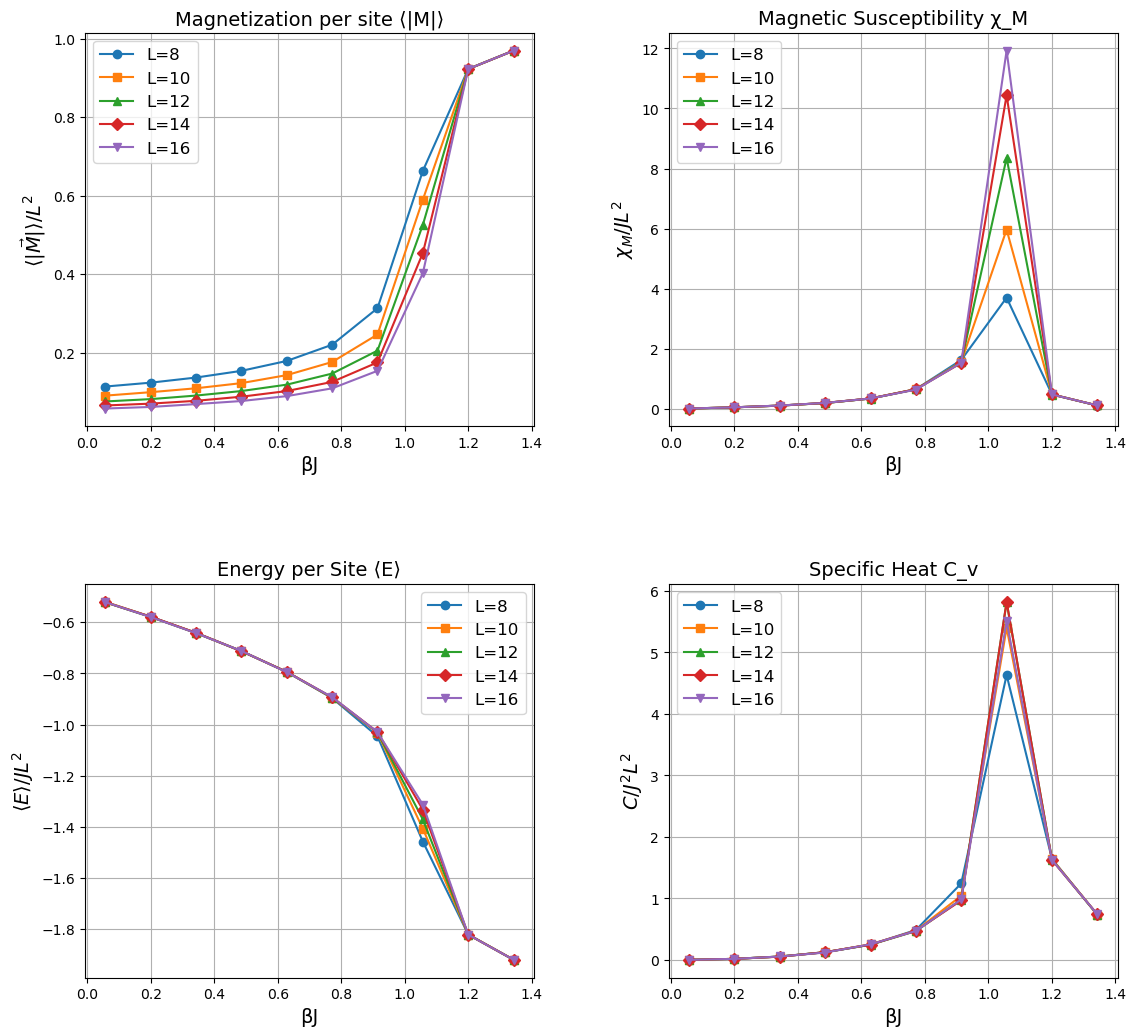

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.show()


In [ ]:
import time 
# Storage
results = {L: {"M_x": [], "chi_M": [], "C_v": [], "E_avg": [], "time": []} for L in L_values}

for T in T_values:
    print(f"\nRunning simulations for T = {T:.3f} (β = {1/T:.3f})...")
    for L in L_values:
        start_time = time.time()  # ⏱ start timer

        M_avg_per_site, chi_M, C_v, E_avg_per_site = run_simulation(
            L, T, sweeps=sweeps, J=J, q=4, burn_frac=0.3
        )

        end_time = time.time()
        elapsed = end_time - start_time

        results[L]["M_x"].append(M_avg_per_site)
        results[L]["chi_M"].append(chi_M)
        results[L]["C_v"].append(C_v)
        results[L]["E_avg"].append(E_avg_per_site)
        results[L]["time"].append(elapsed)

        print(f"  L={L:2d} → done in {elapsed/60:.2f} min | M={M_avg_per_site:.4f}, χ={chi_M:.4e}")



Running simulations for T = 1.053 (β = 0.950)...
  L=12 → done in 8.00 min | M=0.2337, χ=2.1375e+00
  L=14 → done in 9.39 min | M=0.1990, χ=2.1014e+00
  L=16 → done in 10.84 min | M=0.1745, χ=2.0665e+00
  L=18 → done in 6.02 min | M=0.1554, χ=2.0771e+00
  L=20 → done in 5.23 min | M=0.1395, χ=2.0611e+00

Running simulations for T = 0.978 (β = 1.022)...
  L=12 → done in 3.96 min | M=0.3626, χ=5.6009e+00
  L=14 → done in 4.38 min | M=0.3050, χ=5.7081e+00
  L=16 → done in 4.84 min | M=0.2630, χ=5.4985e+00
  L=18 → done in 5.40 min | M=0.2335, χ=5.4743e+00
  L=20 → done in 6.14 min | M=0.2079, χ=5.2888e+00

Running simulations for T = 0.914 (β = 1.094)...
  L=12 → done in 7.93 min | M=0.7270, χ=5.9630e+00
  L=14 → done in 10.05 min | M=0.7077, χ=8.1569e+00
  L=16 → done in 12.39 min | M=0.6939, χ=1.0580e+01
  L=18 → done in 15.20 min | M=0.6749, χ=1.3717e+01
  L=20 → done in 18.35 min | M=0.6609, χ=1.6979e+01

Running simulations for T = 0.857 (β = 1.167)...
  L=12 → done in 10.56 min | M

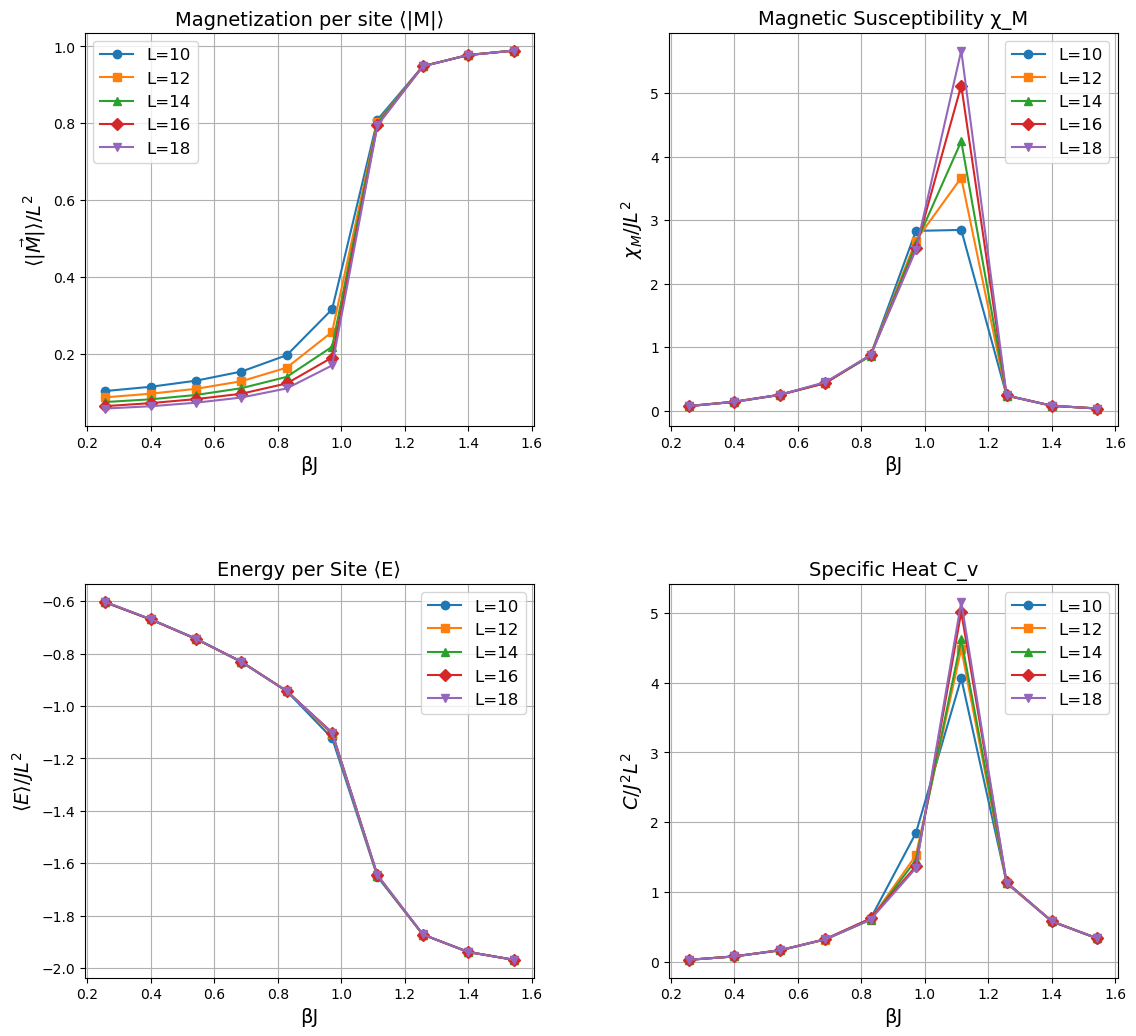

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncq4-10-18.png")
plt.show()


In [11]:
import time 
# Storage
results = {L: {"M_x": [], "chi_M": [], "C_v": [], "E_avg": [], "time": []} for L in L_values}

for T in T_values:
    print(f"\nRunning simulations for T = {T:.3f} (β = {1/T:.3f})...")
    for L in L_values:
        start_time = time.time()  # ⏱ start timer

        M_avg_per_site, chi_M, C_v, E_avg_per_site = run_simulation(
            L, T, sweeps=sweeps, J=J, q=4, burn_frac=0.3
        )

        end_time = time.time()
        elapsed = end_time - start_time

        results[L]["M_x"].append(M_avg_per_site)
        results[L]["chi_M"].append(chi_M)
        results[L]["C_v"].append(C_v)
        results[L]["E_avg"].append(E_avg_per_site)
        results[L]["time"].append(elapsed)

        print(f"  L={L:2d} → done in {elapsed/60:.2f} min | M={M_avg_per_site:.4f}, χ={chi_M:.4e}")



Running simulations for T = 3.889 (β = 0.257)...
  L= 2 → done in 0.46 min | M=0.7036, χ=5.2775e-02
  L= 4 → done in 0.56 min | M=0.5245, χ=4.9023e-02
  L= 8 → done in 0.91 min | M=0.4313, χ=4.3665e-02
  L=16 → done in 2.89 min | M=0.3826, χ=3.9599e-02
  L=32 → done in 9.96 min | M=0.3582, χ=3.9341e-02

Running simulations for T = 2.500 (β = 0.400)...
  L= 2 → done in 0.62 min | M=0.7650, χ=1.0169e-01
  L= 4 → done in 0.75 min | M=0.5516, χ=9.9606e-02
  L= 8 → done in 1.52 min | M=0.4424, χ=8.4975e-02
  L=16 → done in 2.66 min | M=0.3888, χ=7.9239e-02
  L=32 → done in 8.19 min | M=0.3607, χ=7.4525e-02

Running simulations for T = 1.842 (β = 0.543)...
  L= 2 → done in 0.54 min | M=0.8413, χ=1.6444e-01
  L= 4 → done in 0.63 min | M=0.5928, χ=1.9274e-01
  L= 8 → done in 1.64 min | M=0.4611, χ=1.6035e-01
  L=16 → done in 2.72 min | M=0.3963, χ=1.3910e-01
  L=32 → done in 7.79 min | M=0.3649, χ=1.3617e-01

Running simulations for T = 1.458 (β = 0.686)...
  L= 2 → done in 0.51 min | M=0.930

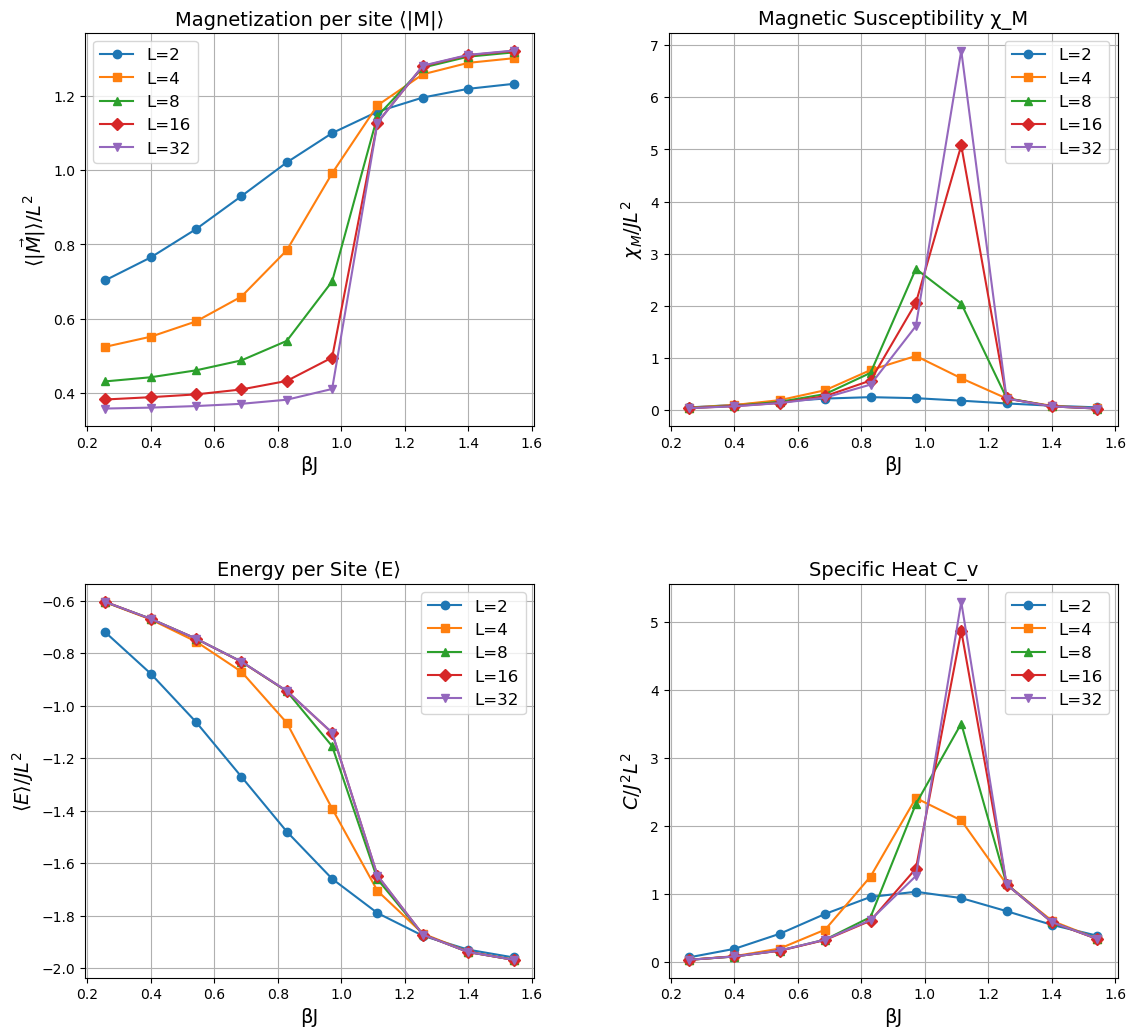

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncq4-2-32.png")
plt.show()


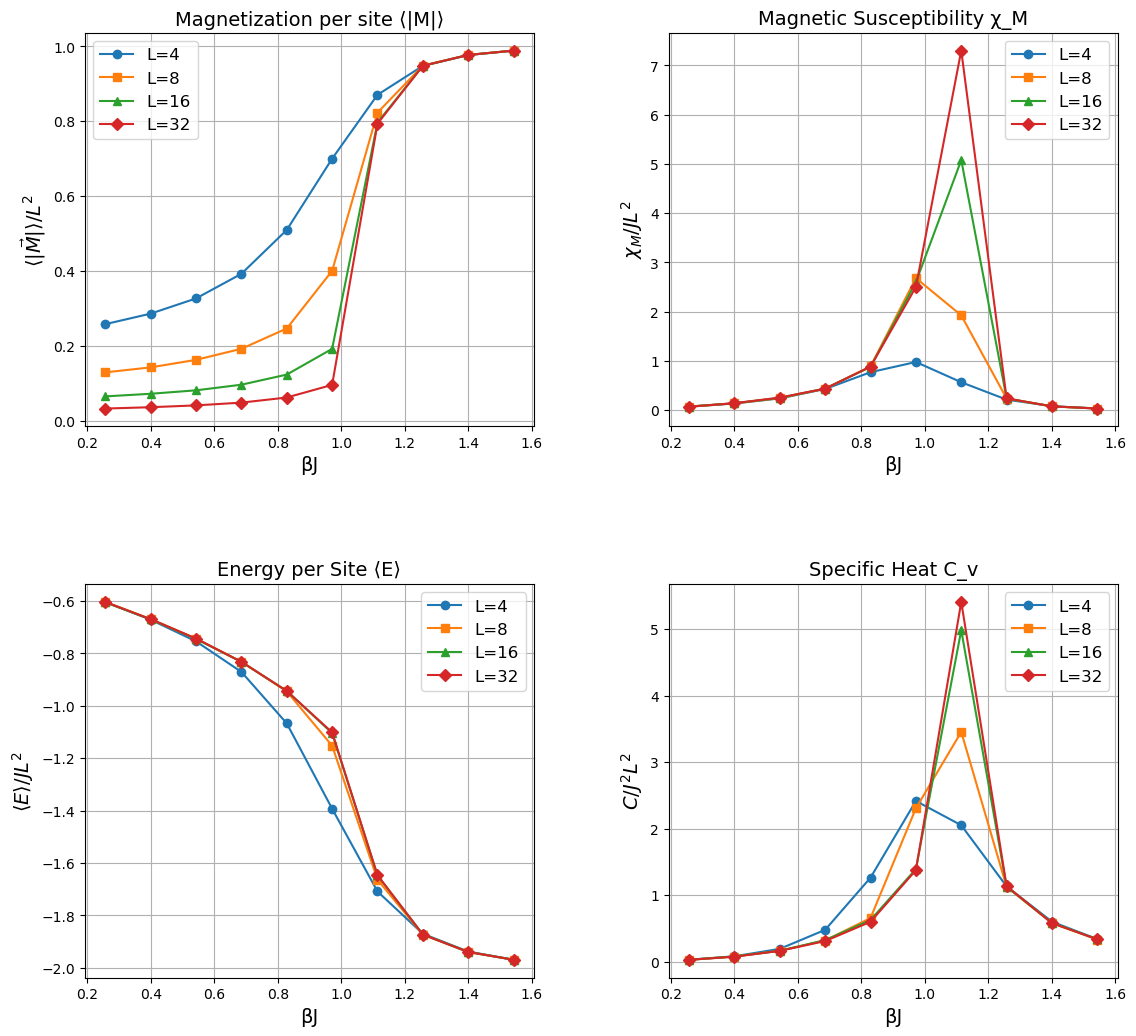

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncq3-4-32.png")
plt.show()


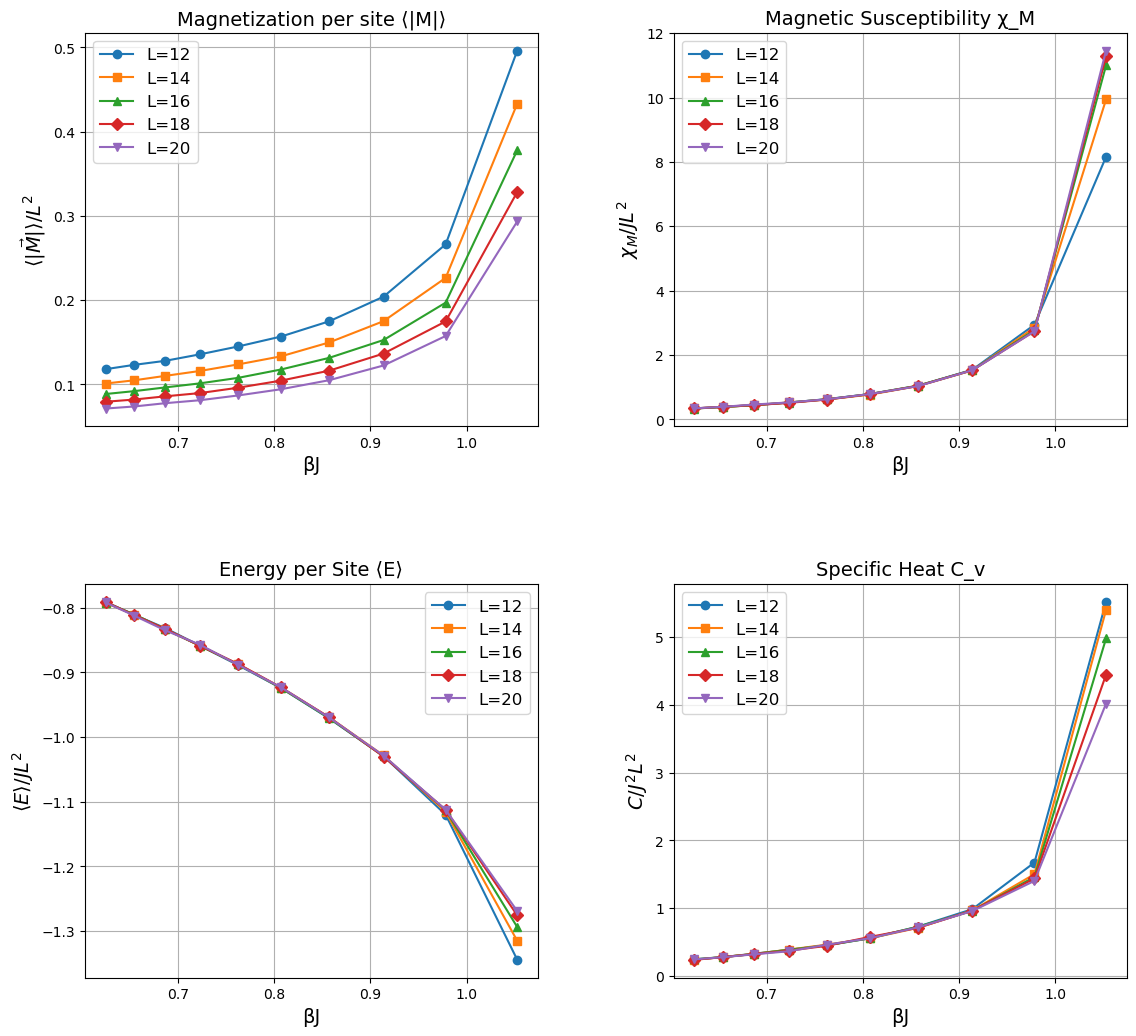

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncq4higherresolution-12-20.png")
plt.show()


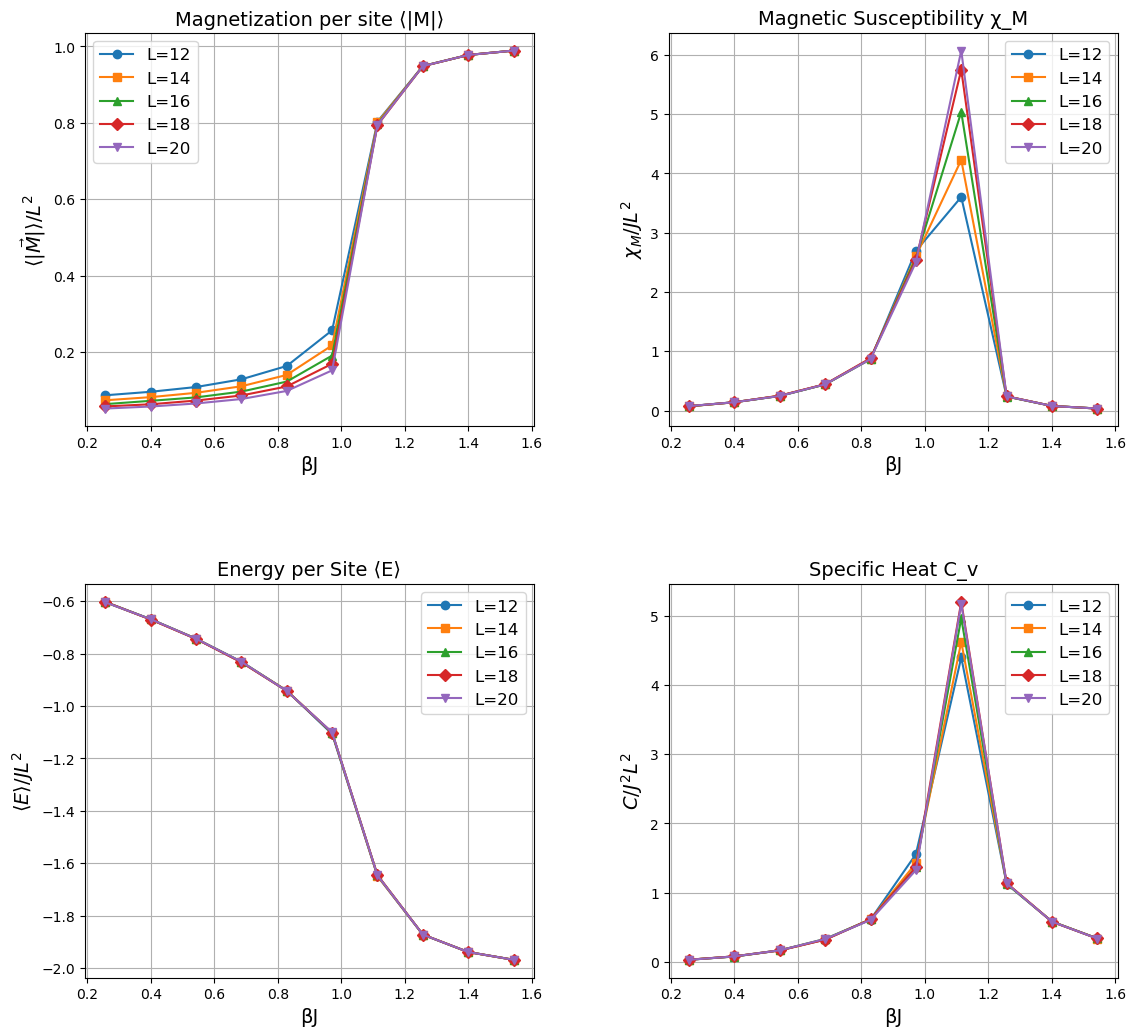

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncq4-12-20.png")
plt.show()


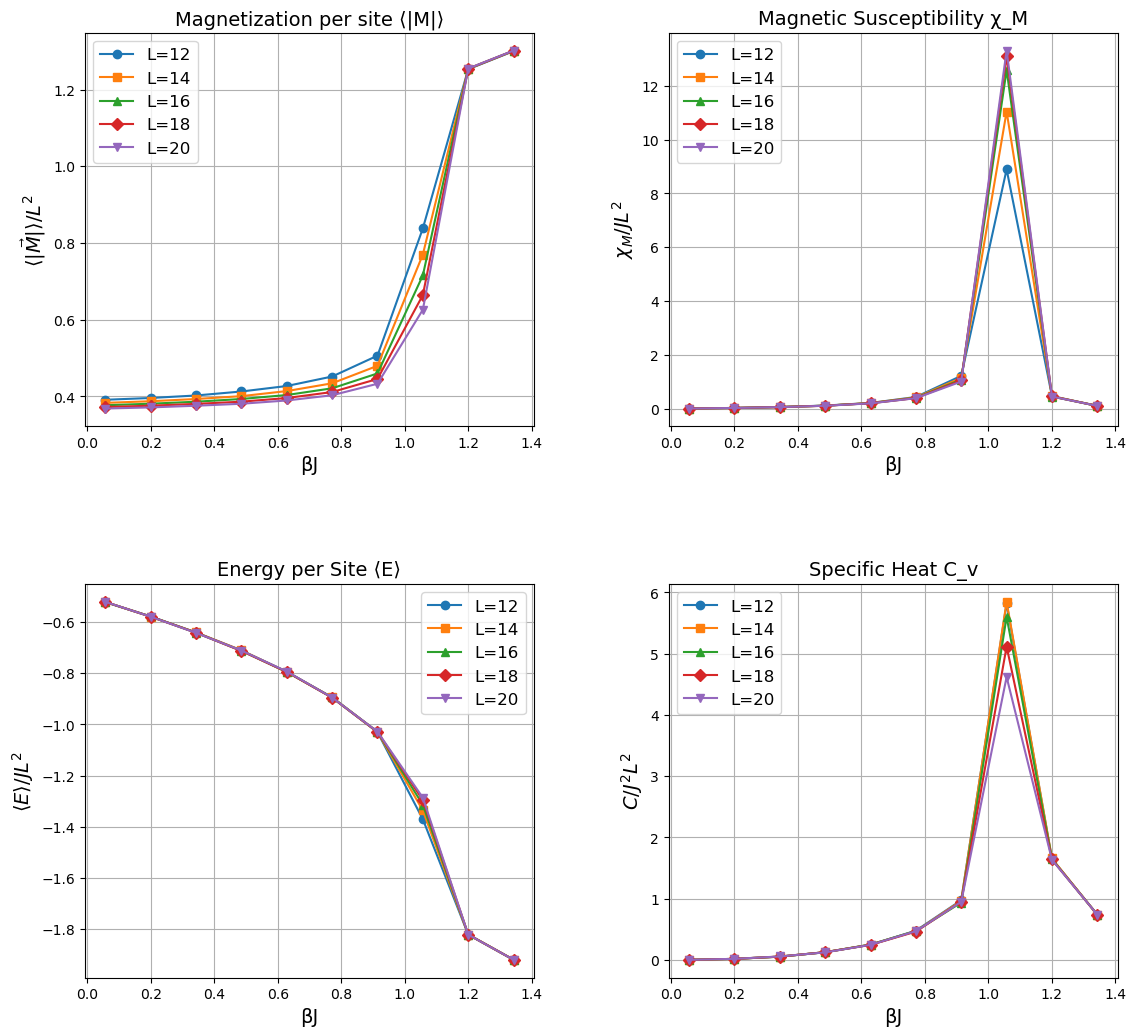

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.show()


Slope (γ/ν) = 1.1859
Intercept = -1.8251
R² = 0.9344


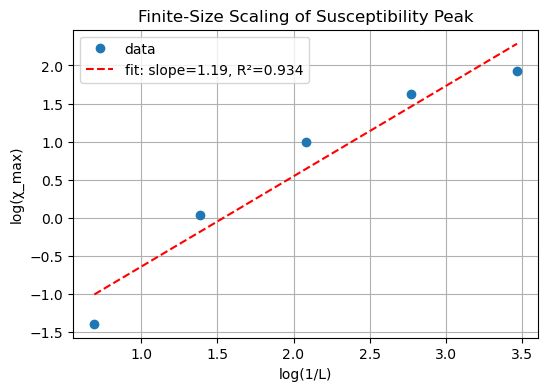

In [15]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi_M"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = -np.log(1/L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(6,4))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.2f}, R²={r_value**2:.3f}")
plt.xlabel("log(1/L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
plt.savefig("FSSq4-2-32.png")
plt.grid(True)
plt.show()


Slope (γ/ν) = 0.9614
Intercept = -1.1875
R² = 0.9551


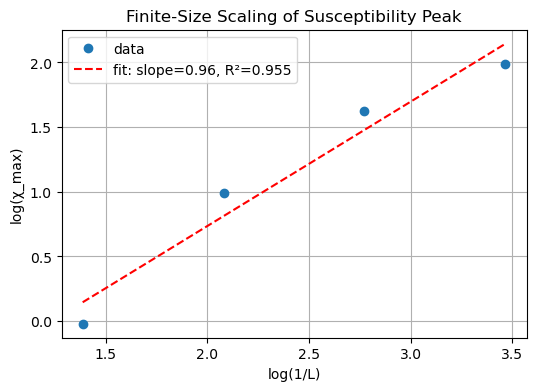

In [29]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi_M"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = -np.log(1/L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(6,4))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.2f}, R²={r_value**2:.3f}")
plt.xlabel("log(1/L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
plt.savefig("FSSq3-4-32.png")
plt.grid(True)
plt.show()


Slope (γ/ν) = 1.0677
Intercept = -1.3648
R² = 0.9877


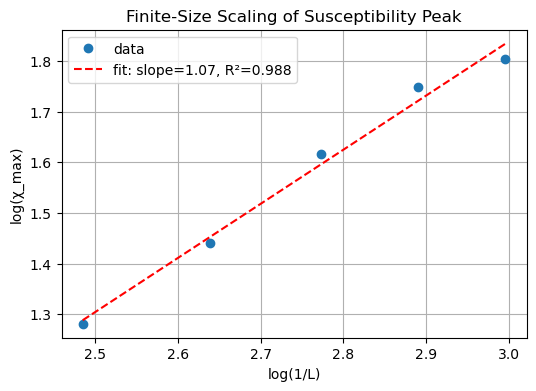

In [13]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi_M"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = -np.log(1/L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(6,4))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.2f}, R²={r_value**2:.3f}")
plt.xlabel("log(1/L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
plt.grid(True)
plt.show()


Extracted γ/ν = 0.7871
Intercept = 0.2861
R² = 0.8936


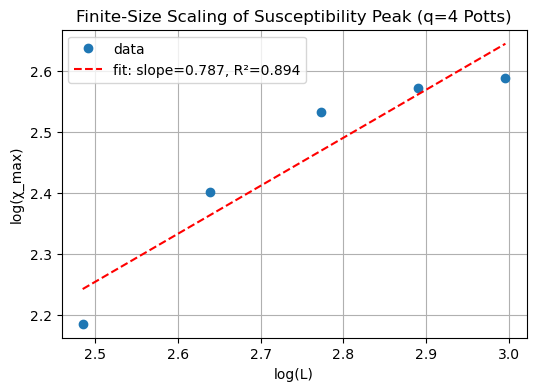

In [25]:
from scipy.stats import linregress
import numpy as np
import matplotlib.pyplot as plt

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = np.array(results[L]["chi_M"])
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values, dtype=float)
L_array = np.array(L_values, dtype=float)

# --- Log-log transformation using log(L), NOT log(1/L) ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

# --- Linear regression ---
slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

gamma_over_nu = slope

# --- Print results ---
print(f"Extracted γ/ν = {gamma_over_nu:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot ---
plt.figure(figsize=(6,4))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--',
         label=f"fit: slope={slope:.3f}, R²={r_value**2:.3f}")

plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak (q=4 Potts)")
plt.legend()
plt.grid(True)
plt.show()


Extracted γ/ν = 0.7983
Intercept = -0.7081
R² = 0.9404


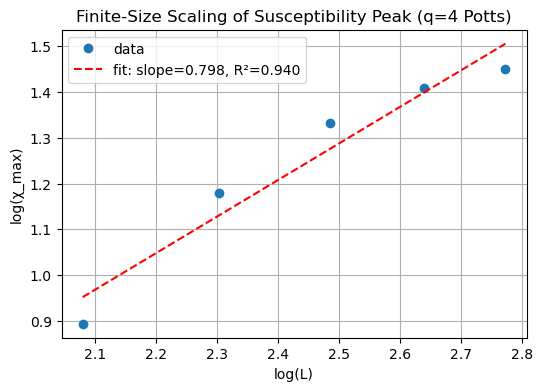

In [39]:
from scipy.stats import linregress
import numpy as np
import matplotlib.pyplot as plt

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = np.array(results[L]["chi_M"])
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values, dtype=float)
L_array = np.array(L_values, dtype=float)

# --- Log-log transformation using log(L), NOT log(1/L) ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

# --- Linear regression ---
slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

gamma_over_nu = slope

# --- Print results ---
print(f"Extracted γ/ν = {gamma_over_nu:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot ---
plt.figure(figsize=(6,4))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--',
         label=f"fit: slope={slope:.3f}, R²={r_value**2:.3f}")

plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak (q=4 Potts)")
plt.legend()
plt.grid(True)
plt.show()


Initial guess for Tc = 0.9459
Best 1/ν ≈ 2.000


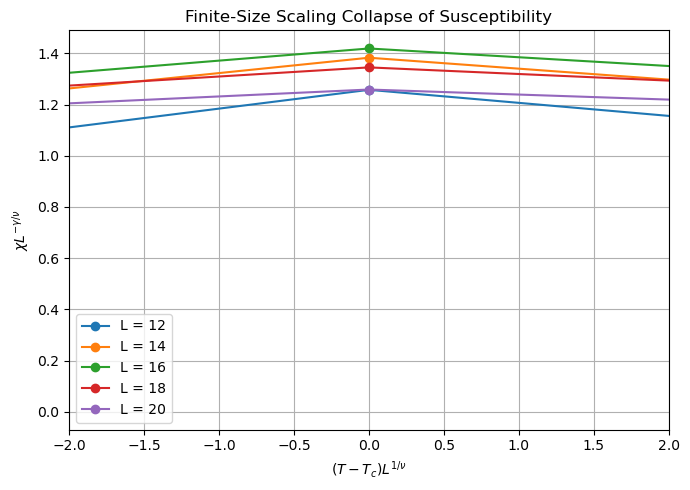

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

# --- Extract gamma/nu from your previous regression ---
gamma_over_nu = abs(slope)   # take positive slope if needed

# --- Guess critical temperature (T_c) based on max χ ---
Tc_guess = T_values[np.argmax(results[L_values[-1]]["chi_M"])]
print(f"Initial guess for Tc = {Tc_guess:.4f}")

# --- Function to evaluate collapse quality (minimize variance between curves) ---
def collapse_quality(inv_nu_guess):
    collapse_curves = []
    for L in L_values:
        chi_vals = np.array(results[L]["chi_M"])
        T_vals = np.array(T_values)
        x_scaled = (T_vals - Tc_guess) * L ** inv_nu_guess
        y_scaled = chi_vals * L ** (-gamma_over_nu)
        # Interpolate to a common x grid
        common_x = np.linspace(-1, 1, 100)
        y_interp = np.interp(common_x, x_scaled, y_scaled)
        collapse_curves.append(y_interp)
    # Measure variance across L
    collapse_curves = np.array(collapse_curves)
    return np.var(collapse_curves, axis=0).mean()

# --- Automatically find best 1/nu for collapse ---
res = minimize_scalar(collapse_quality, bounds=(0.5, 2.0), method='bounded')
inv_nu_best = res.x
print(f"Best 1/ν ≈ {inv_nu_best:.3f}")

# --- Plot scaling collapse ---
plt.figure(figsize=(7,5))
for L in L_values:
    chi_vals = np.array(results[L]["chi_M"])
    T_vals = np.array(T_values)
    x_scaled = (T_vals - Tc_guess) * L ** inv_nu_best
    y_scaled = chi_vals * L ** (-gamma_over_nu)
    plt.plot(x_scaled, y_scaled, 'o-', label=f"L = {L}")

plt.xlabel(r"$(T - T_c) L^{1/\nu}$")
plt.ylabel(r"$\chi L^{-\gamma/\nu}$")
plt.title("Finite-Size Scaling Collapse of Susceptibility")
plt.xlim(-2, 2)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Histograms

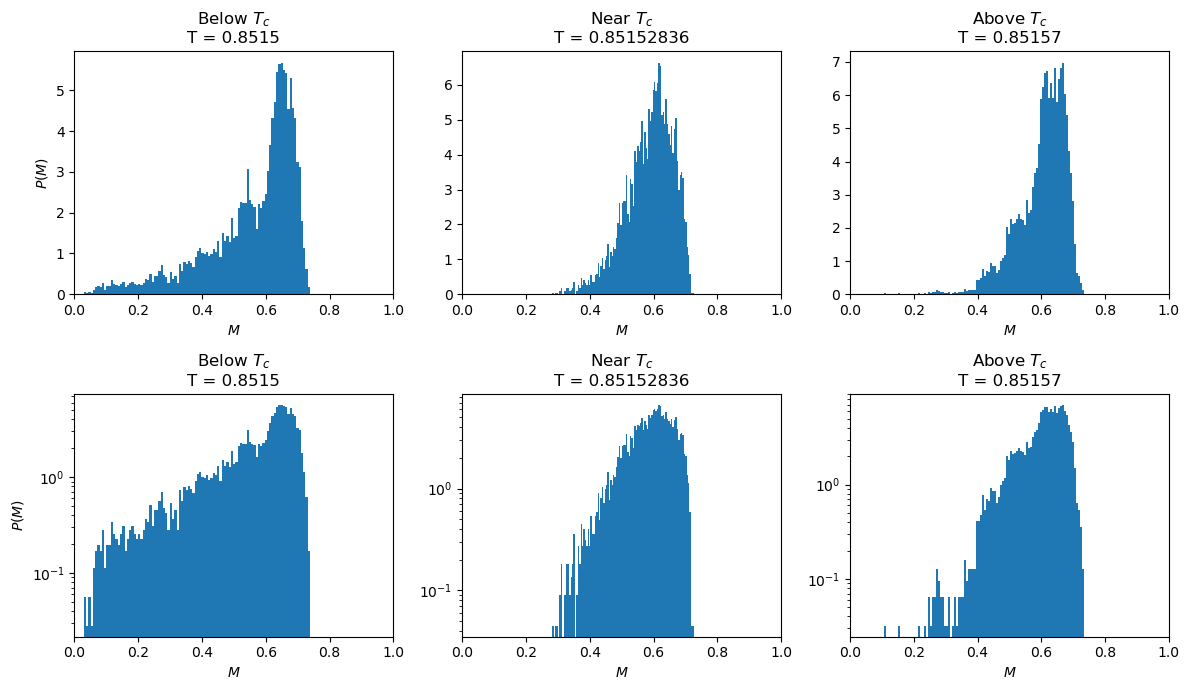

In [5]:
import numpy as np
import matplotlib.pyplot as plt


# =========================================================
# LOAD RAW DATA
# =========================================================

data = np.load(
    "q5_dominant_magnetization_histograms.npz",
    allow_pickle=True
)

M_below = data["M_below"]
M_crit  = data["M_crit"]
M_above = data["M_above"]

T_below = float(data["T_below"])
T_crit  = float(data["T_crit"])
T_above = float(data["T_above"])


# =========================================================
# PLOT RAW DATA
# =========================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(12, 7)
)


# =========================================================
# LINEAR SCALE
# =========================================================

axes[0, 0].hist(
    M_below,
    bins=100,
    density=True
)

axes[0, 0].set_title(
    f"Below $T_c$\nT = {T_below}"
)

axes[0, 0].set_xlabel(r"$M$")
axes[0, 0].set_ylabel(r"$P(M)$")
axes[0, 0].set_xlim(0, 1)


# ---------------------------------------------------------

axes[0, 1].hist(
    M_crit,
    bins=100,
    density=True
)

axes[0, 1].set_title(
    f"Near $T_c$\nT = {T_crit:.8f}"
)

axes[0, 1].set_xlabel(r"$M$")
axes[0, 1].set_xlim(0, 1)


# ---------------------------------------------------------

axes[0, 2].hist(
    M_above,
    bins=100,
    density=True
)

axes[0, 2].set_title(
    f"Above $T_c$\nT = {T_above}"
)

axes[0, 2].set_xlabel(r"$M$")
axes[0, 2].set_xlim(0, 1)


# =========================================================
# SEMI-LOG SCALE
# =========================================================

axes[1, 0].hist(
    M_below,
    bins=100,
    density=True
)

axes[1, 0].set_yscale("log")

axes[1, 0].set_title(
    f"Below $T_c$\nT = {T_below}"
)

axes[1, 0].set_xlabel(r"$M$")
axes[1, 0].set_ylabel(r"$P(M)$")
axes[1, 0].set_xlim(0, 1)


# ---------------------------------------------------------

axes[1, 1].hist(
    M_crit,
    bins=100,
    density=True
)

axes[1, 1].set_yscale("log")

axes[1, 1].set_title(
    f"Near $T_c$\nT = {T_crit:.8f}"
)

axes[1, 1].set_xlabel(r"$M$")
axes[1, 1].set_xlim(0, 1)


# ---------------------------------------------------------

axes[1, 2].hist(
    M_above,
    bins=100,
    density=True
)

axes[1, 2].set_yscale("log")

axes[1, 2].set_title(
    f"Above $T_c$\nT = {T_above}"
)

axes[1, 2].set_xlabel(r"$M$")
axes[1, 2].set_xlim(0, 1)


# =========================================================
# FORMAT
# =========================================================

plt.tight_layout()

plt.savefig(
    "q5_raw_data_linear_semilog.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Exact Tc for q = 5: 0.85152836

Building neighbor table...
Neighbor table ready.

Running BELOW Tc: T = 0.8515

Running NEAR Tc: T = 0.8515283616124156

Running ABOVE Tc: T = 0.85157

MAGNETIZATION STATISTICS

Below Tc:
Mean M = 0.596511
Min M  = 0.031010
Max M  = 0.736462

Near Tc:
Mean M = 0.583957
Min M  = 0.051743
Max M  = 0.735203

Above Tc:
Mean M = 0.557883
Min M  = 0.034920
Max M  = 0.727764

Histogram data saved.


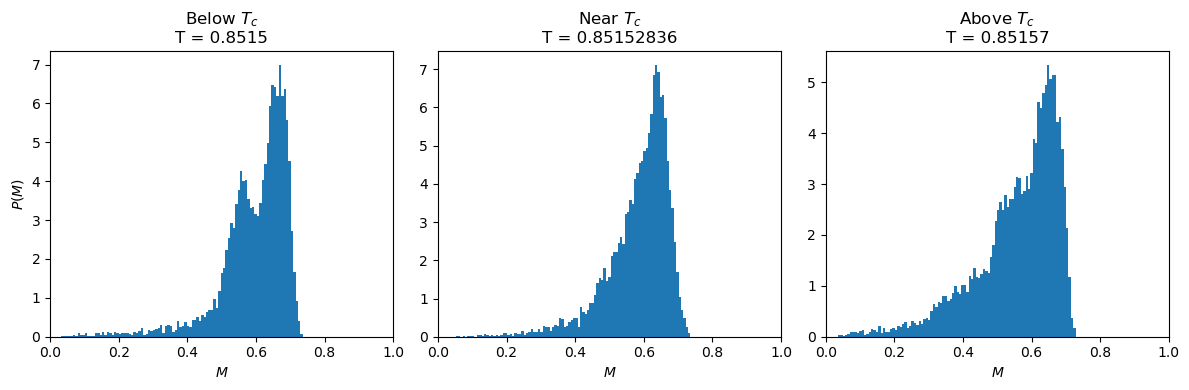

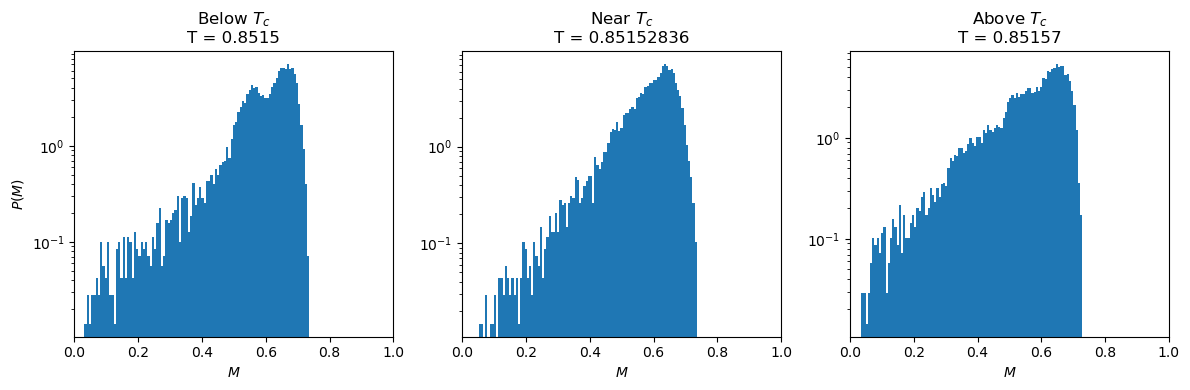

In [3]:
import numpy as np
import matplotlib.pyplot as plt


# =========================================================
# PARAMETERS
# =========================================================

L = 256
q = 5
J = 1.0

N = L * L


# =========================================================
# EXACT CRITICAL TEMPERATURE
#
# 2D q-state Potts model:
#
# Tc = J / ln(1 + sqrt(q))
# =========================================================

Tc_exact = J / np.log(1.0 + np.sqrt(q))

print(f"Exact Tc for q = {q}: {Tc_exact:.8f}")


# =========================================================
# TEMPERATURES
#
# q = 5 has a weak first-order transition.
#
# These temperatures probe very close to Tc.
# =========================================================

T_below = 0.85150
T_crit  = Tc_exact
T_above = 0.85157


# =========================================================
# MONTE CARLO PARAMETERS
# =========================================================

# Number of Wolff sweeps
#
# One Wolff sweep means:
# keep generating clusters until the total number
# of flipped spins is approximately N.
sweeps = 20000

# Number of initial sweeps discarded
burn_sweeps = 10000

# Measure every this many sweeps
sample_interval = 1


# =========================================================
# RANDOM INITIAL CONFIGURATION
# =========================================================

def new_state(L, q):

    return np.random.randint(
        0,
        q,
        size=L * L,
        dtype=np.int8
    )


# =========================================================
# INITIAL COLOR COUNTS
# =========================================================

def initial_counts(spins, q):

    return np.bincount(
        spins,
        minlength=q
    ).astype(np.int64)


# =========================================================
# DOMINANT-COLOR POTTS MAGNETIZATION
#
# Let
#
#     n_max = maximum population among all q colors
#
# Then
#
#             q n_max - N
#     M = -------------------
#          (q - 1) N
#
# Properties:
#
# Disordered state:
#
#     n_max approximately N/q
#
#     M approximately 0
#
# Fully ordered state:
#
#     n_max = N
#
#     M = 1
#
# =========================================================

def magnetization_dominant(counts, N, q):

    nmax = np.max(counts)

    M = (
        q * nmax - N
    ) / (
        (q - 1) * N
    )

    return M


# =========================================================
# BUILD PERIODIC NEIGHBOR TABLE
#
# Every lattice site has:
#
# right
# left
# up
# down
# =========================================================

def build_neighbors(L):

    N = L * L

    neighbors = np.empty(
        (N, 4),
        dtype=np.int32
    )

    for x in range(L):

        for y in range(L):

            i = x * L + y

            right = (
                x * L
                + ((y + 1) % L)
            )

            left = (
                x * L
                + ((y - 1) % L)
            )

            up = (
                ((x - 1) % L) * L
                + y
            )

            down = (
                ((x + 1) % L) * L
                + y
            )

            neighbors[i, 0] = right
            neighbors[i, 1] = left
            neighbors[i, 2] = up
            neighbors[i, 3] = down

    return neighbors


# =========================================================
# WOLFF CLUSTER UPDATE
#
# For the Potts Hamiltonian:
#
# H = -J sum_<ij> delta(s_i, s_j)
#
# the bond probability is
#
# p = 1 - exp(-beta J)
#
# =========================================================

def wolff_cluster(
    spins,
    counts,
    neighbors,
    beta,
    q,
    cluster_id,
    marks,
    stack,
    cluster_sites
):

    N = spins.size


    # -----------------------------------------------------
    # RANDOM SEED
    # -----------------------------------------------------

    seed = np.random.randint(N)

    seed_state = spins[seed]


    # -----------------------------------------------------
    # CHOOSE A DIFFERENT POTTS STATE
    # -----------------------------------------------------

    new_state = np.random.randint(q - 1)

    if new_state >= seed_state:

        new_state += 1


    # -----------------------------------------------------
    # BOND PROBABILITY
    # -----------------------------------------------------

    p = 1.0 - np.exp(-beta * J)


    # -----------------------------------------------------
    # START NEW CLUSTER
    # -----------------------------------------------------

    cluster_id += 1

    stack_size = 0
    cluster_size = 0


    # Mark seed as belonging to this cluster

    marks[seed] = cluster_id


    # Put seed into stack

    stack[stack_size] = seed

    stack_size += 1


    # Store cluster site

    cluster_sites[cluster_size] = seed

    cluster_size += 1


    # -----------------------------------------------------
    # GROW CLUSTER
    # -----------------------------------------------------

    while stack_size > 0:

        stack_size -= 1

        site = stack[stack_size]


        # Check four nearest neighbors

        for neighbor in neighbors[site]:


            # Already part of current cluster?

            if marks[neighbor] == cluster_id:

                continue


            # Neighbor must have the same original spin

            if spins[neighbor] != seed_state:

                continue


            # Add bond probabilistically

            if np.random.random() < p:


                marks[neighbor] = cluster_id


                # Add neighbor to stack

                stack[stack_size] = neighbor

                stack_size += 1


                # Store cluster member

                cluster_sites[cluster_size] = neighbor

                cluster_size += 1


    # -----------------------------------------------------
    # FLIP / RECOLOR ENTIRE CLUSTER
    # -----------------------------------------------------

    cluster = cluster_sites[:cluster_size]

    spins[cluster] = new_state


    # -----------------------------------------------------
    # UPDATE COLOR COUNTS
    # -----------------------------------------------------

    counts[seed_state] -= cluster_size

    counts[new_state] += cluster_size


    return cluster_size, cluster_id


# =========================================================
# ONE WOLFF SWEEP
#
# A sweep is complete when the total number of spins
# contained in generated clusters reaches approximately N.
# =========================================================

def wolff_sweep(
    spins,
    counts,
    neighbors,
    beta,
    q,
    cluster_id,
    marks,
    stack,
    cluster_sites
):

    N = spins.size

    flipped = 0


    while flipped < N:

        cluster_size, cluster_id = wolff_cluster(

            spins=spins,

            counts=counts,

            neighbors=neighbors,

            beta=beta,

            q=q,

            cluster_id=cluster_id,

            marks=marks,

            stack=stack,

            cluster_sites=cluster_sites
        )


        flipped += cluster_size


    return cluster_id


# =========================================================
# MAGNETIZATION HISTOGRAM
# =========================================================

def magnetization_histogram(

    L,
    T,
    q,
    neighbors,
    sweeps,
    burn_sweeps,
    sample_interval

):

    N = L * L

    beta = 1.0 / T


    # -----------------------------------------------------
    # RANDOM INITIAL STATE
    # -----------------------------------------------------

    spins = new_state(
        L,
        q
    )


    # -----------------------------------------------------
    # INITIAL COLOR POPULATIONS
    # -----------------------------------------------------

    counts = initial_counts(
        spins,
        q
    )


    # -----------------------------------------------------
    # ARRAYS REQUIRED BY FAST CLUSTER ALGORITHM
    # -----------------------------------------------------

    marks = np.zeros(
        N,
        dtype=np.int64
    )

    stack = np.empty(
        N,
        dtype=np.int32
    )

    cluster_sites = np.empty(
        N,
        dtype=np.int32
    )


    # Current cluster identification number

    cluster_id = 0


    # -----------------------------------------------------
    # STORE MAGNETIZATION MEASUREMENTS
    # -----------------------------------------------------

    M_samples = []


    # =====================================================
    # MONTE CARLO SIMULATION
    # =====================================================

    for sweep in range(sweeps):


        # -------------------------------------------------
        # PERFORM ONE WOLFF SWEEP
        # -------------------------------------------------

        cluster_id = wolff_sweep(

            spins=spins,

            counts=counts,

            neighbors=neighbors,

            beta=beta,

            q=q,

            cluster_id=cluster_id,

            marks=marks,

            stack=stack,

            cluster_sites=cluster_sites
        )


        # -------------------------------------------------
        # BURN-IN
        # -------------------------------------------------

        if sweep < burn_sweeps:

            continue


        # -------------------------------------------------
        # SAMPLING INTERVAL
        # -------------------------------------------------

        if (
            (sweep - burn_sweeps)
            % sample_interval
            != 0
        ):

            continue


        # -------------------------------------------------
        # DOMINANT-COLOR MAGNETIZATION
        # -------------------------------------------------

        M = magnetization_dominant(

            counts,

            N,

            q
        )


        # Store measurement

        M_samples.append(M)


    return np.array(M_samples)


# =========================================================
# BUILD NEIGHBOR TABLE
# =========================================================

print("\nBuilding neighbor table...")

neighbors = build_neighbors(L)

print("Neighbor table ready.")


# =========================================================
# RUN BELOW Tc
# =========================================================

print("\n========================================")

print(f"Running BELOW Tc: T = {T_below}")

print("========================================")


M_below = magnetization_histogram(

    L=L,

    T=T_below,

    q=q,

    neighbors=neighbors,

    sweeps=sweeps,

    burn_sweeps=burn_sweeps,

    sample_interval=sample_interval
)


# =========================================================
# RUN AT / NEAR Tc
# =========================================================

print("\n========================================")

print(f"Running NEAR Tc: T = {T_crit}")

print("========================================")


M_crit = magnetization_histogram(

    L=L,

    T=T_crit,

    q=q,

    neighbors=neighbors,

    sweeps=sweeps,

    burn_sweeps=burn_sweeps,

    sample_interval=sample_interval
)


# =========================================================
# RUN ABOVE Tc
# =========================================================

print("\n========================================")

print(f"Running ABOVE Tc: T = {T_above}")

print("========================================")


M_above = magnetization_histogram(

    L=L,

    T=T_above,

    q=q,

    neighbors=neighbors,

    sweeps=sweeps,

    burn_sweeps=burn_sweeps,

    sample_interval=sample_interval
)


# =========================================================
# PRINT BASIC STATISTICS
# =========================================================

print("\n========================================")

print("MAGNETIZATION STATISTICS")

print("========================================")


print(
    f"\nBelow Tc:"
)

print(
    f"Mean M = {np.mean(M_below):.6f}"
)

print(
    f"Min M  = {np.min(M_below):.6f}"
)

print(
    f"Max M  = {np.max(M_below):.6f}"
)


print(
    f"\nNear Tc:"
)

print(
    f"Mean M = {np.mean(M_crit):.6f}"
)

print(
    f"Min M  = {np.min(M_crit):.6f}"
)

print(
    f"Max M  = {np.max(M_crit):.6f}"
)


print(
    f"\nAbove Tc:"
)

print(
    f"Mean M = {np.mean(M_above):.6f}"
)

print(
    f"Min M  = {np.min(M_above):.6f}"
)

print(
    f"Max M  = {np.max(M_above):.6f}"
)


# =========================================================
# SAVE DATA
# =========================================================

np.savez_compressed(

    "q5_dominant_magnetization_histograms1.npz",

    M_below=M_below,

    M_crit=M_crit,

    M_above=M_above,

    L=L,

    q=q,

    J=J,

    T_below=T_below,

    T_crit=T_crit,

    T_above=T_above,

    Tc_exact=Tc_exact,

    sweeps=sweeps,

    burn_sweeps=burn_sweeps,

    sample_interval=sample_interval
)


print("\nHistogram data saved.")


# =========================================================
# PLOT HISTOGRAMS
# =========================================================

# =========================================================
# PLOT 1: LINEAR Y-AXIS
# =========================================================

plt.figure(
    figsize=(12, 4)
)

# ---------------------------------------------------------
# BELOW Tc
# ---------------------------------------------------------

plt.subplot(1, 3, 1)

plt.hist(
    M_below,
    bins=100,
    density=True
)

plt.xlim(0, 1)

plt.title(
    f"Below $T_c$\nT = {T_below}"
)

plt.xlabel(
    r"$M$"
)

plt.ylabel(
    r"$P(M)$"
)


# ---------------------------------------------------------
# NEAR Tc
# ---------------------------------------------------------

plt.subplot(1, 3, 2)

plt.hist(
    M_crit,
    bins=100,
    density=True
)

plt.xlim(0, 1)

plt.title(
    f"Near $T_c$\nT = {T_crit:.8f}"
)

plt.xlabel(
    r"$M$"
)


# ---------------------------------------------------------
# ABOVE Tc
# ---------------------------------------------------------

plt.subplot(1, 3, 3)

plt.hist(
    M_above,
    bins=100,
    density=True
)

plt.xlim(0, 1)

plt.title(
    f"Above $T_c$\nT = {T_above}"
)

plt.xlabel(
    r"$M$"
)

plt.tight_layout()

plt.show()


# =========================================================
# PLOT 2: LOGARITHMIC Y-AXIS
# =========================================================

plt.figure(
    figsize=(12, 4)
)

# ---------------------------------------------------------
# BELOW Tc
# ---------------------------------------------------------

plt.subplot(1, 3, 1)

plt.hist(
    M_below,
    bins=100,
    density=True
)

plt.yscale("log")

plt.xlim(0, 1)

plt.title(
    f"Below $T_c$\nT = {T_below}"
)

plt.xlabel(
    r"$M$"
)

plt.ylabel(
    r"$P(M)$"
)


# ---------------------------------------------------------
# NEAR Tc
# ---------------------------------------------------------

plt.subplot(1, 3, 2)

plt.hist(
    M_crit,
    bins=100,
    density=True
)

plt.yscale("log")

plt.xlim(0, 1)

plt.title(
    f"Near $T_c$\nT = {T_crit:.8f}"
)

plt.xlabel(
    r"$M$"
)


# ---------------------------------------------------------
# ABOVE Tc
# ---------------------------------------------------------

plt.subplot(1, 3, 3)

plt.hist(
    M_above,
    bins=100,
    density=True
)

plt.yscale("log")

plt.xlim(0, 1)

plt.title(
    f"Above $T_c$\nT = {T_above}"
)

plt.xlabel(
    r"$M$"
)

plt.tight_layout()

plt.show()

In [7]:
import numpy as np
import matplotlib.pyplot as plt


# =========================================================
# PARAMETERS
# =========================================================

L = 256
q = 5
J = 1.0

# ---------------------------------------------------------
# q = 5 Potts critical temperature
#
# Tc = J / ln(1 + sqrt(q))
# ---------------------------------------------------------

Tc_exact = J / np.log(1.0 + np.sqrt(q))

print(f"Exact Tc for q={q}: {Tc_exact:.6f}")

# ---------------------------------------------------------
# Temperatures
#
# IMPORTANT:
# T_above must actually be ABOVE Tc.
# ---------------------------------------------------------

T_below = 0.8514
T_crit  = 0.8515
T_above = 0.8516


# =========================================================
# MONTE CARLO PARAMETERS
# =========================================================

# Number of Wolff sweeps, NOT individual clusters.
#
# One sweep = continue flipping clusters until
# approximately N=L^2 spins have been flipped.

sweeps = 5000

# Number of initial sweeps discarded
burn_sweeps = 2500

# Take one measurement every this many Wolff sweeps
sample_interval = 1


# =========================================================
# INITIAL CONFIGURATION
# =========================================================

def new_state(L, q):

    return np.random.randint(
        0,
        q,
        size=L * L,
        dtype=np.int8
    )


# =========================================================
# INITIAL COLOR COUNTS
# =========================================================

def initial_counts(spins, q):

    return np.bincount(
        spins,
        minlength=q
    ).astype(np.int64)


def magnetization_dominant(counts, N, q):

    # Number of sites occupied by the most populated color
    nmax = np.max(counts)

    # Normalized Potts order parameter
    M = (q * nmax - N) / ((q - 1) * N)

    return M
# =========================================================
# q COMPONENT MAGNETIZATIONS
# =========================================================
#
# m_k = n_k/N - 1/q
#
# where
#
# n_k = number of lattice sites having color k
#
# Therefore:
#
# m_k ranges approximately from
#
#     -1/q  <= m_k <= 1 - 1/q
#
# For q=5:
#
#     -0.2 <= m_k <= 0.8
#
# Completely disordered state:
#
#     n_k/N = 1/5
#
#     m_k = 0
#
# Fully ordered state in color k:
#
#     n_k/N = 1
#
#     m_k = 4/5
#
# =========================================================

#def q_magnetizations(counts, N, q):

    #probabilities = counts / N

    #m = probabilities - 1.0 / q

    #return m


# =========================================================
# BUILD PERIODIC NEIGHBOR TABLE
# =========================================================
#
# This is done only ONCE.
#
# Each site has four neighbors:
#
#     right
#     left
#     up
#     down
#
# Using a precomputed table is MUCH faster than repeatedly
# constructing (x,y) tuples and Python sets.
#
# =========================================================

def build_neighbors(L):

    N = L * L

    neighbors = np.empty(
        (N, 4),
        dtype=np.int32
    )

    for x in range(L):

        for y in range(L):

            i = x * L + y

            right = x * L + ((y + 1) % L)

            left = x * L + ((y - 1) % L)

            up = ((x - 1) % L) * L + y

            down = ((x + 1) % L) * L + y

            neighbors[i, 0] = right
            neighbors[i, 1] = left
            neighbors[i, 2] = up
            neighbors[i, 3] = down

    return neighbors


# =========================================================
# FAST WOLFF CLUSTER
# =========================================================
#
# This is still the Wolff algorithm.
#
# The important difference is that we use:
#
#   - integer arrays
#   - a stack
#   - a marker array
#
# instead of Python sets containing coordinate tuples.
#
# =========================================================

def wolff_cluster(
    spins,
    counts,
    neighbors,
    beta,
    q,
    cluster_id,
    marks,
    stack,
    cluster_sites
):

    N = spins.size

    # -----------------------------------------------------
    # Choose random seed
    # -----------------------------------------------------

    seed = np.random.randint(N)

    seed_state = spins[seed]

    # -----------------------------------------------------
    # Choose a different Potts state
    # -----------------------------------------------------

    new_state = np.random.randint(q - 1)

    if new_state >= seed_state:
        new_state += 1

    # -----------------------------------------------------
    # Wolff bond probability
    #
    # For H = -J sum delta(s_i,s_j):
    #
    # p = 1 - exp(-beta J)
    # -----------------------------------------------------

    p = 1.0 - np.exp(-beta * J)

    # -----------------------------------------------------
    # Start cluster
    # -----------------------------------------------------

    cluster_id += 1

    stack_size = 0
    cluster_size = 0

    marks[seed] = cluster_id

    stack[stack_size] = seed
    stack_size += 1

    cluster_sites[cluster_size] = seed
    cluster_size += 1

    # -----------------------------------------------------
    # Grow cluster
    # -----------------------------------------------------

    while stack_size > 0:

        stack_size -= 1

        site = stack[stack_size]

        # Examine four nearest neighbors
        for neighbor in neighbors[site]:

            # Already in cluster?
            if marks[neighbor] == cluster_id:
                continue

            # Must have same original spin
            if spins[neighbor] != seed_state:
                continue

            # Add according to Wolff probability
            if np.random.random() < p:

                marks[neighbor] = cluster_id

                stack[stack_size] = neighbor
                stack_size += 1

                cluster_sites[cluster_size] = neighbor
                cluster_size += 1

    # -----------------------------------------------------
    # Flip cluster
    # -----------------------------------------------------

    cluster = cluster_sites[:cluster_size]

    spins[cluster] = new_state

    # -----------------------------------------------------
    # Update color counts
    # -----------------------------------------------------

    counts[seed_state] -= cluster_size
    counts[new_state] += cluster_size

    return cluster_size, cluster_id


# =========================================================
# ONE WOLFF SWEEP
# =========================================================
#
# One sweep is defined as:
#
# Continue making Wolff clusters until the total number
# of flipped spins is approximately N.
#
# This is much better than saying:
#
# "one cluster = one sweep"
#
# because Wolff clusters have different sizes.
#
# =========================================================

def wolff_sweep(
    spins,
    counts,
    neighbors,
    beta,
    q,
    cluster_id,
    marks,
    stack,
    cluster_sites
):

    N = spins.size

    flipped = 0

    while flipped < N:

        cluster_size, cluster_id = wolff_cluster(
            spins,
            counts,
            neighbors,
            beta,
            q,
            cluster_id,
            marks,
            stack,
            cluster_sites
        )

        flipped += cluster_size

    return cluster_id

# =========================================================
# COLLECT q MAGNETIZATION HISTOGRAM DATA
# =========================================================

def magnetization_histogram(
    L,
    T,
    q,
    neighbors,
    sweeps,
    burn_sweeps,
    sample_interval
):

    N = L * L

    beta = 1.0 / T

    # -----------------------------------------------------
    # Initial random configuration
    # -----------------------------------------------------

    spins = new_state(L, q)

    counts = initial_counts(
        spins,
        q
    )
    for step in range(sweeps):

        spins, counts = wolff_cluster(
            spins,
            T,
            counts,
            q
        )

        # Burn-in
        if step < burn_steps:
            continue

        # Sampling
        if (step - burn_steps) % sample_interval != 0:
            continue

        # Dominant-color magnetization
        M = magnetization_dominant(
            counts,
            N,
            q
        )

        M_samples.append(M)

    return np.array(M_samples)

# =========================================================
# BUILD NEIGHBOR TABLE
# =========================================================

print("\nBuilding neighbor table...")

neighbors = build_neighbors(L)

print("Neighbor table ready.")


# =========================================================
# RUN BELOW Tc
# =========================================================

print("\n====================================")
print(f"Running BELOW Tc: T = {T_below}")
print("====================================")

M_below = magnetization_histogram(
    L=L,
    T=T_below,
    q=q,
    neighbors=neighbors,
    sweeps=sweeps,
    burn_sweeps=burn_sweeps,
    sample_interval=sample_interval
)


# =========================================================
# RUN NEAR Tc
# =========================================================

print("\n====================================")
print(f"Running NEAR Tc: T = {T_crit}")
print("====================================")

M_crit = magnetization_histogram(
    L=L,
    T=T_crit,
    q=q,
    neighbors=neighbors,
    sweeps=sweeps,
    burn_sweeps=burn_sweeps,
    sample_interval=sample_interval
)


# =========================================================
# RUN ABOVE Tc
# =========================================================

print("\n====================================")
print(f"Running ABOVE Tc: T = {T_above}")
print("====================================")

M_above = magnetization_histogram(
    L=L,
    T=T_above,
    q=q,
    neighbors=neighbors,
    sweeps=sweeps,
    burn_sweeps=burn_sweeps,
    sample_interval=sample_interval
)


# =========================================================
# CHECK THE q MAGNETIZATION SUM RULE
# =========================================================
#
# Since
#
#     m_k = n_k/N - 1/q
#
# summing over all q colors gives
#
#     sum_k m_k
#
#   = sum_k n_k/N - q/q
#
#   = 1 - 1
#
#   = 0
#
# =========================================================

print("\nChecking sum rule:")

for condition_name, data in [
    ("Below Tc", M_below),
    ("Near Tc", M_crit),
    ("Above Tc", M_above)
]:

    # Stack all q arrays
    arr = np.array(data)

    # Sum over colors
    sums = np.sum(arr, axis=0)

    print(
        f"{condition_name}: "
        f"max |sum(m_k)| = {np.max(np.abs(sums)):.3e}"
    )


# =========================================================
# SAVE DATA
# =========================================================

np.savez_compressed(
    "q5_component_magnetization_histograms.npz",

    M_below=np.array(M_below, dtype=object),
    M_crit=np.array(M_crit, dtype=object),
    M_above=np.array(M_above, dtype=object),

    L=L,
    q=q,
    J=J,

    T_below=T_below,
    T_crit=T_crit,
    T_above=T_above,

    Tc_exact=Tc_exact,

    sweeps=sweeps,
    burn_sweeps=burn_sweeps,
    sample_interval=sample_interval
)

print("\nHistogram data saved.")


# =========================================================
# PLOT
# =========================================================
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)

plt.hist(
    M_below,
    bins=80,
    density=True
)

plt.yscale("log")

plt.xlim(0, 1)

plt.title(f"Below Tc: T={T_below}")
plt.xlabel(r"$M$")
plt.ylabel(r"$P(M)$")


plt.subplot(1,3,2)

plt.hist(
    M_crit,
    bins=80,
    density=True
)

plt.yscale("log")

plt.xlim(0, 1)

plt.title(f"Near Tc: T={T_crit}")
plt.xlabel(r"$M$")


plt.subplot(1,3,3)

plt.hist(
    M_above,
    bins=80,
    density=True
)

plt.yscale("log")

plt.xlim(0, 1)

plt.title(f"Above Tc: T={T_above}")
plt.xlabel(r"$M$")

plt.tight_layout()
plt.show()

Exact Tc for q=5: 0.851528

Building neighbor table...
Neighbor table ready.

Running BELOW Tc: T = 0.8514


TypeError: wolff_cluster() missing 5 required positional arguments: 'q', 'cluster_id', 'marks', 'stack', and 'cluster_sites'

Exact Tc for q=5: 0.851528

Building neighbor table...
Neighbor table ready.

Running BELOW Tc: T = 0.8514

Running NEAR Tc: T = 0.8515

Running ABOVE Tc: T = 0.8516

Checking sum rule:
Below Tc: max |sum(m_k)| = 0.000e+00
Near Tc: max |sum(m_k)| = 0.000e+00
Above Tc: max |sum(m_k)| = 0.000e+00

Histogram data saved.


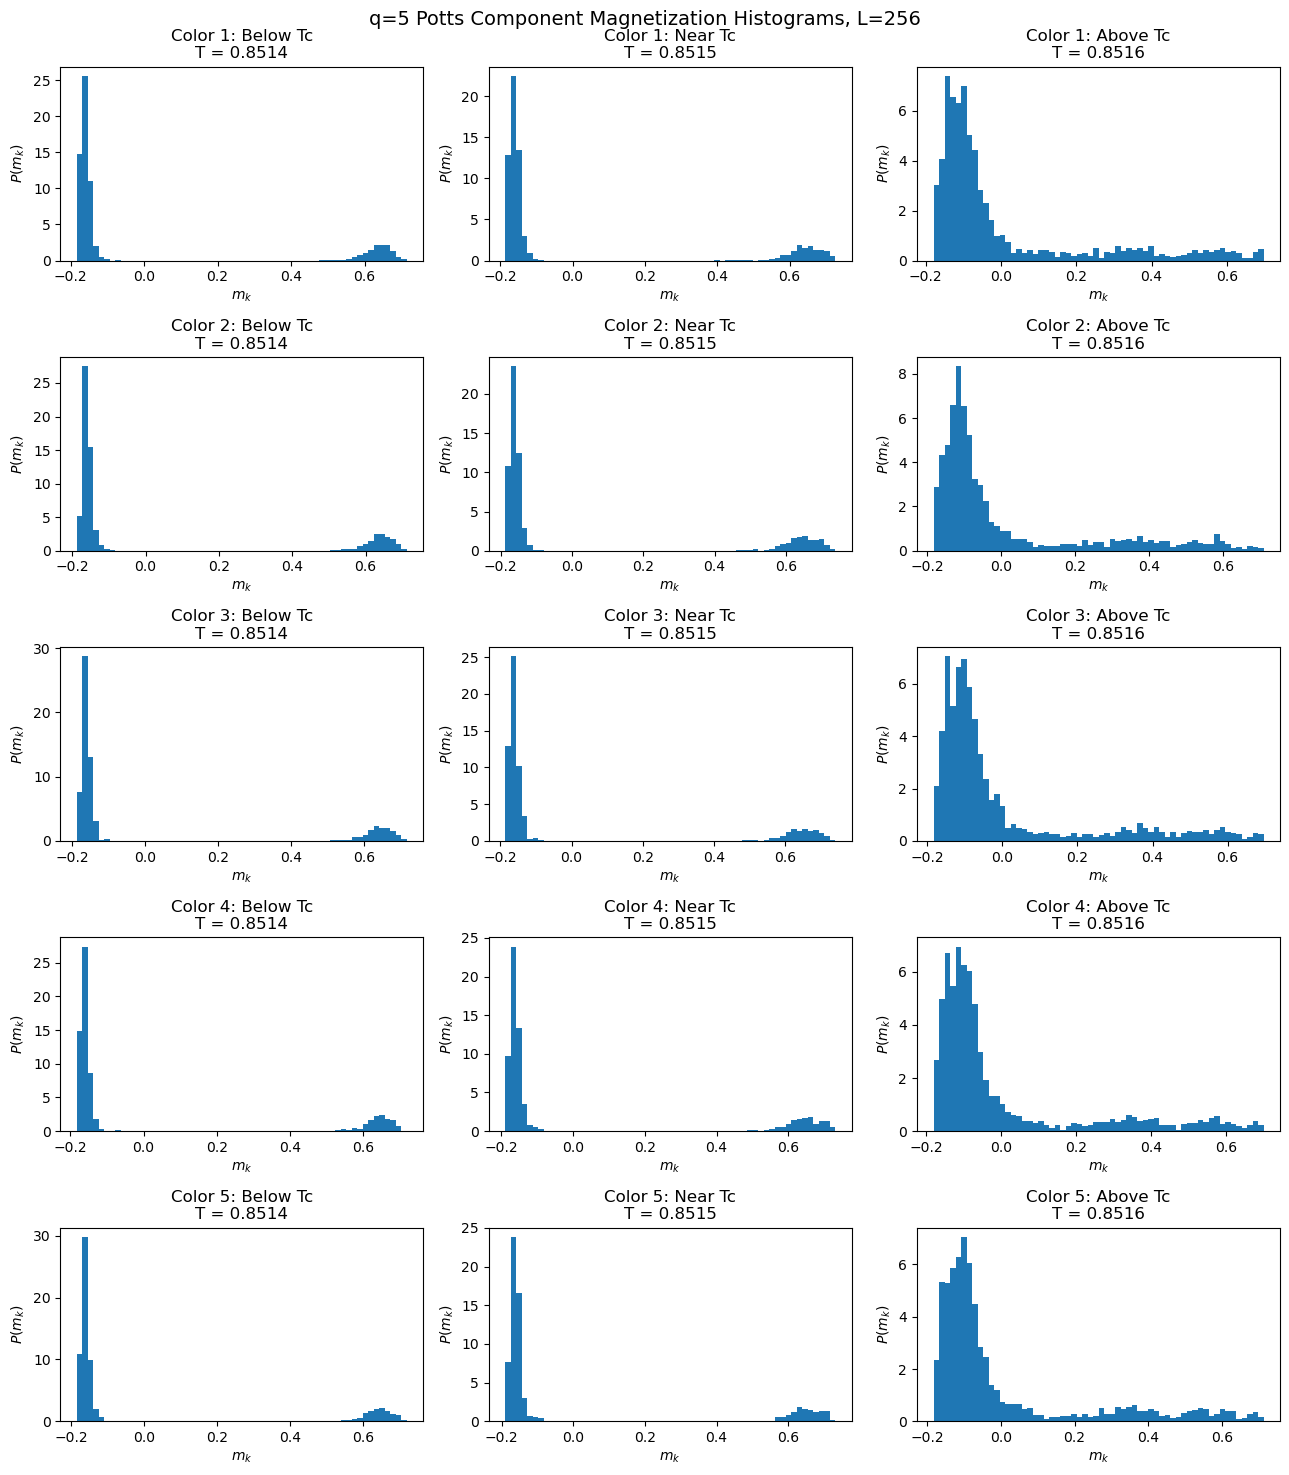

In [7]:
import numpy as np
import matplotlib.pyplot as plt


# =========================================================
# PARAMETERS
# =========================================================

L = 256
q = 5
J = 1.0

# ---------------------------------------------------------
# q = 5 Potts critical temperature
#
# Tc = J / ln(1 + sqrt(q))
# ---------------------------------------------------------

Tc_exact = J / np.log(1.0 + np.sqrt(q))

print(f"Exact Tc for q={q}: {Tc_exact:.6f}")

# ---------------------------------------------------------
# Temperatures
#
# IMPORTANT:
# T_above must actually be ABOVE Tc.
# ---------------------------------------------------------

T_below = 0.8514
T_crit  = 0.8515
T_above = 0.8516


# =========================================================
# MONTE CARLO PARAMETERS
# =========================================================

# Number of Wolff sweeps, NOT individual clusters.
#
# One sweep = continue flipping clusters until
# approximately N=L^2 spins have been flipped.

sweeps = 5000

# Number of initial sweeps discarded
burn_sweeps = 2500

# Take one measurement every this many Wolff sweeps
sample_interval = 1


# =========================================================
# INITIAL CONFIGURATION
# =========================================================

def new_state(L, q):

    return np.random.randint(
        0,
        q,
        size=L * L,
        dtype=np.int8
    )


# =========================================================
# INITIAL COLOR COUNTS
# =========================================================

def initial_counts(spins, q):

    return np.bincount(
        spins,
        minlength=q
    ).astype(np.int64)


# =========================================================
# q COMPONENT MAGNETIZATIONS
# =========================================================
#
# m_k = n_k/N - 1/q
#
# where
#
# n_k = number of lattice sites having color k
#
# Therefore:
#
# m_k ranges approximately from
#
#     -1/q  <= m_k <= 1 - 1/q
#
# For q=5:
#
#     -0.2 <= m_k <= 0.8
#
# Completely disordered state:
#
#     n_k/N = 1/5
#
#     m_k = 0
#
# Fully ordered state in color k:
#
#     n_k/N = 1
#
#     m_k = 4/5
#
# =========================================================

#def q_magnetizations(counts, N, q):

    #probabilities = counts / N

    #m = probabilities - 1.0 / q

    #return m
def q_magnetizations(counts, N, q):

    sigma = (q * counts - N) / ((q - 1) * N)

    return sigma

# =========================================================
# BUILD PERIODIC NEIGHBOR TABLE
# =========================================================
#
# This is done only ONCE.
#
# Each site has four neighbors:
#
#     right
#     left
#     up
#     down
#
# Using a precomputed table is MUCH faster than repeatedly
# constructing (x,y) tuples and Python sets.
#
# =========================================================

def build_neighbors(L):

    N = L * L

    neighbors = np.empty(
        (N, 4),
        dtype=np.int32
    )

    for x in range(L):

        for y in range(L):

            i = x * L + y

            right = x * L + ((y + 1) % L)

            left = x * L + ((y - 1) % L)

            up = ((x - 1) % L) * L + y

            down = ((x + 1) % L) * L + y

            neighbors[i, 0] = right
            neighbors[i, 1] = left
            neighbors[i, 2] = up
            neighbors[i, 3] = down

    return neighbors


# =========================================================
# FAST WOLFF CLUSTER
# =========================================================
#
# This is still the Wolff algorithm.
#
# The important difference is that we use:
#
#   - integer arrays
#   - a stack
#   - a marker array
#
# instead of Python sets containing coordinate tuples.
#
# =========================================================

def wolff_cluster(
    spins,
    counts,
    neighbors,
    beta,
    q,
    cluster_id,
    marks,
    stack,
    cluster_sites
):

    N = spins.size

    # -----------------------------------------------------
    # Choose random seed
    # -----------------------------------------------------

    seed = np.random.randint(N)

    seed_state = spins[seed]

    # -----------------------------------------------------
    # Choose a different Potts state
    # -----------------------------------------------------

    new_state = np.random.randint(q - 1)

    if new_state >= seed_state:
        new_state += 1

    # -----------------------------------------------------
    # Wolff bond probability
    #
    # For H = -J sum delta(s_i,s_j):
    #
    # p = 1 - exp(-beta J)
    # -----------------------------------------------------

    p = 1.0 - np.exp(-beta * J)

    # -----------------------------------------------------
    # Start cluster
    # -----------------------------------------------------

    cluster_id += 1

    stack_size = 0
    cluster_size = 0

    marks[seed] = cluster_id

    stack[stack_size] = seed
    stack_size += 1

    cluster_sites[cluster_size] = seed
    cluster_size += 1

    # -----------------------------------------------------
    # Grow cluster
    # -----------------------------------------------------

    while stack_size > 0:

        stack_size -= 1

        site = stack[stack_size]

        # Examine four nearest neighbors
        for neighbor in neighbors[site]:

            # Already in cluster?
            if marks[neighbor] == cluster_id:
                continue

            # Must have same original spin
            if spins[neighbor] != seed_state:
                continue

            # Add according to Wolff probability
            if np.random.random() < p:

                marks[neighbor] = cluster_id

                stack[stack_size] = neighbor
                stack_size += 1

                cluster_sites[cluster_size] = neighbor
                cluster_size += 1

    # -----------------------------------------------------
    # Flip cluster
    # -----------------------------------------------------

    cluster = cluster_sites[:cluster_size]

    spins[cluster] = new_state

    # -----------------------------------------------------
    # Update color counts
    # -----------------------------------------------------

    counts[seed_state] -= cluster_size
    counts[new_state] += cluster_size

    return cluster_size, cluster_id


# =========================================================
# ONE WOLFF SWEEP
# =========================================================
#
# One sweep is defined as:
#
# Continue making Wolff clusters until the total number
# of flipped spins is approximately N.
#
# This is much better than saying:
#
# "one cluster = one sweep"
#
# because Wolff clusters have different sizes.
#
# =========================================================

def wolff_sweep(
    spins,
    counts,
    neighbors,
    beta,
    q,
    cluster_id,
    marks,
    stack,
    cluster_sites
):

    N = spins.size

    flipped = 0

    while flipped < N:

        cluster_size, cluster_id = wolff_cluster(
            spins,
            counts,
            neighbors,
            beta,
            q,
            cluster_id,
            marks,
            stack,
            cluster_sites
        )

        flipped += cluster_size

    return cluster_id


# =========================================================
# COLLECT q MAGNETIZATION HISTOGRAM DATA
# =========================================================

def magnetization_histogram(
    L,
    T,
    q,
    neighbors,
    sweeps,
    burn_sweeps,
    sample_interval
):

    N = L * L

    beta = 1.0 / T

    # -----------------------------------------------------
    # Initial random configuration
    # -----------------------------------------------------

    spins = new_state(L, q)

    counts = initial_counts(
        spins,
        q
    )

    # -----------------------------------------------------
    # Arrays used by fast Wolff algorithm
    # -----------------------------------------------------

    marks = np.zeros(
        N,
        dtype=np.int32
    )

    stack = np.empty(
        N,
        dtype=np.int32
    )

    cluster_sites = np.empty(
        N,
        dtype=np.int32
    )

    cluster_id = 0

    # -----------------------------------------------------
    # One list for every color
    #
    # M_samples[0] -> m_1
    # M_samples[1] -> m_2
    # ...
    # M_samples[q-1] -> m_q
    # -----------------------------------------------------

    M_samples = [
        []
        for _ in range(q)
    ]

    # =====================================================
    # MONTE CARLO
    # =====================================================

    for sweep in range(sweeps):

        # -------------------------------------------------
        # Perform ONE Wolff sweep
        # -------------------------------------------------

        cluster_id = wolff_sweep(
            spins,
            counts,
            neighbors,
            beta,
            q,
            cluster_id,
            marks,
            stack,
            cluster_sites
        )

        # -------------------------------------------------
        # Burn-in
        # -------------------------------------------------

        if sweep < burn_sweeps:
            continue

        # -------------------------------------------------
        # Sampling interval
        # -------------------------------------------------

        if (sweep - burn_sweeps) % sample_interval != 0:
            continue

        # -------------------------------------------------
        # Calculate all q magnetizations
        # -------------------------------------------------

        m = q_magnetizations(
            counts,
            N,
            q
        )

        # -------------------------------------------------
        # Store every color
        # -------------------------------------------------

        for k in range(q):

            M_samples[k].append(
                m[k]
            )

    # -----------------------------------------------------
    # Convert to NumPy arrays
    # -----------------------------------------------------

    M_samples = [
        np.asarray(samples)
        for samples in M_samples
    ]

    return M_samples


# =========================================================
# BUILD NEIGHBOR TABLE
# =========================================================

print("\nBuilding neighbor table...")

neighbors = build_neighbors(L)

print("Neighbor table ready.")


# =========================================================
# RUN BELOW Tc
# =========================================================

print("\n====================================")
print(f"Running BELOW Tc: T = {T_below}")
print("====================================")

M_below = magnetization_histogram(
    L=L,
    T=T_below,
    q=q,
    neighbors=neighbors,
    sweeps=sweeps,
    burn_sweeps=burn_sweeps,
    sample_interval=sample_interval
)


# =========================================================
# RUN NEAR Tc
# =========================================================

print("\n====================================")
print(f"Running NEAR Tc: T = {T_crit}")
print("====================================")

M_crit = magnetization_histogram(
    L=L,
    T=T_crit,
    q=q,
    neighbors=neighbors,
    sweeps=sweeps,
    burn_sweeps=burn_sweeps,
    sample_interval=sample_interval
)


# =========================================================
# RUN ABOVE Tc
# =========================================================

print("\n====================================")
print(f"Running ABOVE Tc: T = {T_above}")
print("====================================")

M_above = magnetization_histogram(
    L=L,
    T=T_above,
    q=q,
    neighbors=neighbors,
    sweeps=sweeps,
    burn_sweeps=burn_sweeps,
    sample_interval=sample_interval
)


# =========================================================
# CHECK THE q MAGNETIZATION SUM RULE
# =========================================================
#
# Since
#
#     m_k = n_k/N - 1/q
#
# summing over all q colors gives
#
#     sum_k m_k
#
#   = sum_k n_k/N - q/q
#
#   = 1 - 1
#
#   = 0
#
# =========================================================

print("\nChecking sum rule:")

for condition_name, data in [
    ("Below Tc", M_below),
    ("Near Tc", M_crit),
    ("Above Tc", M_above)
]:

    # Stack all q arrays
    arr = np.array(data)

    # Sum over colors
    sums = np.sum(arr, axis=0)

    print(
        f"{condition_name}: "
        f"max |sum(m_k)| = {np.max(np.abs(sums)):.3e}"
    )


# =========================================================
# SAVE DATA
# =========================================================

np.savez_compressed(
    "q5_component_magnetization_histograms.npz",

    M_below=np.array(M_below, dtype=object),
    M_crit=np.array(M_crit, dtype=object),
    M_above=np.array(M_above, dtype=object),

    L=L,
    q=q,
    J=J,

    T_below=T_below,
    T_crit=T_crit,
    T_above=T_above,

    Tc_exact=Tc_exact,

    sweeps=sweeps,
    burn_sweeps=burn_sweeps,
    sample_interval=sample_interval
)

print("\nHistogram data saved.")


# =========================================================
# PLOT
# =========================================================

fig, axes = plt.subplots(
    q,
    3,
    figsize=(13, 3 * q),
    sharex=False
)


for k in range(q):

    # =====================================================
    # COLOR k+1
    # =====================================================

    # -----------------------------------------------------
    # BELOW Tc
    # -----------------------------------------------------

    axes[k, 0].hist(
        M_below[k],
        bins=60,
        density=True
    )

    axes[k, 0].set_title(
        f"Color {k+1}: Below Tc\nT = {T_below}"
    )

    axes[k, 0].set_xlabel(
        r"$m_k$"
    )

    axes[k, 0].set_ylabel(
        r"$P(m_k)$"
    )

    # -----------------------------------------------------
    # NEAR Tc
    # -----------------------------------------------------

    axes[k, 1].hist(
        M_crit[k],
        bins=60,
        density=True
    )

    axes[k, 1].set_title(
        f"Color {k+1}: Near Tc\nT = {T_crit}"
    )

    axes[k, 1].set_xlabel(
        r"$m_k$"
    )

    axes[k, 1].set_ylabel(
        r"$P(m_k)$"
    )

    # -----------------------------------------------------
    # ABOVE Tc
    # -----------------------------------------------------

    axes[k, 2].hist(
        M_above[k],
        bins=60,
        density=True
    )

    axes[k, 2].set_title(
        f"Color {k+1}: Above Tc\nT = {T_above}"
    )

    axes[k, 2].set_xlabel(
        r"$m_k$"
    )

    axes[k, 2].set_ylabel(
        r"$P(m_k)$"
    )


plt.suptitle(
    f"q={q} Potts Component Magnetization Histograms, L={L}",
    fontsize=14
)

plt.tight_layout()

plt.show()

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.random import randint, random

# =========================================================
# PARAMETERS
# =========================================================

L = 256
q = 5

T_below = 0.84
T_crit = 0.8515
T_above = 0.86

sweeps = 200000
burn_frac = 0.5
sample_interval = 1


# =========================================================
# INITIALIZATION
# =========================================================

def new_state(L, q):

    return np.random.randint(
        0, q,
        size=(L, L)
    )


def initial_counts(spins, q):

    return np.bincount(
        spins.ravel(),
        minlength=q
    )


# =========================================================
# q COMPONENT MAGNETIZATIONS
# =========================================================

def q_magnetizations(counts, N, q):

    # counts[k] = number of lattice sites
    # belonging to color k

    probabilities = counts / N

    # m_k = n_k/N - 1/q

    m = probabilities - 1.0 / q

    return m


# =========================================================
# WOLFF CLUSTER
# =========================================================

def wolff_cluster(spins, T, counts, q):

    L = spins.shape[0]

    beta = 1.0 / T

    # -----------------------------------------------------
    # Choose random seed
    # -----------------------------------------------------

    i, j = randint(0, L, size=2)

    seed_state = spins[i, j]

    # -----------------------------------------------------
    # Choose a DIFFERENT Potts state
    # -----------------------------------------------------

    new_state_val = randint(0, q - 1)

    if new_state_val >= seed_state:
        new_state_val += 1

    # -----------------------------------------------------
    # Wolff bond probability
    # -----------------------------------------------------

    p = 1 - np.exp(-beta)

    # -----------------------------------------------------
    # Cluster initialization
    # -----------------------------------------------------

    cluster = {(i, j)}
    pocket = {(i, j)}

    # -----------------------------------------------------
    # Grow cluster
    # -----------------------------------------------------

    while pocket:

        x, y = pocket.pop()

        for dx, dy in [
            (1, 0),
            (-1, 0),
            (0, 1),
            (0, -1)
        ]:

            nx = (x + dx) % L
            ny = (y + dy) % L

            if (nx, ny) not in cluster:

                if spins[nx, ny] == seed_state:

                    if random() < p:

                        cluster.add((nx, ny))
                        pocket.add((nx, ny))

    # -----------------------------------------------------
    # Flip cluster
    # -----------------------------------------------------

    cluster_size = len(cluster)

    for x, y in cluster:

        spins[x, y] = new_state_val

    # -----------------------------------------------------
    # Update color counts
    # -----------------------------------------------------

    counts[seed_state] -= cluster_size

    counts[new_state_val] += cluster_size

    return spins, counts


# =========================================================
# COLLECT q MAGNETIZATION SAMPLES
# =========================================================

def magnetization_histogram(
    L,
    T,
    q=5,
    sweeps=200000,
    burn_frac=0.5,
    sample_interval=50
):

    # -----------------------------------------------------
    # Initial configuration
    # -----------------------------------------------------

    spins = new_state(L, q)

    counts = initial_counts(spins, q)

    N = L * L

    burn_steps = int(
        burn_frac * sweeps
    )

    # -----------------------------------------------------
    # One array for every color
    # -----------------------------------------------------

    M_samples = [
        []
        for _ in range(q)
    ]

    # -----------------------------------------------------
    # Monte Carlo simulation
    # -----------------------------------------------------

    for step in range(sweeps):

        spins, counts = wolff_cluster(
            spins,
            T,
            counts,
            q
        )

        # -------------------------------------------------
        # Burn-in
        # -------------------------------------------------

        if step < burn_steps:
            continue

        # -------------------------------------------------
        # Sampling interval
        # -------------------------------------------------

        if (step - burn_steps) % sample_interval != 0:
            continue

        # -------------------------------------------------
        # Calculate all q magnetizations
        # -------------------------------------------------

        m = q_magnetizations(
            counts,
            N,
            q
        )

        # -------------------------------------------------
        # Store each color separately
        # -------------------------------------------------

        for k in range(q):

            M_samples[k].append(
                m[k]
            )

    # -----------------------------------------------------
    # Convert to numpy arrays
    # -----------------------------------------------------

    M_samples = [
        np.array(samples)
        for samples in M_samples
    ]

    return M_samples


# =========================================================
# RUN BELOW Tc
# =========================================================

print("Running BELOW Tc...")

M_below = magnetization_histogram(
    L,
    T_below,
    q,
    sweeps,
    burn_frac,
    sample_interval
)


# =========================================================
# RUN NEAR Tc
# =========================================================

print("Running NEAR Tc...")

M_crit = magnetization_histogram(
    L,
    T_crit,
    q,
    sweeps,
    burn_frac,
    sample_interval
)


# =========================================================
# RUN ABOVE Tc
# =========================================================

print("Running ABOVE Tc...")

M_above = magnetization_histogram(
    L,
    T_above,
    q,
    sweeps,
    burn_frac,
    sample_interval
)


# =========================================================
# PLOT q HISTOGRAMS
# =========================================================

fig, axes = plt.subplots(
    q,
    3,
    figsize=(12, 3*q)
)

for k in range(q):

    # -----------------------------------------------------
    # Below Tc
    # -----------------------------------------------------

    axes[k, 0].hist(
        M_below[k],
        bins=60,
        density=True
    )

    axes[k, 0].set_title(
        f"Color {k+1}: Below Tc"
    )

    axes[k, 0].set_xlabel(
        r"$m_k$"
    )

    axes[k, 0].set_ylabel(
        "P($m_k$)"
    )

    # -----------------------------------------------------
    # Near Tc
    # -----------------------------------------------------

    axes[k, 1].hist(
        M_crit[k],
        bins=60,
        density=True
    )

    axes[k, 1].set_title(
        f"Color {k+1}: Near Tc"
    )

    axes[k, 1].set_xlabel(
        r"$m_k$"
    )

    # -----------------------------------------------------
    # Above Tc
    # -----------------------------------------------------

    axes[k, 2].hist(
        M_above[k],
        bins=60,
        density=True
    )

    axes[k, 2].set_title(
        f"Color {k+1}: Above Tc"
    )

    axes[k, 2].set_xlabel(
        r"$m_k$"
    )


plt.tight_layout()
plt.show()


# =========================================================
# CHECK THE SUM RULE
# =========================================================

# For every configuration:
#
# m1 + m2 + ... + mq = 0

print("\nExpected sum rule:")
print("m1 + m2 + ... + mq = 0")

Running BELOW Tc...


KeyboardInterrupt: 

Running BELOW Tc...
Running NEAR Tc...
Running ABOVE Tc...
Exact histogram data saved.


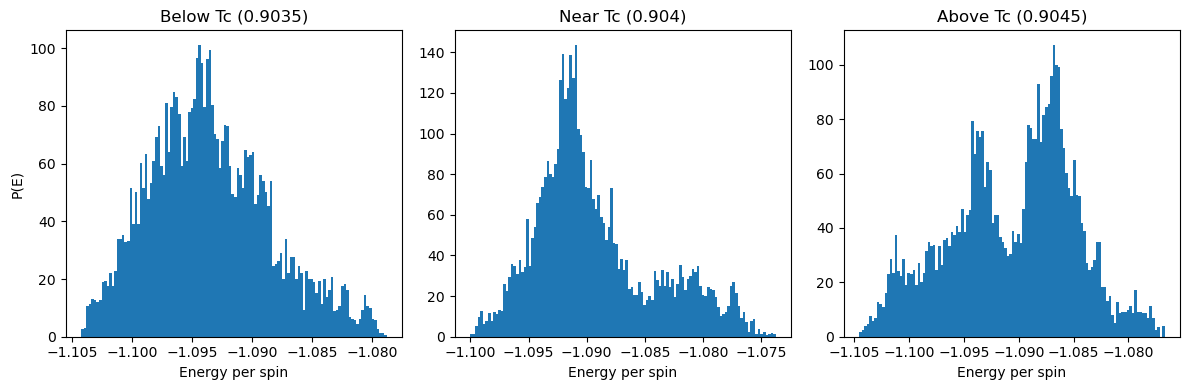

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.random import randint, random

# =========================================================
# PARAMETERS
# =========================================================
L = 256
q = 4
J = 1.0

# VERY narrow temperature window near Tc
T_below = 0.9035
T_crit  = 0.9040
T_above = 0.9045

sweeps = 300000
burn_frac = 0.5
sample_interval = 20

# =========================================================
# INITIAL CONFIGURATION
# =========================================================
def new_state(L, q):
    return np.random.randint(0, q, size=(L, L))

# =========================================================
# EXACT ENERGY
# =========================================================
# IMPORTANT:
# We recompute the FULL energy every sample.
# This fixes histogram distortion.
# =========================================================
def total_energy(spins, J=1.0):

    L = spins.shape[0]

    E = 0

    for x in range(L):
        for y in range(L):

            s = spins[x, y]

            # count each bond once
            right = spins[(x + 1) % L, y]
            up    = spins[x, (y + 1) % L]

            if s == right:
                E -= J

            if s == up:
                E -= J

    return E

# =========================================================
# SPIN COUNTS
# =========================================================
def initial_counts(spins, q):
    return np.bincount(spins.ravel(), minlength=q)

# =========================================================
# WOLFF CLUSTER
# =========================================================
# KEEPING YOUR ORIGINAL WOLFF
# =========================================================
def wolff_cluster(spins, T, counts, q):

    L = spins.shape[0]

    beta = 1.0 / T

    # random seed
    i, j = randint(0, L, size=2)

    seed_state = spins[i, j]

    # choose DIFFERENT state
    new_state_val = randint(0, q - 1)

    if new_state_val >= seed_state:
        new_state_val += 1

    # bond probability
    p = 1 - np.exp(-beta)

    cluster = {(i, j)}
    pocket = {(i, j)}

    while pocket:

        x, y = pocket.pop()

        for dx, dy in [(1,0),(-1,0),(0,1),(0,-1)]:

            nx = (x + dx) % L
            ny = (y + dy) % L

            if (nx, ny) not in cluster:

                if spins[nx, ny] == seed_state:

                    if random() < p:

                        cluster.add((nx, ny))
                        pocket.add((nx, ny))

    # cluster size
    cluster_size = len(cluster)

    # apply flip
    for x, y in cluster:
        spins[x, y] = new_state_val

    # update counts
    counts[seed_state] -= cluster_size
    counts[new_state_val] += cluster_size

    return spins, counts

# =========================================================
# ENERGY HISTOGRAM
# =========================================================
def energy_histogram(
    L,
    T,
    q=5,
    sweeps=300000,
    burn_frac=0.5,
    sample_interval=20
):

    spins = new_state(L, q)

    counts = initial_counts(spins, q)

    burn_steps = int(burn_frac * sweeps)

    N = L * L

    E_samples = []

    for step in range(sweeps):

        spins, counts = wolff_cluster(
            spins,
            T,
            counts,
            q
        )

        # thermalization
        if step < burn_steps:
            continue

        # decorrelation
        if (step - burn_steps) % sample_interval != 0:
            continue

        # =================================================
        # EXACT ENERGY RECOMPUTATION
        # =================================================
        E = total_energy(spins, J)

        # energy per spin
        e = E / N

        E_samples.append(e)

    return np.array(E_samples)

# =========================================================
# RUN SIMULATIONS
# =========================================================
print("Running BELOW Tc...")
E_below = energy_histogram(
    L,
    T_below,
    q,
    sweeps,
    burn_frac,
    sample_interval
)

print("Running NEAR Tc...")
E_crit = energy_histogram(
    L,
    T_crit,
    q,
    sweeps,
    burn_frac,
    sample_interval
)

print("Running ABOVE Tc...")
E_above = energy_histogram(
    L,
    T_above,
    q,
    sweeps,
    burn_frac,
    sample_interval
)

# =========================================================
# SAVE DATA
# =========================================================
np.savez_compressed(
    "q5_energy_histograms_exact.npz",

    E_below=E_below,
    E_crit=E_crit,
    E_above=E_above,

    L=L,
    q=q,

    T_below=T_below,
    T_crit=T_crit,
    T_above=T_above,

    sweeps=sweeps,
    sample_interval=sample_interval
)

print("Exact histogram data saved.")

# =========================================================
# PLOT
# =========================================================
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)

plt.hist(
    E_below,
    bins=120,
    density=True
)

plt.title(f"Below Tc ({T_below})")
plt.xlabel("Energy per spin")
plt.ylabel("P(E)")

# ---------------------------------------------------------

plt.subplot(1,3,2)

plt.hist(
    E_crit,
    bins=120,
    density=True
)

plt.title(f"Near Tc ({T_crit})")
plt.xlabel("Energy per spin")

# ---------------------------------------------------------

plt.subplot(1,3,3)

plt.hist(
    E_above,
    bins=120,
    density=True
)

plt.title(f"Above Tc ({T_above})")
plt.xlabel("Energy per spin")

plt.tight_layout()
plt.show()

Running BELOW Tc...
Running NEAR Tc...
Running ABOVE Tc...
Energy histogram data saved.


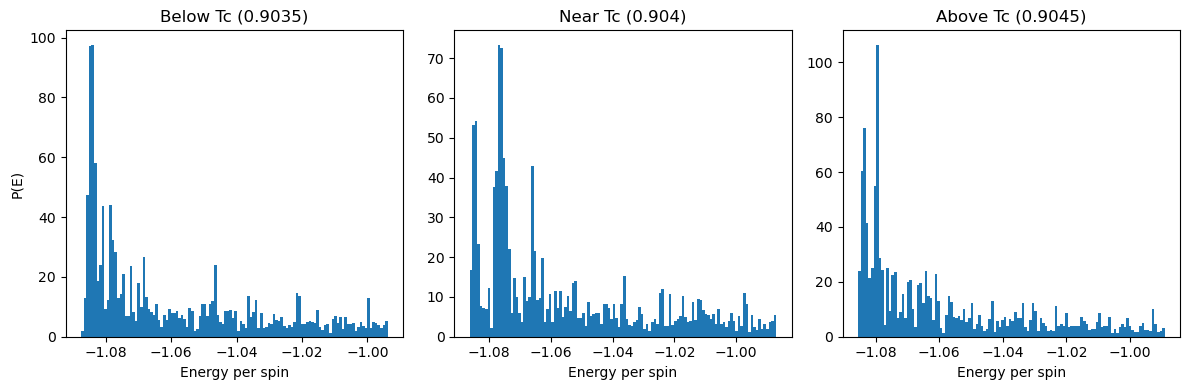

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.random import randint, random

# =========================================================
# PARAMETERS
# =========================================================
L = 256
q = 5
J = 1.0

# VERY narrow temperature window
T_below = 0.9035
T_crit  = 0.9040
T_above = 0.9045

sweeps = 500000
burn_frac = 0.5
sample_interval = 20

# =========================================================
# INITIAL CONFIGURATION
# =========================================================
def new_state(L, q):
    return np.random.randint(0, q, size=(L, L))

# =========================================================
# INITIAL ENERGY
# =========================================================
def initial_energy(spins, J=1.0):

    L = spins.shape[0]

    E = 0

    for x in range(L):
        for y in range(L):

            s = spins[x, y]

            # count each bond once
            for dx, dy in [(1,0), (0,1)]:

                nx = (x + dx) % L
                ny = (y + dy) % L

                if spins[nx, ny] == s:
                    E -= J

    return E

# =========================================================
# SPIN COUNTS
# =========================================================
def initial_counts(spins, q):
    return np.bincount(spins.ravel(), minlength=q)

# =========================================================
# WOLFF CLUSTER WITH ENERGY UPDATE
# =========================================================
def wolff_cluster_fast(spins, T, counts, E_current,
                       J=1.0, q=5):

    L = spins.shape[0]

    beta = 1.0 / T

    # random seed
    i, j = randint(0, L, size=2)

    seed_state = spins[i, j]

    # choose a DIFFERENT Potts state
    new_state_val = randint(0, q - 1)

    if new_state_val >= seed_state:
        new_state_val += 1

    # bond probability
    p = 1 - np.exp(-beta * J)

    cluster = {(i, j)}
    pocket = {(i, j)}

    # =====================================================
    # BUILD CLUSTER
    # =====================================================
    while pocket:

        x, y = pocket.pop()

        for dx, dy in [(1,0), (-1,0), (0,1), (0,-1)]:

            nx = (x + dx) % L
            ny = (y + dy) % L

            if (nx, ny) not in cluster:

                if spins[nx, ny] == seed_state:

                    if random() < p:

                        cluster.add((nx, ny))
                        pocket.add((nx, ny))

    # =====================================================
    # ENERGY CHANGE
    # ONLY BOUNDARY BONDS
    # =====================================================
    dE = 0

    for x, y in cluster:

        for dx, dy in [(1,0), (-1,0), (0,1), (0,-1)]:

            nx = (x + dx) % L
            ny = (y + dy) % L

            # only cluster boundary
            if (nx, ny) not in cluster:

                # OLD bond disappears
                if spins[nx, ny] == seed_state:
                    dE += J

                # NEW bond appears
                if spins[nx, ny] == new_state_val:
                    dE -= J

    # =====================================================
    # APPLY FLIP
    # =====================================================
    cluster_size = len(cluster)

    for x, y in cluster:
        spins[x, y] = new_state_val

    counts[seed_state] -= cluster_size
    counts[new_state_val] += cluster_size

    # update energy
    E_current += dE

    return spins, counts, E_current

# =========================================================
# ENERGY HISTOGRAM COLLECTION
# =========================================================
def energy_histogram(
    L,
    T,
    q=5,
    sweeps=500000,
    burn_frac=0.5,
    sample_interval=20
):

    spins = new_state(L, q)

    counts = initial_counts(spins, q)

    E_current = initial_energy(spins, J)

    burn_steps = int(burn_frac * sweeps)

    N = L * L

    E_samples = []

    for step in range(sweeps):

        spins, counts, E_current = wolff_cluster_fast(
            spins,
            T,
            counts,
            E_current,
            J,
            q
        )

        # thermalization
        if step < burn_steps:
            continue

        # reduce autocorrelation
        if step % sample_interval != 0:
            continue

        # energy per spin
        e = E_current / N

        E_samples.append(e)

    return np.array(E_samples)

# =========================================================
# RUN SIMULATIONS
# =========================================================
print("Running BELOW Tc...")
E_below = energy_histogram(
    L,
    T_below,
    q,
    sweeps,
    burn_frac,
    sample_interval
)

print("Running NEAR Tc...")
E_crit = energy_histogram(
    L,
    T_crit,
    q,
    sweeps,
    burn_frac,
    sample_interval
)

print("Running ABOVE Tc...")
E_above = energy_histogram(
    L,
    T_above,
    q,
    sweeps,
    burn_frac,
    sample_interval
)

# =========================================================
# SAVE DATA
# =========================================================
np.savez_compressed(
    "q5_energy_histograms.npz",

    E_below=E_below,
    E_crit=E_crit,
    E_above=E_above,

    L=L,
    q=q,

    T_below=T_below,
    T_crit=T_crit,
    T_above=T_above,

    sweeps=sweeps,
    sample_interval=sample_interval
)

print("Energy histogram data saved.")

# =========================================================
# PLOT
# =========================================================
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.hist(E_below,
         bins=120,
         density=True)

plt.title(f"Below Tc ({T_below})")
plt.xlabel("Energy per spin")
plt.ylabel("P(E)")

plt.subplot(1,3,2)
plt.hist(E_crit,
         bins=120,
         density=True)

plt.title(f"Near Tc ({T_crit})")
plt.xlabel("Energy per spin")

plt.subplot(1,3,3)
plt.hist(E_above,
         bins=120,
         density=True)

plt.title(f"Above Tc ({T_above})")
plt.xlabel("Energy per spin")

plt.tight_layout()
plt.show()

Running BELOW Tc...
Running NEAR Tc...
Running ABOVE Tc...
Histogram data saved.


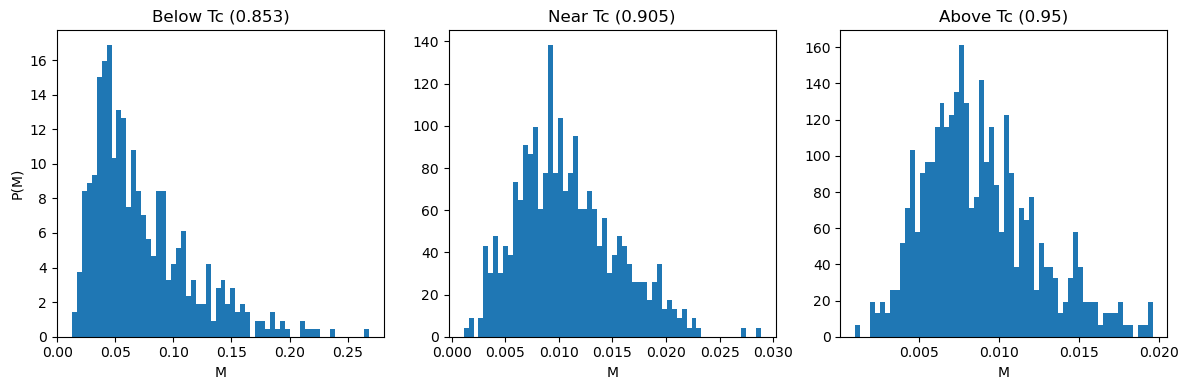

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.random import randint, random

# =========================================================
# PARAMETERS
# =========================================================
L = 256
q = 5

# Your Binder pseudocritical region
T_below = 0.853
T_crit  = 0.905
T_above = 0.950

sweeps = 200000
burn_frac = 0.5

# IMPORTANT:
# avoid oversampling correlated states
sample_interval = 200

# =========================================================
# INITIALIZATION
# =========================================================
def new_state(L, q):
    return np.random.randint(0, q, size=(L, L))

def initial_counts(spins, q):
    return np.bincount(spins.ravel(), minlength=q)

# =========================================================
# VECTOR MAGNETIZATION
# =========================================================
#def magnetization_vector(counts, N, q):

    #probs = counts / N

    #angles = 2 * np.pi * np.arange(q) / q

    #mx = np.sum(probs * np.cos(angles))
    #my = np.sum(probs * np.sin(angles))

    #return mx
def magnetization_potts(counts, N, q):

    nmax = np.max(counts)

    return (q*nmax - N)/((q-1)*N)
# =========================================================
# WOLFF CLUSTER UPDATE
# =========================================================
def wolff_cluster(spins, T, counts, q):

    L = spins.shape[0]

    beta = 1.0 / T

    # random seed
    i, j = randint(0, L, size=2)

    seed_state = spins[i, j]

    # choose different spin state
    new_state_val = randint(0, q - 1)

    if new_state_val >= seed_state:
        new_state_val += 1

    # bond probability
    p = 1 - np.exp(-beta)

    cluster = {(i, j)}
    pocket = {(i, j)}

    while pocket:

        x, y = pocket.pop()

        for dx, dy in [(1,0),(-1,0),(0,1),(0,-1)]:

            nx = (x + dx) % L
            ny = (y + dy) % L

            if (nx, ny) not in cluster:

                if spins[nx, ny] == seed_state:

                    if random() < p:

                        cluster.add((nx, ny))
                        pocket.add((nx, ny))

    # cluster size
    cluster_size = len(cluster)

    # apply flip
    for x, y in cluster:
        spins[x, y] = new_state_val

    # update counts
    counts[seed_state] -= cluster_size
    counts[new_state_val] += cluster_size

    return spins, counts

# =========================================================
# HISTOGRAM COLLECTION
# =========================================================
def magnetization_histogram(
    L,
    T,
    q=5,
    sweeps=400000,
    burn_frac=0.5,
    sample_interval=10
):

    spins = new_state(L, q)

    counts = initial_counts(spins, q)

    burn_steps = int(burn_frac * sweeps)

    N = L * L

    M_samples = []

    for step in range(sweeps):

        spins, counts = wolff_cluster(spins, T, counts, q)

        # thermalization
        if step < burn_steps:
            continue

        # reduce autocorrelation
        if step % sample_interval != 0:
            continue

        M = magnetization_potts(counts, N, q)

        M_samples.append(M)

    return np.array(M_samples)

# =========================================================
# RUN SIMULATIONS
# =========================================================
print("Running BELOW Tc...")
M_below = magnetization_histogram(
    L,
    T_below,
    q,
    sweeps,
    burn_frac,
    sample_interval
)

print("Running NEAR Tc...")
M_crit = magnetization_histogram(
    L,
    T_crit,
    q,
    sweeps,
    burn_frac,
    sample_interval
)

print("Running ABOVE Tc...")
M_above = magnetization_histogram(
    L,
    T_above,
    q,
    sweeps,
    burn_frac,
    sample_interval
)

# =========================================================
# SAVE DATA
# =========================================================
save_dict = {
    "M_below": M_below,
    "M_critical": M_crit,
    "M_above": M_above,
    "L": L,
    "q": q,
    "T_below": T_below,
    "T_crit": T_crit,
    "T_above": T_above,
    "sample_interval": sample_interval,
    "sweeps": sweeps
}

np.savez_compressed(
    "Potts_q5_histograms_fixed.npz",
    **save_dict
)

print("Histogram data saved.")

# =========================================================
# PLOT
# =========================================================
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.hist(M_below, bins=60, density=True)
plt.title(f"Below Tc ({T_below})")
plt.xlabel("M")
plt.ylabel("P(M)")

plt.subplot(1,3,2)
plt.hist(M_crit, bins=60,density=True)
plt.title(f"Near Tc ({T_crit})")
plt.xlabel("M")

plt.subplot(1,3,3)
plt.hist(M_above, bins=60, density=True)
plt.title(f"Above Tc ({T_above})")
plt.xlabel("M")

plt.tight_layout()
plt.show()

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.random import randint, random

# ----------------------------
# Initialize
# ----------------------------
def new_state(L, q):
    return np.random.randint(0, q, size=(L, L))

def initial_counts(spins, q):
    return np.bincount(spins.ravel(), minlength=q)

# ----------------------------
# Vector magnetization
# ----------------------------
#def magnetization_vector(counts, N, q):
    #probs = counts / N
    #angles = 2 * np.pi * np.arange(q) / q
    #mx = np.sum(probs * np.cos(angles))
    #my = np.sum(probs * np.sin(angles))
    #return np.sqrt(mx**2 + my**2)
def magnetization_potts(counts, N, q):

    nmax = np.max(counts)

    return (q*nmax - N)/((q-1)*N)
# ----------------------------
# Wolff cluster (no energy needed)
# ----------------------------
def wolff_cluster(spins, T, counts, q):

    L = spins.shape[0]
    beta = 1.0 / T

    i, j = randint(0, L, size=2)
    seed_state = spins[i, j]

    new_state_val = randint(0, q-1)
    if new_state_val >= seed_state:
        new_state_val += 1

    p = 1 - np.exp(-beta)

    cluster = {(i,j)}
    pocket = {(i,j)}

    while pocket:
        x, y = pocket.pop()
        for dx, dy in [(1,0),(-1,0),(0,1),(0,-1)]:
            nx, ny = (x+dx)%L, (y+dy)%L
            if (nx,ny) not in cluster and spins[nx,ny] == seed_state:
                if random() < p:
                    cluster.add((nx,ny))
                    pocket.add((nx,ny))

    cluster_size = len(cluster)

    for x, y in cluster:
        spins[x,y] = new_state_val

    counts[seed_state] -= cluster_size
    counts[new_state_val] += cluster_size

    return spins, counts

# ----------------------------
# Histogram simulation
# ----------------------------
def magnetization_histogram(L, T, q=5,
                           sweeps=200000,
                           burn_frac=0.3):

    spins = new_state(L, q)
    counts = initial_counts(spins, q)

    burn_steps = int(burn_frac * sweeps)
    N = L * L

    M_samples = []

    for step in range(sweeps):
        spins, counts = wolff_cluster(spins, T, counts, q)

        if step >= burn_steps and step % 5 == 0:
            M = magnetization_potts(counts, N, q)
            M_samples.append(M)

    return np.array(M_samples)

# ----------------------------
# Run at 3 temperatures
# ----------------------------
L = 64
q = 5

# You MUST tune these
T_below = 0.850
T_crit  = 0.905   # adjust using Binder peak
T_above = 0.950

M_below = magnetization_histogram(L, T_below, q)
M_crit  = magnetization_histogram(L, T_crit, q)
M_above = magnetization_histogram(L, T_above, q)
# ----------------------------
# Save histogram data
# ----------------------------
save_dict = {
    "M_below": M_below,
    "M_critical": M_crit,
    "M_above": M_above,
    "L": L,
    "q": q,
    "T_below": T_below,
    "T_crit": T_crit,
    "T_above": T_above
}

np.savez_compressed("Potts_q5.1_histogram_data.npz", **save_dict)

print("Histogram data saved successfully.")


Histogram data saved successfully.


In [3]:
sweeps = 300000
T_c = 0.905
def collect_magnetization_samples(L, T, sweeps=300000, J=1.0, q=5,
                                  burn_frac=0.3, sample_interval=1):

    spins = new_state(L, q)
    counts = initial_counts(spins, q)
    E_current = initial_energy(spins, J)

    burn_steps = int(burn_frac * sweeps)

    N = L * L
    M_samples = []

    for step in range(sweeps):
       
        spins, counts, E_current = wolff_cluster_fast(
            spins, T, counts, E_current, J, q
        )

        if step >= burn_steps and (step - burn_steps) % sample_interval == 0:

            M = magnetization_vector(counts, N, q)
            M_samples.append(M)

    return np.array(M_samples)

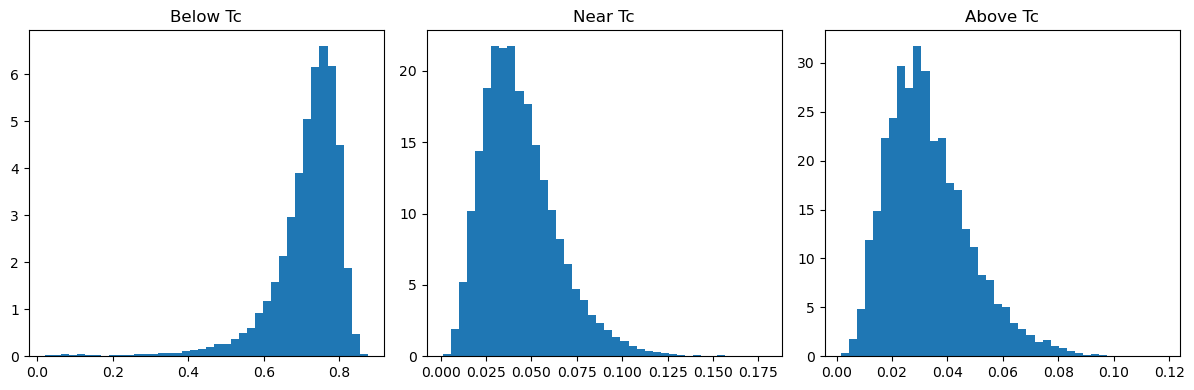

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.hist(M_below, bins=40, density=True)
plt.title("Below Tc")

plt.subplot(1,3,2)
plt.hist(M_crit, bins=40, density=True)
plt.title("Near Tc")

plt.subplot(1,3,3)
plt.hist(M_above, bins=40, density=True)
plt.title("Above Tc")

plt.tight_layout()
plt.show()

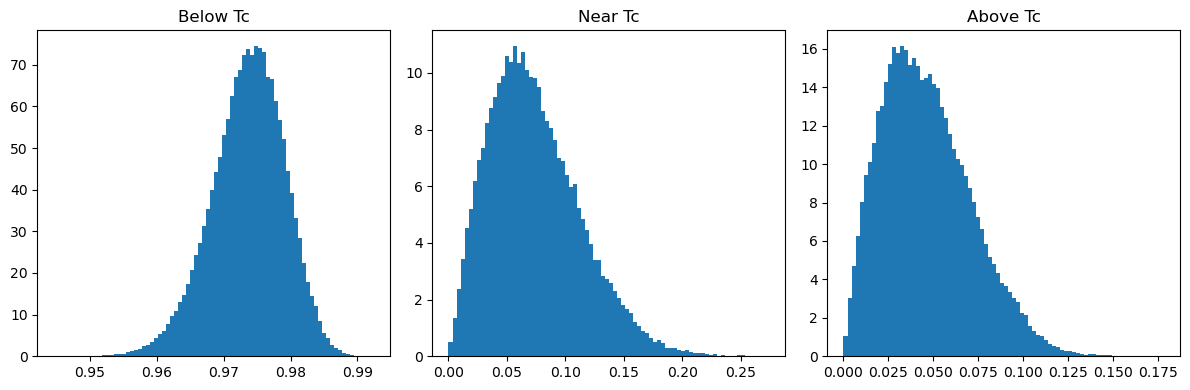

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.hist(M_below, bins=80, density=True)
plt.title("Below Tc")

plt.subplot(1,3,2)
plt.hist(M_crit, bins=80, density=True)
plt.title("Near Tc")

plt.subplot(1,3,3)
plt.hist(M_above, bins=80, density=True)
plt.title("Above Tc")

plt.tight_layout()
plt.show()

In [ ]:
def plot_histogram(M_samples, T, bins=80):

    plt.figure(figsize=(6,4))
    plt.hist(M_samples, bins=bins, density=True, alpha=0.7)

    plt.xlabel("Magnetization |M|")
    plt.ylabel("P(M)")
    plt.title(f"Histogram at T = {T:.4f}")

    plt.grid(True)
    plt.show()